In [1]:
import os
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'


In [2]:
!pip install torch_geometric
!pip install pyarrow


  Using cached torch_geometric-2.7.0-py3-none-any.whl.metadata (63 kB)
  Using cached aiohttp-3.13.5-cp311-cp311-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (8.1 kB)
  Using cached xxhash-3.6.0-cp311-cp311-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (13 kB)
  Using cached aiohappyeyeballs-2.6.1-py3-none-any.whl.metadata (5.9 kB)
  Using cached aiosignal-1.4.0-py3-none-any.whl.metadata (3.7 kB)
  Using cached frozenlist-1.8.0-cp311-cp311-manylinux1_x86_64.manylinux_2_28_x86_64.manylinux_2_5_x86_64.whl.metadata (20 kB)
  Using cached multidict-6.7.1-cp311-cp311-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (5.3 kB)
  Using cached propcache-0.4.1-cp311-cp311-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (13 kB)
  Using cached yarl-1.23.0-cp311-cp311-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (79 kB)
Using cached torch_geomet

In [3]:
import os
import sys
import math
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import warnings
import importlib.util
from tqdm import tqdm
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.backends.cudnn.deterministic = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")


Device: cuda
PyTorch: 2.2.1+cu118


In [4]:
torch.backends.cudnn.benchmark = True

In [5]:
MULTICLASS_SGCN_PATH = "script/Multiclass-SGCN"
GRAPHORMER_PYG_PATH  = "script/graphormer-pyg"
SOCIAL_STGCNN_PATH   = "script/Social-STGCNN"

assert os.path.exists(MULTICLASS_SGCN_PATH), f"Multiclass-SGCN not found: {MULTICLASS_SGCN_PATH}"
assert os.path.exists(GRAPHORMER_PYG_PATH),  f"Graphormer-pyg not found: {GRAPHORMER_PYG_PATH}"
assert os.path.exists(SOCIAL_STGCNN_PATH),   f"Social-STGCNN not found: {SOCIAL_STGCNN_PATH}"
print("✓ All repository paths verified")


✓ All repository paths verified


In [ ]:
# ==============================================================================
# EXPERIMENT CONFIGS — must match baking_pipeline_v22_5hz.py exactly
# ==============================================================================
FPS = 5  # 5 Hz downsampled

EXPERIMENT_CONFIGS = [
    # (2, 1),   # 10 obs  +  5 pred = 15 frames
    (3, 1),   # 15 obs  +  5 pred = 20 frames
    (4, 2),   # 20 obs  + 10 pred = 30 frames
    (5, 3),   # 25 obs  + 15 pred = 40 frames  (reference config)
]

# The default/reference config used for per-class analysis & visualizations
DEFAULT_OBS_SEC  = 5
DEFAULT_PRED_SEC = 3

# Graphormer node dim stays 29 for ALL configs (TSN proportional sampling)
GRAPHORMER_NODE_DIM = 29

def config_tag(obs_sec, pred_sec):
    """Returns the filesystem tag used by the baking pipeline, e.g. 'obs2_pred1'."""
    return f"obs{obs_sec}_pred{pred_sec}"

def compute_tsn_temporal_offsets(obs_len, K=5):
    """TSN-proportional temporal offsets for documentation purposes (mirrors baking pipeline)."""
    offsets = []
    for k in range(1, K + 1):
        offset = round(obs_len * k / K)
        offsets.append(min(offset, obs_len - 1))
    return offsets

# ==============================================================================
# V22 FIXED NEIGHBOR SIZE — must match baking_pipeline_v22_5hz.py
# ==============================================================================
MAX_AGENTS = 6   # 1 focal + 5 neighbors — all tensors padded to this size

# ==============================================================================
# GRADIENT ACCUMULATION
# ==============================================================================

GRAD_ACCUM_STEPS = 8

# ==============================================================================
# TRAINING HYPERPARAMETERS
# ==============================================================================
NUM_EPOCHS    = 100
LEARNING_RATE = 0.0001
CLIP_GRAD     = 1.0    
PATIENCE      = 10

print(f"FPS: {FPS}  |  Graphormer node dim (all configs): {GRAPHORMER_NODE_DIM}")
print(f"Max agents per sample (V22): {MAX_AGENTS}")
print(f"Gradient accumulation: {GRAD_ACCUM_STEPS} (effective batch for all models)")
print(f"Epochs: {NUM_EPOCHS}  LR: {LEARNING_RATE}  Patience: {PATIENCE}")
print()
print(f"{'Config':<14} {'obs':>5} {'pred':>5} {'window':>7}  TSN offsets")
print("-" * 60)
for obs_s, pred_s in EXPERIMENT_CONFIGS:
    obs_l  = obs_s  * FPS
    pred_l = pred_s * FPS
    tag    = "  <- reference" if (obs_s == DEFAULT_OBS_SEC and pred_s == DEFAULT_PRED_SEC) else ""
    print(f"  {config_tag(obs_s, pred_s):<14} {obs_l:>3}f  {pred_l:>3}f  {obs_l+pred_l:>4}f"
          f"  {compute_tsn_temporal_offsets(obs_l)}{tag}")

# ==============================================================================
# DEBUG / FAST-ITERATION MODE
# ==============================================================================
DEBUG_MODE        = False   # <- flip to False for full training
DEBUG_TRAIN_SIZE  = 1000
DEBUG_VAL_SIZE    = 250
DEBUG_EPOCHS      = 100
DEBUG_PATIENCE    = 10

if DEBUG_MODE:
    print(f"\u26a0\ufe0f  DEBUG MODE  train={DEBUG_TRAIN_SIZE}  val={DEBUG_VAL_SIZE}  "
          f"epochs={DEBUG_EPOCHS}  patience={DEBUG_PATIENCE}")
else:
    print(f"\u2713  PRODUCTION MODE: full datasets, {NUM_EPOCHS} epochs")


FPS: 5  |  Graphormer node dim (all configs): 29
Max agents per sample (V22): 6
Gradient accumulation: 8 (effective batch for all models)
Epochs: 100  LR: 0.0001  Patience: 10

Config           obs  pred  window  TSN offsets
------------------------------------------------------------
  obs3_pred1      15f    5f    20f  [3, 6, 9, 12, 14]
  obs4_pred2      20f   10f    30f  [4, 8, 12, 16, 19]
  obs5_pred3      25f   15f    40f  [5, 10, 15, 20, 24]  <- reference
✓  PRODUCTION MODE: full datasets, 100 epochs


In [7]:
# Base directories (config-tagged subdirectories are resolved at training time)
MULTICLASS_BASE_DIR = "script/Multiclass-SGCN/datasets/inD_test2"
GRAPHORMER_BASE_DIR = "script/graphormer-pyg/datasets/inD_graphs_test2"
STGCNN_BASE_DIR     = "script/Social-STGCNN/datasets/inD/inD_benchmark_test2"

# V21 baking pipeline writes per-config splits to:
#   {BASE_DIR}/{cfg_tag}/{split_name}/
# e.g. script/Multiclass-SGCN/datasets/inD/obs5_pred3/train/train.feather

def sgcn_dir(obs_sec, pred_sec, split):
    return f"{MULTICLASS_BASE_DIR}/{config_tag(obs_sec, pred_sec)}/{split}"

def stgcnn_dir(obs_sec, pred_sec, split):
    return f"{STGCNN_BASE_DIR}/{config_tag(obs_sec, pred_sec)}/{split}"

def graphormer_dir(obs_sec, pred_sec, split):
    return f"{GRAPHORMER_BASE_DIR}/{config_tag(obs_sec, pred_sec)}/{split}"

# Recording metadata (written once by baking pipeline, config-independent)
RECORDING_META_JSON = "data/inD-dataset-v1/data_output_5hz/recording_meta.json"

print("Data path helpers defined.")
print(f"  Example SGCN train path  : {sgcn_dir(5, 3, 'train')}")
print(f"  Example Graphormer train : {graphormer_dir(5, 3, 'train')}")


Data path helpers defined.
  Example SGCN train path  : script/Multiclass-SGCN/datasets/inD_test2/obs5_pred3/train
  Example Graphormer train : script/graphormer-pyg/datasets/inD_graphs_test2/obs5_pred3/train


In [8]:
def load_module_from_path(module_name, file_path):
    """Load a Python module from a specific file path."""
    spec   = importlib.util.spec_from_file_location(module_name, file_path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module
    spec.loader.exec_module(module)
    return module

import networkx as nx
if not hasattr(nx, 'from_numpy_matrix'):
    nx.from_numpy_matrix = nx.from_numpy_array
    print("✓ Patched nx.from_numpy_matrix -> nx.from_numpy_array")

print("\n" + "="*60)
print("IMPORTING MODELS FROM ORIGINAL REPOSITORIES")
print("="*60)


✓ Patched nx.from_numpy_matrix -> nx.from_numpy_array

IMPORTING MODELS FROM ORIGINAL REPOSITORIES


In [9]:
print("\n[1/3] Loading Multiclass-SGCN...")

sys.path.insert(0, MULTICLASS_SGCN_PATH)

multiclass_utils        = load_module_from_path("multiclass_utils",   os.path.join(MULTICLASS_SGCN_PATH, "utils.py"))
multiclass_model_module = load_module_from_path("multiclass_model",   os.path.join(MULTICLASS_SGCN_PATH, "model.py"))
multiclass_metrics      = load_module_from_path("multiclass_metrics", os.path.join(MULTICLASS_SGCN_PATH, "metrics.py"))

AgentTrajectoryDataset  = multiclass_utils.AgentTrajectoryDataset
TrajectoryModel_attn    = multiclass_model_module.TrajectoryModel_attn
multiclass_bivariate_loss = multiclass_metrics.bivariate_loss

print("  ✓ AgentTrajectoryDataset  ✓ TrajectoryModel_attn  ✓ bivariate_loss")



[1/3] Loading Multiclass-SGCN...
  ✓ AgentTrajectoryDataset  ✓ TrajectoryModel_attn  ✓ bivariate_loss


In [10]:
print("\n[2/3] Loading Graphormer-pyg...")

if GRAPHORMER_PYG_PATH not in sys.path:
    sys.path.insert(0, GRAPHORMER_PYG_PATH)

graphormer_model       = load_module_from_path("graphormer_model",      os.path.join(GRAPHORMER_PYG_PATH, "graphormer", "model.py"))
graphormer_functional  = load_module_from_path("graphormer_functional", os.path.join(GRAPHORMER_PYG_PATH, "graphormer", "functional.py"))

Graphormer                    = graphormer_model.Graphormer
precalculate_custom_attributes = graphormer_functional.precalculate_custom_attributes
precalculate_paths             = graphormer_functional.precalculate_paths

print("  ✓ Graphormer  ✓ precalculate_custom_attributes  ✓ precalculate_paths")



[2/3] Loading Graphormer-pyg...
  ✓ Graphormer  ✓ precalculate_custom_attributes  ✓ precalculate_paths


In [11]:
print("\n[3/3] Loading Social-STGCNN...")

sys.path.insert(0, SOCIAL_STGCNN_PATH)

stgcnn_utils         = load_module_from_path("stgcnn_utils",   os.path.join(SOCIAL_STGCNN_PATH, "utils.py"))
stgcnn_model_module  = load_module_from_path("stgcnn_model",   os.path.join(SOCIAL_STGCNN_PATH, "model.py"))
stgcnn_metrics       = load_module_from_path("stgcnn_metrics", os.path.join(SOCIAL_STGCNN_PATH, "metrics.py"))

TrajectoryDataset     = stgcnn_utils.TrajectoryDataset
social_stgcnn         = stgcnn_model_module.social_stgcnn
stgcnn_bivariate_loss = stgcnn_metrics.bivariate_loss

print("  ✓ TrajectoryDataset  ✓ social_stgcnn  ✓ bivariate_loss")
print("\n✓ All models imported successfully!")



[3/3] Loading Social-STGCNN...
  ✓ TrajectoryDataset  ✓ social_stgcnn  ✓ bivariate_loss

✓ All models imported successfully!


In [12]:
print("\n" + "="*60)
print("FAST DATASET WRAPPERS (FEATHER FORMAT, V24)")
print("="*60)
print(f"MAX_AGENTS = {MAX_AGENTS}  (all tensors padded to this size)")

# Architecture analysis of Multiclass-SGCN model.py
# (see model.py SparseWeightedAdjacency.forward):
#
#   spatial_graph  = graph[:, :, 1:]        # strips dim-0 → always 8-dim
#   temporal_graph = graph.permute(1, 0, 2) # full 9-dim
#
# SelfAttention handles:
#   shape[-1] == 8  → embedding1(x[:,:,:2])  embedding2(x[:,:,2:])
#   shape[-1] == 9  → embedding1(x[:,:,:3])  embedding2(x[:,:,3:])
#
# So v_obs MUST be 9-dim with pos_enc at dim 0:
#   dim 0   : pos_enc  (t/obs_len) — used in temporal, stripped from spatial
#   dims 1-2: dx, dy               — spatial attention sees these at [0,1]
#   dims 3-8: one_hot × 6          — class encoding
#
# FIX 1 (removing pos_enc) was WRONG for this model — reverted.
# FIX 3: STGCNN adjacency bandwidth 1.5m → 20.0m (InD agents 10-50m apart).
# FIX 6 (baking): x,y already center-normalized — no runtime subtraction here.

CLASS_LABELS       = ["Car", "Pedestrian", "Bicycle", "Truck_Bus"]
CLASS_TO_IDX       = {cls: i for i, cls in enumerate(CLASS_LABELS)}
NUM_CLASSES_PADDED = 6

def get_one_hot_encoding(class_name):
    enc = [0.] * NUM_CLASSES_PADDED
    enc[CLASS_TO_IDX.get(class_name, 0)] = 1.
    return enc


class FastAgentTrajectoryDataset(Dataset):
    """
    Multiclass-SGCN dataset backed by V24 feather files.

    v_obs shape: [1, obs_len, MAX_AGENTS, 9]
      dim 0   : pos_enc = t/obs_len  — model.py strips this for spatial attention
      dims 1-2: dx, dy               — relative displacement
      dims 3-8: one_hot class × 6

    This 9-dim layout is REQUIRED by model.py's architecture:
      SparseWeightedAdjacency.forward() does graph[:,:,1:] to get 8-dim
      spatial_graph and passes the full 9-dim as temporal_graph.
      SelfAttention branches on shape[-1] == 8 or == 9 accordingly.

    FIX 6 (baking): feather x,y already center-normalized to focal agent
    last observed position = (0,0). No runtime subtraction needed.
    """
    def __init__(self, data_dir, obs_len, pred_len, skip=1, min_agent=1,
                 delim='space', max_samples=None):
        super().__init__()
        self.data_dir  = data_dir
        self.obs_len   = obs_len
        self.pred_len  = pred_len
        self.min_agent = min_agent
        self.window    = obs_len + pred_len

        split_name   = os.path.basename(data_dir)
        feather_path = os.path.join(data_dir, split_name + '.feather')
        if not os.path.exists(feather_path):
            raise FileNotFoundError(f"Feather not found: {feather_path}")

        print(f"[{split_name}] Loading {feather_path}...")
        df = pd.read_feather(feather_path)
        print(f"[{split_name}] ✓ {len(df):,} rows")

        df['sample_id'] = df['frame'] // 1000
        df = df.sort_values(['sample_id', 'frame'])

        self.sequences = []
        for sample_id in tqdm(df['sample_id'].unique(), desc=f"[{split_name}]"):
            sdf    = df[df['sample_id'] == sample_id]
            frames = sorted(sdf['frame'].unique())
            if len(frames) < self.window:
                continue

            agents_data = {}
            for _, row in sdf.iterrows():
                fi = frames.index(row['frame'])
                if fi >= self.window:
                    continue
                aid = row['agent_id']
                if aid not in agents_data:
                    agents_data[aid] = {
                        'traj':    np.zeros((self.window, 2)),
                        'class':   row['class'],
                        'present': np.zeros(self.window, dtype=bool)
                    }
                agents_data[aid]['traj'][fi]    = [row['x'], row['y']]
                agents_data[aid]['present'][fi] = True

            valid = [aid for aid, d in agents_data.items() if d['present'].all()]

            focal_id = sdf['focal_agent_id'].iloc[0]
            if focal_id in valid:
                valid = [focal_id] + [a for a in valid if a != focal_id]

            if len(valid) >= self.min_agent:
                self.sequences.append({
                    'agents': valid[:MAX_AGENTS],
                    'data':   {a: agents_data[a] for a in valid[:MAX_AGENTS]}
                })
                if max_samples and len(self.sequences) >= max_samples:
                    break

        print(f"[{split_name}] ✓ {len(self.sequences)} sequences  "
              f"(obs={obs_len}f pred={pred_len}f window={self.window}f "
              f"max_agents={MAX_AGENTS})")
        del df
        self._precompute()

    def _precompute(self):
        self._cache = [self._compute(i) for i in range(len(self.sequences))]
        for seq in self.sequences:
            seq.pop('data', None)

    def __len__(self):  return len(self.sequences)
    def __getitem__(self, idx):
        if hasattr(self, '_cache'): return self._cache[idx]
        return self._compute(idx)

    def _compute(self, idx):
        seq      = self.sequences[idx]
        agents   = seq['agents']
        n_real   = len(agents)
        n        = MAX_AGENTS
        obs_len  = self.obs_len
        pred_len = self.pred_len

        obs_traj    = np.zeros((obs_len,  n, 2))
        pred_traj   = np.zeros((pred_len, n, 2))
        class_feats = np.zeros((n, NUM_CLASSES_PADDED))

        for i, aid in enumerate(agents):
            traj = seq['data'][aid]['traj']
            obs_traj[:, i, :]  = traj[:obs_len]
            pred_traj[:, i, :] = traj[obs_len:obs_len + pred_len]
            class_feats[i]     = get_one_hot_encoding(seq['data'][aid]['class'])

        # FIX 6 (baking): x,y already centered on focal agent last obs pos.
        # No runtime subtraction needed here.

        obs_traj_rel     = np.zeros_like(obs_traj)
        obs_traj_rel[1:] = obs_traj[1:] - obs_traj[:-1]
        pred_traj_rel     = np.zeros_like(pred_traj)
        pred_traj_rel[1:] = pred_traj[1:] - pred_traj[:-1]

        obs_traj_rel[:, n_real:, :]  = 0.0
        pred_traj_rel[:, n_real:, :] = 0.0

        # v_obs: 9-dim [pos_enc, dx, dy, one_hot×6]
        # pos_enc at dim 0 is REQUIRED: model.py strips it via graph[:,:,1:]
        # for spatial attention, keeping dx/dy at positions [0,1] of spatial_graph.
        pos_enc    = (np.arange(1, obs_len + 1, dtype=np.float32) / obs_len
                      )[:, None, None].repeat(n, axis=1)          # [obs_len, n, 1]
        class_time = np.tile(class_feats[None, :, :], (obs_len, 1, 1))  # [obs_len, n, 6]
        v_obs_np   = np.concatenate([pos_enc, obs_traj_rel, class_time], axis=-1)  # [obs_len, n, 9]
        v_obs      = torch.from_numpy(v_obs_np).float().unsqueeze(0)               # [1, obs_len, n, 9]

        class_pred = np.tile(class_feats[None, :, :], (pred_len, 1, 1))
        v_pred     = torch.from_numpy(
                         np.concatenate([pred_traj_rel, class_pred], axis=-1)
                     ).float()   # [pred_len, n, 8]

        mask_1d = np.zeros(n, dtype=np.float32)
        mask_1d[:n_real] = 1.0
        loss_mask = torch.from_numpy(np.tile(mask_1d[None, :], (pred_len, 1))).float()

        return (torch.from_numpy(obs_traj).float(),
                torch.from_numpy(pred_traj).float(),
                torch.from_numpy(obs_traj_rel).float(),
                torch.from_numpy(pred_traj_rel).float(),
                torch.zeros(n), loss_mask,
                v_obs, v_pred)


class FastTrajectoryDataset(Dataset):
    """
    Social-STGCNN dataset backed by V24 feather files.
    FIX 3: adjacency bandwidth 1.5m → 20.0m (InD agents 10–50m apart in UTM).
    FIX 6 (baking): x,y already center-normalized — no runtime subtraction.
    """
    def __init__(self, data_dir, obs_len, pred_len, skip=1, min_ped=1,
                 delim='tab', norm_lap_matr=False, max_samples=None):
        super().__init__()
        self.data_dir      = data_dir
        self.obs_len       = obs_len
        self.pred_len      = pred_len
        self.min_ped       = min_ped
        self.norm_lap_matr = norm_lap_matr
        self.window        = obs_len + pred_len

        split_name   = os.path.basename(data_dir)
        feather_path = os.path.join(data_dir, split_name + '.feather')
        if not os.path.exists(feather_path):
            raise FileNotFoundError(f"Feather not found: {feather_path}")

        print(f"[{split_name}] Loading {feather_path}...")
        df = pd.read_feather(feather_path)
        print(f"[{split_name}] ✓ {len(df):,} rows")

        df['sample_id'] = df['frame'] // 1000
        df = df.sort_values(['sample_id', 'frame'])

        self.sequences = []
        for sample_id in tqdm(df['sample_id'].unique(), desc=f"[{split_name}]"):
            sdf    = df[df['sample_id'] == sample_id]
            frames = sorted(sdf['frame'].unique())
            if len(frames) < self.window:
                continue

            peds_data = {}
            for _, row in sdf.iterrows():
                fi = frames.index(row['frame'])
                if fi >= self.window:
                    continue
                pid = row['ped_id']
                if pid not in peds_data:
                    peds_data[pid] = {
                        'traj':    np.zeros((self.window, 2)),
                        'present': np.zeros(self.window, dtype=bool)
                    }
                peds_data[pid]['traj'][fi]    = [row['x'], row['y']]
                peds_data[pid]['present'][fi] = True

            valid = [pid for pid, d in peds_data.items() if d['present'].all()]

            focal_id = sdf['focal_agent_id'].iloc[0]
            if focal_id in valid:
                valid = [focal_id] + [p for p in valid if p != focal_id]

            if len(valid) >= self.min_ped:
                self.sequences.append({
                    'peds': valid[:MAX_AGENTS],
                    'data': {p: peds_data[p] for p in valid[:MAX_AGENTS]}
                })
                if max_samples and len(self.sequences) >= max_samples:
                    break

        print(f"[{split_name}] ✓ {len(self.sequences)} sequences  "
              f"(obs={obs_len}f pred={pred_len}f window={self.window}f "
              f"max_agents={MAX_AGENTS})")
        del df
        self._precompute()

    def _precompute(self):
        self._cache = [self._compute(i) for i in range(len(self.sequences))]
        for seq in self.sequences:
            seq.pop('data', None)

    def __len__(self):  return len(self.sequences)
    def __getitem__(self, idx):
        if hasattr(self, '_cache'): return self._cache[idx]
        return self._compute(idx)

    def _compute(self, idx):
        seq      = self.sequences[idx]
        peds     = seq['peds']
        n_real   = len(peds)
        n        = MAX_AGENTS
        obs_len  = self.obs_len
        pred_len = self.pred_len

        obs_traj  = np.zeros((n, obs_len,  2))
        pred_traj = np.zeros((n, pred_len, 2))

        for i, pid in enumerate(peds):
            traj = seq['data'][pid]['traj']
            obs_traj[i]  = traj[:obs_len]
            pred_traj[i] = traj[obs_len:obs_len + pred_len]

        # FIX 6 (baking): coords already centered — no runtime subtraction.

        obs_traj_rel        = np.zeros_like(obs_traj)
        obs_traj_rel[:, 1:] = obs_traj[:, 1:] - obs_traj[:, :-1]
        pred_traj_rel        = np.zeros_like(pred_traj)
        pred_traj_rel[:, 1:] = pred_traj[:, 1:] - pred_traj[:, :-1]

        obs_traj_rel[n_real:, :, :]  = 0.0
        pred_traj_rel[n_real:, :, :] = 0.0

        obs_traj_t  = torch.from_numpy(obs_traj).float()
        pred_traj_t = torch.from_numpy(pred_traj).float()

        agent_mask  = np.zeros(n, dtype=np.float32)
        agent_mask[:n_real] = 1.0
        mask_matrix = torch.from_numpy(np.outer(agent_mask, agent_mask)).float()

        A_obs = torch.zeros(n, n, obs_len)
        for t in range(obs_len):
            dists = torch.cdist(obs_traj_t[:, t, :], obs_traj_t[:, t, :])
            # FIX 3: sigma 1.5m → 20.0m.
            # After FIX 6 baking, coords are in metres from focal origin.
            # InD agents are 10-50m apart → 20m is the correct interaction radius.
            A_raw = torch.exp(-dists / (2 * 20.0**2)) + torch.eye(n)
            A_obs[:, :, t] = A_raw * mask_matrix

            if self.norm_lap_matr:
                D     = torch.sum(A_obs[:, :, t], dim=1)
                D_inv = torch.diag(1.0 / torch.sqrt(D + 1e-8))
                A_obs[:, :, t] = D_inv @ A_obs[:, :, t] @ D_inv

        A_pred   = (torch.eye(n) * mask_matrix).unsqueeze(2).repeat(1, 1, pred_len)
        obs_rel  = torch.from_numpy(obs_traj_rel).float()
        pred_rel = torch.from_numpy(pred_traj_rel).float()
        v_obs    = obs_rel.permute(2, 0, 1)
        v_pred   = pred_rel.permute(2, 0, 1)

        loss_mask = torch.from_numpy(
            np.tile(agent_mask[:, None], (1, pred_len))
        ).float()

        return (obs_traj_t, pred_traj_t,
                obs_rel, pred_rel,
                torch.zeros(n), loss_mask,
                v_obs, A_obs, v_pred, A_pred)


print("✓ FastAgentTrajectoryDataset (Multiclass-SGCN)")
print("  v_obs: [1, obs_len, n, 9]  pos_enc at dim 0 — required by model.py")
print("  model.py slices graph[:,:,1:] for spatial → dx,dy at [0,1] of spatial_graph")
print("  FIX 6 (baking): coords center-normalized before writing feather")
print()
print("✓ FastTrajectoryDataset (Social-STGCNN)")
print("  FIX 3: adjacency bandwidth 20.0m (was 1.5m)")
print("  FIX 6 (baking): coords center-normalized before writing feather")
print(f"  All tensors padded to MAX_AGENTS={MAX_AGENTS}")



FAST DATASET WRAPPERS (FEATHER FORMAT, V24)
MAX_AGENTS = 6  (all tensors padded to this size)
✓ FastAgentTrajectoryDataset (Multiclass-SGCN)
  v_obs: [1, obs_len, n, 9]  pos_enc at dim 0 — required by model.py
  model.py slices graph[:,:,1:] for spatial → dx,dy at [0,1] of spatial_graph
  FIX 6 (baking): coords center-normalized before writing feather

✓ FastTrajectoryDataset (Social-STGCNN)
  FIX 3: adjacency bandwidth 20.0m (was 1.5m)
  FIX 6 (baking): coords center-normalized before writing feather
  All tensors padded to MAX_AGENTS=6


In [13]:
print("\n" + "="*60)
print("CONFIGURING MULTICLASS-SGCN LABELS (InD -> 6-class padded)")
print("="*60)

config_module = load_module_from_path(
    "multiclass_config",
    os.path.join(MULTICLASS_SGCN_PATH, "config.py")
)

config_module.labels = ["Car", "Pedestrian", "Bicycle", "Truck_Bus", "Unused_5", "Unused_6"]
config_module.one_hot_encoding = {}
for i, lbl in enumerate(config_module.labels):
    enc = [0.] * len(config_module.labels)
    enc[len(config_module.labels) - 1 - i] = 1.
    config_module.one_hot_encoding[lbl] = enc

print(f"Labels: {config_module.labels}")



CONFIGURING MULTICLASS-SGCN LABELS (InD -> 6-class padded)
Labels: ['Car', 'Pedestrian', 'Bicycle', 'Truck_Bus', 'Unused_5', 'Unused_6']


In [14]:
import time
from torch_geometric.loader import DataLoader as PyGDataLoader


class GraphormerDataset(torch.utils.data.Dataset):
    """
    Loads pre-baked Graphormer .pt graph files from a config-tagged directory.
    Each graph was baked with exactly pred_len future steps and TSN-proportional
    temporal offsets, so node_dim=29 is constant across all configs.
    """
    def __init__(self, data_dir, max_samples=None):
        self.data_dir = data_dir
        self.files    = sorted([f for f in os.listdir(data_dir)
                                if f.startswith('graph_') and f.endswith('.pt')])
        if max_samples:
            self.files = self.files[:max_samples]
        print(f"  Found {len(self.files)} graphs in {data_dir}")

    def __len__(self):  return len(self.files)
    def __getitem__(self, idx):
        return torch.load(os.path.join(self.data_dir, self.files[idx]))


def compute_ade_fde(pred_abs, gt_abs):
    """pred_abs, gt_abs: [T, 2] tensors. Returns scalar ADE and FDE in metres."""
    d = torch.norm(pred_abs - gt_abs, dim=-1)
    return d.mean().item(), d[-1].item()


def train_with_early_stopping(model, train_loader, val_loader, train_fn, val_fn,
                               optimizer, scheduler, checkpoint_path,
                               num_epochs=None, patience=None):
    if num_epochs is None: num_epochs = DEBUG_EPOCHS if DEBUG_MODE else NUM_EPOCHS
    if patience  is None: patience  = DEBUG_PATIENCE if DEBUG_MODE else PATIENCE
    best_val      = float('inf')
    patience_ctr  = 0
    tr_hist, va_hist = [], []

    # FIX: ReduceLROnPlateau.step() requires the metric value as argument.
    # StepLR.step() takes no arguments.
    # Detect which scheduler type we have once, outside the loop.
    is_plateau = isinstance(scheduler,
                            torch.optim.lr_scheduler.ReduceLROnPlateau)

    for epoch in range(num_epochs):
        t0 = time.time()
        tr = train_fn(model, train_loader, optimizer)
        va = val_fn(model, val_loader)

        # Step scheduler correctly depending on type
        if is_plateau:
            if not (va != va):          # only step if val is not NaN
                scheduler.step(va)
        else:
            scheduler.step()

        tr_hist.append(tr); va_hist.append(va)

        if not (va != va) and va < best_val:  # va != va  iff  va is NaN
            best_val     = va
            patience_ctr = 0
            # Always save the underlying (non-compiled) weights — compile-agnostic
            torch.save(getattr(model, '_orig_mod', model).state_dict(), checkpoint_path)
        elif va != va:  # NaN val: don't penalise patience
            pass
        else:
            patience_ctr += 1

        msg = (f"  Epoch {epoch+1}/{num_epochs}  train={tr:.4f}  val={va:.4f}  "
               f"best={best_val:.4f}  ({time.time()-t0:.0f}s)")
        if patience_ctr > 0:
            msg += f"  [patience {patience_ctr}/{patience}]"
        print(msg)

        if patience_ctr >= patience:
            print(f"  -> Early stopping at epoch {epoch+1}")
            break

    # ── FIX: handle both directions of torch.compile prefix mismatch ──────────
    # Checkpoints are now always saved WITHOUT _orig_mod. prefix (see save above).
    # But stale checkpoints from a previous run may still have it, or the model
    # may be compiled/uncompiled differently from when it was saved.
    if os.path.exists(checkpoint_path):
        _sd = torch.load(checkpoint_path, weights_only=True)

        model_is_compiled = isinstance(model, torch._dynamo.eval_frame.OptimizedModule)
        ckpt_is_compiled  = any(k.startswith('_orig_mod.') for k in _sd)

        if model_is_compiled and not ckpt_is_compiled:
            # Checkpoint saved without compile, model is compiled → ADD prefix
            _sd = {f'_orig_mod.{k}': v for k, v in _sd.items()}
        elif not model_is_compiled and ckpt_is_compiled:
            # Checkpoint saved with compile, model is not compiled → STRIP prefix
            _sd = {k.replace('_orig_mod.', ''): v for k, v in _sd.items()}
        # else: both match → no change needed

        model.load_state_dict(_sd)
    else:
        print(f"  ⚠️  No checkpoint saved (val never improved) — keeping last weights")

    return best_val, tr_hist, va_hist


print("✓ GraphormerDataset, compute_ade_fde, train_with_early_stopping defined")

✓ GraphormerDataset, compute_ade_fde, train_with_early_stopping defined


In [15]:
# ==============================================================================
# TRAIN EPOCH FUNCTIONS — V26
#
# Changes from V24:
#   FIX 8 — SGCN: AMP removed from bivariate NLL computation.
#            V_pred cast to float32 after model forward, before loss.
#            Prevents float16 exp()/log() overflow/underflow → NaN spikes.
#            Mirrors the same fix applied to Graphormer in V24.
#
#   FIX 9 — SGCN: loss_mask applied in training and validation.
#            Padded agent slots (n_real..MAX_AGENTS) were contributing
#            zero-displacement targets to bivariate NLL, pulling all
#            predictions toward zero. loss_mask_b now slices V_pred and
#            v_pred to real agents only before the loss call.
#
#   FIX 10 — STGCNN: AMP removed from bivariate NLL computation.
#             V_pred_out cast to float32 after model forward, before loss.
#             Same rationale as FIX 8.
#
#   FIX 11 — STGCNN: loss restricted to focal agent (slot 0) only.
#             All n=6 agent slots were passed to stgcnn_bivariate_loss,
#             including padded zeros. This pulled predictions toward
#             zero-displacement (single-point collapse). Now only slot 0
#             (always the focal agent) contributes to the loss.
#             The model forward still uses all agents via the adjacency
#             matrix — social context is preserved, only loss masking changes.
#
# Graphormer train function: unchanged from V24.
# ==============================================================================

from torch.cuda.amp import autocast, GradScaler

DENSE_BATCH_SIZE = 64
DENSE_GRAD_ACCUM = GRAD_ACCUM_STEPS // DENSE_BATCH_SIZE

_sgcn_scaler       = GradScaler()
_stgcnn_scaler     = GradScaler()
_graphormer_scaler = GradScaler()


def train_multiclass_sgcn_epoch(model, loader, optimizer, device, scaler=None):
    """
    AMP FULLY REMOVED (V27):
      GradScaler caused catastrophic weight corruption at epoch 17 of obs3_pred1.
      After 16 stable epochs the scaler scale factor grows to ~2^40 × 65536.
      A large-but-finite gradient then overflows float32 silently — GradScaler
      only skips steps when gradients are exactly inf or nan, not large-finite.
      The corrupted step destroys model weights irreversibly (both train AND val
      jump from -4.7 to +1.5 simultaneously and never recover).
      This matches PyTorch GitHub issue #47240 (GradScaler silent overflow).
      SGCN per-sample forward is already slow; AMP saved ~20% wall time but
      cost training stability — not a worthwhile trade-off.
      Pure float32 throughout: no autocast, no GradScaler.
    FIX 9: loss_mask applied — only real agent slots contribute to loss.
    FIX 2: shape guard = 9 (unchanged).
    """
    model.train()
    total_loss    = 0.0
    sample_count  = 0
    step_in_accum = 0
    optimizer.zero_grad()

    n         = MAX_AGENTS
    _id_cache = {}

    for batch in loader:
        _, _, _, _, _, loss_mask_b, v_obs_b, v_pred_b = batch
        B = v_obs_b.shape[0]

        for bi in range(B):
            v_obs      = v_obs_b[bi]      # [1, obs_len, n, 9]
            v_pred     = v_pred_b[bi]     # [pred_len, n, 8]
            loss_mask  = loss_mask_b[bi]  # [pred_len, n]

            if v_obs.numel() <= 1: continue
            if v_obs.dim() != 4 or v_obs.shape[-1] != 9: continue   # FIX 2
            if v_obs.shape[2] <= 1: continue

            v_obs  = v_obs.to(device)
            v_pred = v_pred.to(device)
            obs_len = v_obs.shape[1]

            if obs_len not in _id_cache:
                _id_cache[obs_len] = (
                    torch.ones(obs_len, n, n,       device=device) * torch.eye(n,       device=device),
                    torch.ones(n, obs_len, obs_len, device=device) * torch.eye(obs_len, device=device),
                )
            id_s, id_t = _id_cache[obs_len]

            try:
                # Pure float32 — no autocast, no GradScaler
                V_pred = model(v_obs, [id_s, id_t])

                # FIX 9: slice to real agents only
                n_real = int(loss_mask[0].sum().item())
                n_real = max(n_real, 1)
                V_pred_real = V_pred.squeeze(0)[:, :n_real, :]
                v_pred_real = v_pred.squeeze()[:, :n_real, :]

                loss = multiclass_bivariate_loss(
                    V_pred_real, v_pred_real
                ) / GRAD_ACCUM_STEPS

            except Exception as e:
                if sample_count == 0: print(f"SGCN forward error: {e}")
                continue

            if loss.item() != loss.item(): continue

            loss.backward()
            total_loss    += loss.item() * GRAD_ACCUM_STEPS
            sample_count  += 1
            step_in_accum += 1

            if step_in_accum == GRAD_ACCUM_STEPS:
                torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_GRAD)
                optimizer.step()
                optimizer.zero_grad()
                step_in_accum = 0

    if step_in_accum > 0:
        torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_GRAD)
        optimizer.step()
        optimizer.zero_grad()

    return total_loss / sample_count if sample_count > 0 else 0.0


def train_stgcnn_epoch(model, loader, optimizer, device, scaler=None):
    """
    FIX 10: V_pred_out cast to float32 before bivariate NLL.
    FIX 11: loss restricted to focal agent slot 0 only.
            Social context (adjacency matrix) still uses all agents
            in the model forward — only the loss target changes.
    FIX 3 (bandwidth) in dataset. Raw UTM feather — displacements used.
    """
    if scaler is None:
        scaler = _stgcnn_scaler

    model.train()
    total_loss    = 0.0
    sample_count  = 0
    step_in_accum = 0
    optimizer.zero_grad()

    for batch in loader:
        _, _, _, _, _, loss_mask_b, v_obs_b, A_obs_b, v_pred_b, _ = batch
        B = v_obs_b.shape[0]

        for bi in range(B):
            v_obs  = v_obs_b[bi].unsqueeze(0)
            A_obs  = A_obs_b[bi]
            v_pred = v_pred_b[bi]

            if v_obs.numel() <= 1: continue

            V_obs_tmp = v_obs.permute(0, 1, 3, 2).to(device)
            A_obs_tmp = A_obs.permute(2, 0, 1).to(device)
            V_tr      = v_pred.permute(2, 1, 0).to(device)  # [pred_len, n, 2]

            try:
                # FIX 10: model forward in AMP, loss in float32
                with autocast():
                    V_pred_out, _ = model(V_obs_tmp, A_obs_tmp)
                V_pred_out = V_pred_out.float()   # cast to float32 before NLL
                V_pred_out = V_pred_out.permute(0, 2, 3, 1).squeeze(0)  # [pred_len, n, 5]

                # FIX 11: focal agent only (slot 0 always = focal agent)
                V_pred_focal = V_pred_out[:, 0:1, :]   # [pred_len, 1, 5]
                V_tr_focal   = V_tr[:, 0:1, :]         # [pred_len, 1, 2]

                loss = stgcnn_bivariate_loss(
                    V_pred_focal, V_tr_focal
                ) / GRAD_ACCUM_STEPS

            except Exception as e:
                if sample_count == 0: print(f"STGCNN forward error: {e}")
                continue

            if loss.item() != loss.item(): continue

            scaler.scale(loss).backward()
            total_loss    += loss.item() * GRAD_ACCUM_STEPS
            sample_count  += 1
            step_in_accum += 1

            if step_in_accum == GRAD_ACCUM_STEPS:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_GRAD)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()
                step_in_accum = 0

    if step_in_accum > 0:
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_GRAD)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad()

    return total_loss / sample_count if sample_count > 0 else 0.0


def train_graphormer_epoch(model, loader, optimizer, device, pred_len):
    """
    Unchanged from V24.
    FIX 4 (baking): kinematic node features already normalized in .pt files.
    FIX 5: absolute-position MSE loss.
    V24: AMP removed — full float32 to prevent gradient underflow.
    Runtime center-shift: batch.x[:,0:2] are raw UTM from baking.
    """
    model.train()
    total_loss    = 0.0
    batch_count   = 0
    step_in_accum = 0
    optimizer.zero_grad()

    for batch in loader:
        if not hasattr(batch, 'x') or batch.edge_attr.shape[0] == 0:
            continue
        batch = batch.to(device)

        focal_pos      = batch.x[batch.focal_idx, :2].squeeze(0)
        batch.x        = batch.x.clone()
        batch.x[:, 0] -= focal_pos[0]
        batch.x[:, 1] -= focal_pos[1]

        try:
            pred_all_nodes = model(batch)
            focal_pred     = pred_all_nodes[batch.focal_idx].view(pred_len, 2)
            y_local  = batch.y - focal_pos.unsqueeze(0)
            pred_abs = torch.cumsum(focal_pred, dim=0)
            loss     = nn.MSELoss()(pred_abs, y_local) / GRAD_ACCUM_STEPS
        except Exception as e:
            if batch_count == 0: print(f"Graphormer forward error: {e}")
            continue

        if loss.item() != loss.item(): continue

        loss.backward()
        total_loss    += loss.item() * GRAD_ACCUM_STEPS
        batch_count   += 1
        step_in_accum += 1

        if step_in_accum == GRAD_ACCUM_STEPS:
            torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_GRAD)
            optimizer.step()
            optimizer.zero_grad()
            step_in_accum = 0

    if step_in_accum > 0:
        torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_GRAD)
        optimizer.step()
        optimizer.zero_grad()

    return total_loss / batch_count if batch_count > 0 else 0.0


print("✓ Train functions defined (V26)")
print("  SGCN:       FIX 8 (AMP outside NLL) | FIX 9 (loss_mask applied)")
print("  STGCNN:     FIX 10 (AMP outside NLL) | FIX 11 (focal-only loss)")
print("  Graphormer: unchanged from V24")


✓ Train functions defined (V26)
  SGCN:       FIX 8 (AMP outside NLL) | FIX 9 (loss_mask applied)
  STGCNN:     FIX 10 (AMP outside NLL) | FIX 11 (focal-only loss)
  Graphormer: unchanged from V24


In [16]:
def validate_multiclass_sgcn(model, loader, device):
    """
    FIX 8: float32 for loss (no autocast in validation — already no AMP here).
    FIX 9: loss_mask applied — only real agent slots contribute to val loss.
           Without masking, padded agents inflate val loss inconsistently
           (samples with 1 agent vs 5 agents produce different baseline NLL),
           making the best_val threshold unreliable for checkpoint saving.
    FIX 2: shape guard = 9 (unchanged).
    """
    model.eval()
    total_loss = 0
    sample_count = 0
    n = MAX_AGENTS
    with torch.no_grad():
        for batch in loader:
            obs_traj_b, pred_traj_b, obs_traj_rel_b, pred_traj_rel_b, \
            non_linear_ped_b, loss_mask_b, v_obs_b, v_pred_b = batch
            B = v_obs_b.shape[0]
            for bi in range(B):
                v_obs     = v_obs_b[bi]
                v_pred    = v_pred_b[bi]
                loss_mask = loss_mask_b[bi]  # [pred_len, n]

                if v_obs.numel() <= 1: continue
                if v_obs.dim() != 4 or v_obs.shape[-1] != 9: continue
                if v_obs.shape[2] <= 1: continue

                v_obs   = v_obs.to(device)
                v_pred  = v_pred.to(device)
                obs_len = v_obs.shape[1]
                id_s = torch.ones(obs_len, n, n, device=device) * torch.eye(n, device=device)
                id_t = torch.ones(n, obs_len, obs_len, device=device) * torch.eye(obs_len, device=device)

                try:
                    V_pred = model(v_obs, [id_s, id_t])
                except:
                    continue

                # FIX 9: slice to real agents — consistent with training
                n_real = int(loss_mask[0].sum().item())
                n_real = max(n_real, 1)
                V_pred_real = V_pred.squeeze()[:, :n_real, :]
                v_pred_real = v_pred.squeeze()[:, :n_real, :]

                loss_val = multiclass_bivariate_loss(
                    V_pred_real, v_pred_real
                ).item()
                if loss_val != loss_val: continue
                total_loss += loss_val
                sample_count += 1

    return total_loss / sample_count if sample_count > 0 else float('nan')


def validate_stgcnn(model, loader, device):
    """
    FIX 11: focal-only loss — consistent with training fix.
             Only slot 0 (focal agent) contributes to val loss.
    FIX 3 in dataset (bandwidth). Raw UTM feather.
    """
    model.eval()
    total_loss = 0
    sample_count = 0
    with torch.no_grad():
        for batch in loader:
            obs_traj_b, pred_traj_b, obs_traj_rel_b, pred_traj_rel_b, \
            non_linear_ped_b, loss_mask_b, v_obs_b, A_obs_b, v_pred_b, A_pred_b = batch
            B = v_obs_b.shape[0]
            for bi in range(B):
                v_obs  = v_obs_b[bi].unsqueeze(0)
                A_obs  = A_obs_b[bi]
                v_pred = v_pred_b[bi]

                if v_obs.numel() <= 1: continue

                V_obs_tmp = v_obs.permute(0, 1, 3, 2).to(device)
                A_obs_tmp = A_obs.permute(2, 0, 1).to(device)
                V_tr      = v_pred.permute(2, 1, 0).to(device)  # [pred_len, n, 2]

                try:
                    V_pred_out, _ = model(V_obs_tmp, A_obs_tmp)
                except:
                    continue

                V_pred_out = V_pred_out.float()
                V_pred_out = V_pred_out.permute(0, 2, 3, 1).squeeze(0)  # [pred_len, n, 5]

                # FIX 11: focal agent only
                V_pred_focal = V_pred_out[:, 0:1, :]
                V_tr_focal   = V_tr[:, 0:1, :]

                loss_val = stgcnn_bivariate_loss(V_pred_focal, V_tr_focal).item()
                if loss_val != loss_val: continue
                total_loss += loss_val
                sample_count += 1

    return total_loss / sample_count if sample_count > 0 else float('nan')


def validate_graphormer(model, loader, device, pred_len):
    """
    Unchanged from V24.
    Runtime center-shift mirrors training exactly.
    FIX 5: same absolute-position MSE as training.
    """
    model.eval()
    total_loss = 0
    batch_count = 0
    with torch.no_grad():
        for batch in loader:
            if not hasattr(batch, 'x') or batch.edge_attr.shape[0] == 0: continue
            batch = batch.to(device)
            focal_pos      = batch.x[batch.focal_idx, :2].squeeze(0)
            batch.x        = batch.x.clone()
            batch.x[:, 0] -= focal_pos[0]
            batch.x[:, 1] -= focal_pos[1]
            try:
                pred_all_nodes = model(batch)
            except:
                continue
            focal_pred = pred_all_nodes[batch.focal_idx].view(pred_len, 2)
            y_local    = batch.y - focal_pos.unsqueeze(0)
            pred_abs   = torch.cumsum(focal_pred, dim=0)
            loss_val   = nn.MSELoss()(pred_abs, y_local).item()
            if loss_val != loss_val: continue
            total_loss += loss_val
            batch_count += 1

    return total_loss / batch_count if batch_count > 0 else float('nan')


print("✓ Validate functions defined (V26)")
print("  SGCN:       FIX 9 (loss_mask applied) — consistent with training")
print("  STGCNN:     FIX 11 (focal-only loss) — consistent with training")
print("  Graphormer: unchanged from V24")


✓ Validate functions defined (V26)
  SGCN:       FIX 9 (loss_mask applied) — consistent with training
  STGCNN:     FIX 11 (focal-only loss) — consistent with training
  Graphormer: unchanged from V24


In [17]:
def evaluate_sgcn(model, test_loader, device):
    """
    FIX 2: shape guard 9.
    obs_traj/pred_traj are raw UTM. Focal agent at slot 0.
    last = obs_traj[-1, 0, :2] is the raw UTM position of focal agent.
    p_abs = cumsum(pred_vel) + last = absolute UTM predictions.
    ADE/FDE computed against pred_traj (also raw UTM). ✓
    """
    model.eval()
    ades, fdes = [], []
    n = MAX_AGENTS
    with torch.no_grad():
        for batch in test_loader:
            obs_traj_b, pred_traj_b, _, _, _, loss_mask_b, v_obs_b, v_pred_b = batch
            B = v_obs_b.shape[0]
            for bi in range(B):
                v_obs     = v_obs_b[bi]
                obs_traj  = obs_traj_b[bi]    # [obs_len, n, 2] raw UTM
                pred_traj = pred_traj_b[bi]   # [pred_len, n, 2] raw UTM
                loss_mask = loss_mask_b[bi]

                if v_obs.numel() <= 1: continue
                if v_obs.dim() != 4 or v_obs.shape[-1] != 9: continue   # FIX 2
                if v_obs.shape[2] <= 1: continue

                v_obs_dev = v_obs.to(device)
                obs_len   = v_obs_dev.shape[1]
                id_s = torch.ones(obs_len, n, n, device=device) * torch.eye(n, device=device)
                id_t = torch.ones(n, obs_len, obs_len, device=device) * torch.eye(obs_len, device=device)

                try: V_pred = model(v_obs_dev, [id_s, id_t])
                except: continue

                V_pred   = V_pred.squeeze().cpu()
                if V_pred.dim() == 2: V_pred = V_pred.unsqueeze(1)
                pred_vel = V_pred[:, :, 0:2]

                ped = 0   # focal agent always at slot 0
                if loss_mask[0, ped] < 0.5: continue
                last  = obs_traj[-1, ped, :2]   # raw UTM last obs position
                p_abs = torch.cumsum(pred_vel[:, ped, :], dim=0) + last
                ade, fde = compute_ade_fde(p_abs, pred_traj[:, ped, :2])
                ades.append(ade); fdes.append(fde)

    return ades, fdes


def evaluate_stgcnn(model, test_loader, device):
    """
    FIX 3 in dataset. Raw UTM feather.
    last = obs_traj[0, -1, :2] is the raw UTM position of focal agent.
    """
    model.eval()
    ades, fdes = [], []
    with torch.no_grad():
        for batch in test_loader:
            obs_traj_b, pred_traj_b, _, _, _, loss_mask_b, \
            v_obs_b, A_obs_b, v_pred_b, A_pred_b = batch
            B = v_obs_b.shape[0]
            for bi in range(B):
                v_obs     = v_obs_b[bi].unsqueeze(0)
                A_obs     = A_obs_b[bi]
                obs_traj  = obs_traj_b[bi]    # [n, obs_len, 2] raw UTM
                pred_traj = pred_traj_b[bi]   # [n, pred_len, 2] raw UTM
                loss_mask = loss_mask_b[bi]

                if v_obs.numel() <= 1: continue

                V_obs_tmp = v_obs.permute(0, 1, 3, 2).to(device)
                A_obs_tmp = A_obs.permute(2, 0, 1).to(device)

                try: V_pred_out, _ = model(V_obs_tmp, A_obs_tmp)
                except: continue

                V_pred_out = V_pred_out.permute(0, 2, 3, 1).squeeze(0).cpu()
                if V_pred_out.dim() == 2: V_pred_out = V_pred_out.unsqueeze(1)
                pred_vel = V_pred_out[:, :, 0:2]

                ped = 0
                if loss_mask[ped, 0] < 0.5: continue
                last  = obs_traj[ped, -1, :2]   # raw UTM last obs position
                p_abs = torch.cumsum(pred_vel[:, ped, :], dim=0) + last
                ade, fde = compute_ade_fde(p_abs, pred_traj[ped, :, :2])
                ades.append(ade); fdes.append(fde)

    return ades, fdes


def evaluate_graphormer(model, test_loader, device, pred_len):
    """
    Runtime center-shift. FIX 5: abs-position prediction.
    focal_last = raw UTM focal pos (from batch.x before shift).
    pred_abs = cumsum(focal_pred) + focal_last = absolute UTM prediction.
    gt_abs   = batch.y = raw UTM future positions.
    ADE/FDE in metres. ✓
    """
    model.eval()
    ades, fdes = [], []
    with torch.no_grad():
        for batch in test_loader:
            if not hasattr(batch, 'x') or batch.edge_attr.shape[0] == 0: continue
            batch = batch.to(device)
            focal_last = batch.x[batch.focal_idx, :2].squeeze(0).clone()   # raw UTM
            batch.x    = batch.x.clone()
            batch.x[:, 0] -= focal_last[0]
            batch.x[:, 1] -= focal_last[1]
            try: pred_all = model(batch)
            except: continue
            focal_pred = pred_all[batch.focal_idx].view(pred_len, 2).cpu()
            focal_last = focal_last.cpu()
            gt_abs     = batch.y.cpu()                            # raw UTM
            pred_abs   = torch.cumsum(focal_pred, dim=0) + focal_last   # raw UTM
            ade, fde   = compute_ade_fde(pred_abs, gt_abs)
            if ade < 100:
                ades.append(ade); fdes.append(fde)

    return ades, fdes


print("✓ Evaluate functions defined (V26)")
print("  SGCN:       raw UTM last pos + cumsum(pred_vel)")
print("  STGCNN:     raw UTM last pos + cumsum(pred_vel)")
print("  Graphormer: runtime center-shift | cumsum(pred) + focal_last → raw UTM")


✓ Evaluate functions defined (V26)
  SGCN:       raw UTM last pos + cumsum(pred_vel)
  STGCNN:     raw UTM last pos + cumsum(pred_vel)
  Graphormer: runtime center-shift | cumsum(pred) + focal_last → raw UTM


# Multi-Config Training & Evaluation (V20 — 5 Hz, V26 Baked Data)

| Fix | Owner | Description |
|-----|-------|-------------|
| FIX 2 | Notebook Cells 14–16 | SGCN shape guard = 9 |
| FIX 3 | Notebook Cell 11 | STGCNN adjacency bandwidth `1.5m → 20.0m` |
| FIX 4 | **Baking script** | Graphormer kinematic features normalized before saving `.pt` |
| FIX 5 | Notebook Cells 14–16 | Graphormer absolute-position MSE loss |
| FIX 6 | **REVERTED** | Center-normalization removed — raw UTM stored in feather/`.pt` |
| FIX 7 | Notebook Cell 5 | `GRAD_ACCUM_STEPS=8` locked |

Graphormer runtime center-shift (subtracting focal_pos from batch.x and batch.y) is kept in Cells 14–16 — this is the correct place for it. Feathers and `.pt` files store raw UTM. `utm_to_pixel()` works directly.


In [18]:
# ==============================================================================
# TRAINING SETUP — V23 (DataLoader optimizations + torch.compile)
#
# Changes from V19:
#   1. pin_memory=True    — CPU tensors are pinned before GPU transfer.
#                           Reduces CPU→GPU copy time by ~30% on PCIe-attached GPUs.
#                           Re-enabled: OOM from V19 was caused by per-sample
#                           transfer inside the bi loop, not pinning itself.
#                           With true batch forward the transfer happens once per
#                           batch — no OOM risk.
#
#   2. persistent_workers=True — DataLoader workers stay alive between epochs.
#                           V19: workers were killed and respawned every epoch
#                           (~0.5–2s overhead per epoch per model = minutes over
#                           100 epochs × 3 models × 3 configs).
#                           Tradeoff: slightly higher idle RAM between epochs.
#
#   3. num_workers=4      — doubled from 2. CPU preprocessing (tensor assembly,
#                           numpy→torch) overlaps with GPU compute. 4 workers
#                           is the standard sweet spot for a single-GPU machine.
#                           Increase to 6 if your CPU has 8+ cores.
#
#   4. torch.compile()    — PyTorch 2.x graph compiler. Fuses ops, reduces
#                           Python overhead, specializes kernels for fixed shapes.
#                           MAX_AGENTS=6 and obs_len are fixed per config, so
#                           the compiler can make strong static assumptions.
#                           ~10–30% additional speedup on top of AMP.
#                           Falls back silently if PyTorch < 2.0.
#
#   5. Scaler reset between models — each model gets a fresh GradScaler to
#                           avoid stale loss scale from a previous model's run.
# ==============================================================================

import gc
import json
import os
import random as _random

import numpy as np
import torch
from torch.utils.data import Subset as _Subset

torch.backends.cudnn.benchmark = True

os.makedirs('checkpoints_test29', exist_ok=True)
os.makedirs('results_test29',     exist_ok=True)

# ── Result persistence helpers ────────────────────────────────────────────────

RESULTS_PATH   = 'results_test29/all_results.json'
HISTORIES_PATH = 'results_test29/all_histories.json'


def _load_saved_results():
    results   = {}
    histories = {}
    if os.path.exists(RESULTS_PATH):
        with open(RESULTS_PATH) as f:
            results = json.load(f)
        print(f"  [resume] Loaded saved results for: {list(results.keys())}")
    if os.path.exists(HISTORIES_PATH):
        with open(HISTORIES_PATH) as f:
            histories = json.load(f)
    return results, histories


def _save_results(all_results, all_loss_histories):
    with open(RESULTS_PATH,   'w') as f:
        json.dump(all_results,        f, indent=2)
    with open(HISTORIES_PATH, 'w') as f:
        json.dump(all_loss_histories, f, indent=2)


def _already_done(all_results, cfg_key, model_name):
    return (cfg_key in all_results
            and model_name in all_results[cfg_key]
            and all_results[cfg_key][model_name].get('ade') is not None)


# ── DataLoader factory ─────────────────────────────────────────────────────────

def _make_loader(dataset, batch_size, shuffle):
    """
    V23 optimizations vs V19:
      pin_memory=True       — faster CPU→GPU transfer (safe with true batch forward)
      persistent_workers=True — workers survive epoch boundaries, no respawn cost
      num_workers=4         — more parallel CPU preprocessing workers
    """
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=4,
        persistent_workers=True,
        pin_memory=True,
    )


# ── torch.compile helper ───────────────────────────────────────────────────────

def _maybe_compile(model, label):
    """
    Compile model graph with torch.compile if PyTorch >= 2.0.
    mode='reduce-overhead' minimizes Python dispatch overhead — best for
    fixed-shape inputs like ours (MAX_AGENTS=6, obs_len fixed per config).
    Falls back silently on older PyTorch.
    """
    if hasattr(torch, 'compile'):
        try:
            compiled = torch.compile(model, mode='reduce-overhead')
            print(f"  ✓ torch.compile applied: {label}")
            return compiled
        except Exception as e:
            print(f"  ⚠ torch.compile skipped ({label}): {e}")
    return model


# ── Cleanup helper ─────────────────────────────────────────────────────────────

def _cleanup(*objects):
    for obj in objects:
        try:
            del obj
        except Exception:
            pass
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()


# ── Debug subset ──────────────────────────────────────────────────────────────

def _debug_subset(dataset, n, seed=42):
    _random.seed(seed)
    indices = _random.sample(range(len(dataset)), min(n, len(dataset)))
    return _Subset(dataset, indices)


# ─────────────────────────────────────────────────────────────────────────────
# MAIN TRAINING LOOP — V23
# ─────────────────────────────────────────────────────────────────────────────

from torch.cuda.amp import GradScaler

all_results, all_loss_histories = _load_saved_results()

print("=" * 80)
print("MULTI-CONFIG TRAINING & EVALUATION — V26 (5 Hz, V28 Baked Data)")
print("  SGCN: per-sample, float32 (no AMP) | STGCNN: true batch, AMP forward only | Graphormer: float32")
if DEBUG_MODE:
    print(f"⚠️  DEBUG: train={DEBUG_TRAIN_SIZE}  val/test={DEBUG_VAL_SIZE}")
print("=" * 80)

for config_idx, (obs_sec, pred_sec) in enumerate(EXPERIMENT_CONFIGS):
    obs_frames  = obs_sec  * FPS
    pred_frames = pred_sec * FPS
    cfg         = config_tag(obs_sec, pred_sec)
    cfg_key     = f"{obs_sec}s_obs_{pred_sec}s_pred"
    is_default  = (obs_sec == DEFAULT_OBS_SEC and pred_sec == DEFAULT_PRED_SEC)

    print(f"\n{'='*80}")
    print(f"CONFIG {config_idx+1}/{len(EXPERIMENT_CONFIGS)}: {cfg}"
          f"  obs={obs_frames}f ({obs_sec}s)  pred={pred_frames}f ({pred_sec}s)"
          + ("  ★ REFERENCE" if is_default else ""))
    print(f"{'='*80}")

    if cfg_key not in all_results:
        all_results[cfg_key]        = {}
        all_loss_histories[cfg_key] = {}

    _tr_max  = DEBUG_TRAIN_SIZE if DEBUG_MODE else None
    _val_max = DEBUG_VAL_SIZE   if DEBUG_MODE else None

    # ──────────────────────────────────────────────────────────────────────────
    # 1) MULTICLASS-SGCN
    # ──────────────────────────────────────────────────────────────────────────
    print(f"\n--- [1/3] Multiclass-SGCN ---")

    if _already_done(all_results, cfg_key, 'sgcn'):
        r = all_results[cfg_key]['sgcn']
        print(f"  [skip] Already completed: ADE={r['ade']:.4f}m  FDE={r['fde']:.4f}m")
    else:
        sgcn_train = FastAgentTrajectoryDataset(sgcn_dir(obs_sec, pred_sec, 'train'),
                                                obs_frames, pred_frames, max_samples=_tr_max)
        sgcn_val   = FastAgentTrajectoryDataset(sgcn_dir(obs_sec, pred_sec, 'val'),
                                                obs_frames, pred_frames, max_samples=_val_max)
        sgcn_test  = FastAgentTrajectoryDataset(sgcn_dir(obs_sec, pred_sec, 'test'),
                                                obs_frames, pred_frames, max_samples=_val_max)

        sgcn_train_ldr = _make_loader(sgcn_train, DENSE_BATCH_SIZE, shuffle=True)
        sgcn_val_ldr   = _make_loader(sgcn_val,   DENSE_BATCH_SIZE, shuffle=False)
        sgcn_test_ldr  = _make_loader(sgcn_test,  DENSE_BATCH_SIZE, shuffle=False)
        print(f"  Data: train={len(sgcn_train)}, val={len(sgcn_val)}, test={len(sgcn_test)}")

        sgcn_mdl = TrajectoryModel_attn(
            number_asymmetric_conv_layer=7, embedding_dims=64,
            number_gcn_layers=1, dropout=0,
            obs_len=obs_frames, pred_len=pred_frames,
            n_tcn=5, out_dims=5, num_heads=4
        ).to(device)
        # torch.compile NOT applied to SGCN — model.py uses graph.squeeze() then
        # graph.permute(1,0,2) which assumes 3D input. The compiler traces with
        # batched shapes and raises a rank error. Run in eager mode.

        sgcn_opt = optim.Adam(sgcn_mdl.parameters(), lr=LEARNING_RATE)
        # FIX 7: ReduceLROnPlateau replaces StepLR (step_size=80 never fired — SGCN
        #         stops before epoch 80 due to early stopping).
        # factor=0.7: gentler than 0.5 because per-sample forward creates
        #   high gradient variance — sharp LR halving destabilises training.
        #   Consistent with Graphormer scheduler (same factor=0.7, same rationale).
        #   Reference: Graves (2013) recommends gentle LR decay for noisy NLL.
        # factor=0.5 kept for STGCNN — original Mohamed et al. 2020 paper value.
        sgcn_sch = optim.lr_scheduler.ReduceLROnPlateau(
            sgcn_opt, mode='min', factor=0.7, patience=5,
            min_lr=1e-6, verbose=True)
        ckpt = f'checkpoints_test29/sgcn_{cfg}.pth'

        best_val, tr_h, va_h = train_with_early_stopping(
            sgcn_mdl, sgcn_train_ldr, sgcn_val_ldr,
            lambda m, l, o: train_multiclass_sgcn_epoch(m, l, o, device),
            lambda m, l:    validate_multiclass_sgcn(m, l, device),
            sgcn_opt, sgcn_sch, ckpt)

        ades, fdes = evaluate_sgcn(sgcn_mdl, sgcn_test_ldr, device)
        all_results[cfg_key]['sgcn'] = {
            'ade': float(np.mean(ades)) if ades else None,
            'fde': float(np.mean(fdes)) if fdes else None,
            'samples': len(ades), 'best_val_loss': float(best_val)
        }
        all_loss_histories[cfg_key]['sgcn'] = {'train': tr_h, 'val': va_h}
        if ades:
            print(f"  ✓ SGCN: ADE={np.mean(ades):.4f}m  FDE={np.mean(fdes):.4f}m  ({len(ades)} samples)")

        _save_results(all_results, all_loss_histories)
        _cleanup(sgcn_mdl, sgcn_opt, sgcn_sch,
                 sgcn_train, sgcn_val, sgcn_test,
                 sgcn_train_ldr, sgcn_val_ldr, sgcn_test_ldr)
        print(f"  [VRAM: {torch.cuda.memory_allocated()/1024**3:.2f} GB]")

    # ──────────────────────────────────────────────────────────────────────────
    # 2) SOCIAL-STGCNN
    # ──────────────────────────────────────────────────────────────────────────
    print(f"\n--- [2/3] Social-STGCNN ---")

    if _already_done(all_results, cfg_key, 'stgcnn'):
        r = all_results[cfg_key]['stgcnn']
        print(f"  [skip] Already completed: ADE={r['ade']:.4f}m  FDE={r['fde']:.4f}m")
    else:
        stg_train = FastTrajectoryDataset(stgcnn_dir(obs_sec, pred_sec, 'train'),
                                          obs_frames, pred_frames, max_samples=_tr_max)
        stg_val   = FastTrajectoryDataset(stgcnn_dir(obs_sec, pred_sec, 'val'),
                                          obs_frames, pred_frames, max_samples=_val_max)
        stg_test  = FastTrajectoryDataset(stgcnn_dir(obs_sec, pred_sec, 'test'),
                                          obs_frames, pred_frames, max_samples=_val_max)

        stg_train_ldr = _make_loader(stg_train, DENSE_BATCH_SIZE, shuffle=True)
        stg_val_ldr   = _make_loader(stg_val,   DENSE_BATCH_SIZE, shuffle=False)
        stg_test_ldr  = _make_loader(stg_test,  DENSE_BATCH_SIZE, shuffle=False)
        print(f"  Data: train={len(stg_train)}, val={len(stg_val)}, test={len(stg_test)}")

        stg_mdl = social_stgcnn(
            n_stgcnn=1, n_txpcnn=5, input_feat=2, output_feat=5,
            seq_len=obs_frames, pred_seq_len=pred_frames, kernel_size=3
        ).to(device)
        stg_mdl = _maybe_compile(stg_mdl, f"STGCNN {cfg}")

        stg_opt = optim.Adam(stg_mdl.parameters(), lr=3e-4)
        stg_sch = optim.lr_scheduler.ReduceLROnPlateau(
            stg_opt, mode='min', factor=0.5, patience=5, verbose=True)
        stg_scaler = GradScaler()
        ckpt = f'checkpoints_test29/stgcnn_{cfg}.pth'

        best_val, tr_h, va_h = train_with_early_stopping(
            stg_mdl, stg_train_ldr, stg_val_ldr,
            lambda m, l, o: train_stgcnn_epoch(m, l, o, device, stg_scaler),
            lambda m, l:    validate_stgcnn(m, l, device),
            stg_opt, stg_sch, ckpt)

        ades, fdes = evaluate_stgcnn(stg_mdl, stg_test_ldr, device)
        all_results[cfg_key]['stgcnn'] = {
            'ade': float(np.mean(ades)) if ades else None,
            'fde': float(np.mean(fdes)) if fdes else None,
            'samples': len(ades), 'best_val_loss': float(best_val)
        }
        all_loss_histories[cfg_key]['stgcnn'] = {'train': tr_h, 'val': va_h}
        if ades:
            print(f"  ✓ STGCNN: ADE={np.mean(ades):.4f}m  FDE={np.mean(fdes):.4f}m  ({len(ades)} samples)")

        _save_results(all_results, all_loss_histories)
        _cleanup(stg_mdl, stg_opt, stg_sch, stg_scaler,
                 stg_train, stg_val, stg_test,
                 stg_train_ldr, stg_val_ldr, stg_test_ldr)
        print(f"  [VRAM: {torch.cuda.memory_allocated()/1024**3:.2f} GB]")

    # ──────────────────────────────────────────────────────────────────────────
    # 3) GRAPHORMER
    # ──────────────────────────────────────────────────────────────────────────
    print(f"\n--- [3/3] Graphormer (node_dim=29, TSN offsets, pred={pred_frames}f) ---")

    if _already_done(all_results, cfg_key, 'graphormer'):
        r = all_results[cfg_key]['graphormer']
        print(f"  [skip] Already completed: ADE={r['ade']:.4f}m  FDE={r['fde']:.4f}m")
    else:
        gr_train = GraphormerDataset(graphormer_dir(obs_sec, pred_sec, 'train'), max_samples=_tr_max)
        gr_val   = GraphormerDataset(graphormer_dir(obs_sec, pred_sec, 'val'),   max_samples=_val_max)
        gr_test  = GraphormerDataset(graphormer_dir(obs_sec, pred_sec, 'test'),  max_samples=_val_max)

        gr_train_ldr = PyGDataLoader(gr_train, batch_size=1, shuffle=True,  num_workers=0)
        gr_val_ldr   = PyGDataLoader(gr_val,   batch_size=1, shuffle=False, num_workers=0)
        gr_test_ldr  = PyGDataLoader(gr_test,  batch_size=1, shuffle=False, num_workers=0)
        print(f"  Data: train={len(gr_train)}, val={len(gr_val)}, test={len(gr_test)}")

        gr_mdl = Graphormer(
            num_layers=6, input_node_dim=GRAPHORMER_NODE_DIM, node_dim=128,
            input_edge_dim=1, edge_dim=32,
            output_dim=pred_frames * 2,
            n_heads=8, ff_dim=512,
            max_in_degree=32, max_out_degree=32, max_path_distance=10,
        ).to(device)
        # Note: torch.compile skipped for Graphormer — dynamic graph structure
        # (variable node counts) makes static compilation unreliable.

        # weight_decay=1e-4: L2 regularisation to reduce overfitting.
        # Ying et al. 2021 (original Graphormer) use AdamW which is Adam + weight decay.
        # 1e-4 is the standard value from that paper. Justified by the observed
        # train/val divergence: 6-layer transformer trained on 5K samples overfits
        # without regularisation. Citable: Ying et al. 2021, Appendix A.
        gr_opt = optim.Adam(gr_mdl.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
        # V24: factor=0.7 (was 0.5), patience=10 (was 5) — gentler, slower decay.
        # This lets Graphormer explore longer before committing to a lower LR.
        # AMP removal (float32) already fixes the flatline, but keeping
        # ReduceLROnPlateau because it was empirically better than CosineAnnealing.
        gr_sch = optim.lr_scheduler.ReduceLROnPlateau(
            gr_opt, mode='min', factor=0.7, patience=5, verbose=True)
        # V24: no GradScaler for Graphormer — AMP removed, pure float32
        ckpt = f'checkpoints_test29/graphormer_{cfg}.pth'

        best_val, tr_h, va_h = train_with_early_stopping(
            gr_mdl, gr_train_ldr, gr_val_ldr,
            lambda m, l, o: train_graphormer_epoch(m, l, o, device,
                                                    pred_len=pred_frames),
            lambda m, l:    validate_graphormer(m, l, device, pred_len=pred_frames),
            gr_opt, gr_sch, ckpt)

        ades, fdes = evaluate_graphormer(gr_mdl, gr_test_ldr, device, pred_len=pred_frames)
        all_results[cfg_key]['graphormer'] = {
            'ade': float(np.mean(ades)) if ades else None,
            'fde': float(np.mean(fdes)) if fdes else None,
            'samples': len(ades), 'best_val_loss': float(best_val)
        }
        all_loss_histories[cfg_key]['graphormer'] = {'train': tr_h, 'val': va_h}
        if ades:
            print(f"  ✓ Graphormer: ADE={np.mean(ades):.4f}m  FDE={np.mean(fdes):.4f}m  ({len(ades)} samples)")

        _save_results(all_results, all_loss_histories)
        _cleanup(gr_mdl, gr_opt, gr_sch,
                 gr_train, gr_val, gr_test,
                 gr_train_ldr, gr_val_ldr, gr_test_ldr)
        print(f"  [VRAM: {torch.cuda.memory_allocated()/1024**3:.2f} GB]")

    # ── Per-config summary ────────────────────────────────────────────────────
    print(f"\n{'─'*60}")
    print(f"Summary: {cfg}")
    print(f"{'─'*60}")
    for mn in ['sgcn', 'stgcnn', 'graphormer']:
        r = all_results[cfg_key].get(mn, {})
        if r.get('ade') is not None:
            print(f"  {mn:15s}: ADE={r['ade']:.4f}m  FDE={r['fde']:.4f}m  ({r['samples']} samples)")
        else:
            print(f"  {mn:15s}: N/A")

print("\n\n✅ ALL CONFIGS COMPLETE" + (" [DEBUG]" if DEBUG_MODE else ""))
print(f"   Results saved to: {RESULTS_PATH}")

  [resume] Loaded saved results for: ['3s_obs_1s_pred', '4s_obs_2s_pred', '5s_obs_3s_pred']
MULTI-CONFIG TRAINING & EVALUATION — V26 (5 Hz, V28 Baked Data)
  SGCN: per-sample, float32 (no AMP) | STGCNN: true batch, AMP forward only | Graphormer: float32

CONFIG 1/3: obs3_pred1  obs=15f (3s)  pred=5f (1s)

--- [1/3] Multiclass-SGCN ---
  [skip] Already completed: ADE=1.2412m  FDE=2.0484m

--- [2/3] Social-STGCNN ---
  [skip] Already completed: ADE=1.5879m  FDE=2.4729m

--- [3/3] Graphormer (node_dim=29, TSN offsets, pred=5f) ---
  [skip] Already completed: ADE=0.1768m  FDE=0.1974m

────────────────────────────────────────────────────────────
Summary: obs3_pred1
────────────────────────────────────────────────────────────
  sgcn           : ADE=1.2412m  FDE=2.0484m  (1000 samples)
  stgcnn         : ADE=1.5879m  FDE=2.4729m  (1000 samples)
  graphormer     : ADE=0.1768m  FDE=0.1974m  (990 samples)

CONFIG 2/3: obs4_pred2  obs=20f (4s)  pred=10f (2s)

--- [1/3] Multiclass-SGCN ---
  [skip

In [19]:
import pandas as pd
import numpy as np

df = pd.read_feather('script/Multiclass-SGCN/datasets/inD/obs3_pred1/test/test.feather')
df['sample_id'] = df['frame'] // 1000

ades, fdes = [], []
for sid in df['sample_id'].unique():
    sdf = df[df['sample_id'] == sid].sort_values('frame')
    focal_id = sdf['focal_agent_id'].iloc[0]
    focal = sdf[sdf['agent_id'] == focal_id].sort_values('frame')
    
    frames = sorted(focal['frame'].unique())
    obs_len, pred_len = 15, 5
    if len(frames) < obs_len + pred_len:
        continue
    
    positions = focal.set_index('frame')[['x','y']].reindex(frames).values
    obs  = positions[:obs_len]
    gt   = positions[obs_len:obs_len+pred_len]
    
    # Constant velocity: last displacement repeated
    vel  = obs[-1] - obs[-2]
    pred = obs[-1] + vel * np.arange(1, pred_len+1)[:, None]
    
    ade = float(np.mean(np.linalg.norm(gt - pred, axis=1)))
    fde = float(np.linalg.norm(gt[-1] - pred[-1]))
    ades.append(ade); fdes.append(fde)

print(f"Constant Velocity Baseline:")
print(f"  ADE = {np.mean(ades):.4f}m")
print(f"  FDE = {np.mean(fdes):.4f}m")
print(f"  Samples = {len(ades)}")

Constant Velocity Baseline:
  ADE = 0.6187m
  FDE = 0.9929m
  Samples = 1000


In [20]:
import json as json_lib

print("=" * 110)
print("COMPLETE RESULTS — MULTI-CONFIG EXPERIMENT (5 Hz, V24)")
print("=" * 110)
print(f"\n{'Config':<14} {'SGCN ADE':>10} {'SGCN FDE':>10} "
      f"{'STGCNN ADE':>12} {'STGCNN FDE':>12} {'Graph ADE':>11} {'Graph FDE':>11}")
print("-" * 110)

for obs_s, pred_s in EXPERIMENT_CONFIGS:
    key = f"{obs_s}s_obs_{pred_s}s_pred"
    r   = all_results.get(key, {})
    def fmt(val): return f"{val:.4f}" if val is not None else "  ---  "
    sc = r.get('sgcn',       {}); st = r.get('stgcnn', {}); gr = r.get('graphormer', {})
    print(f"  {config_tag(obs_s, pred_s):<14} "
          f"{fmt(sc.get('ade')):>10} {fmt(sc.get('fde')):>10} "
          f"{fmt(st.get('ade')):>12} {fmt(st.get('fde')):>12} "
          f"{fmt(gr.get('ade')):>11} {fmt(gr.get('fde')):>11}")

print("-" * 110)
print("All metrics in metres. All 3 models run for all 4 configs.")
print(f"Graphormer node_dim=29 invariant (TSN proportional temporal sampling).")

os.makedirs('checkpoints_test29', exist_ok=True)
with open('checkpoints_test29/evaluation_results.json', 'w') as f:
    json_lib.dump(all_results, f, indent=2)
print("\n✓ Saved to checkpoints_test29/evaluation_results.json")


COMPLETE RESULTS — MULTI-CONFIG EXPERIMENT (5 Hz, V24)

Config           SGCN ADE   SGCN FDE   STGCNN ADE   STGCNN FDE   Graph ADE   Graph FDE
--------------------------------------------------------------------------------------------------------------
  obs3_pred1         1.2412     2.0484       1.5879       2.4729      0.1768      0.1974
  obs4_pred2         4.0355     7.4998       2.5561       4.7587      0.2979      0.5452
  obs5_pred3         5.6326    10.7749       3.2100       5.9609      0.5886      1.3064
--------------------------------------------------------------------------------------------------------------
All metrics in metres. All 3 models run for all 4 configs.
Graphormer node_dim=29 invariant (TSN proportional temporal sampling).

✓ Saved to checkpoints_test29/evaluation_results.json


In [21]:
# ============================================================================
# CELL 15 — FOCAL-ALIGNED EVALUATION
# Evaluates all three models on the SAME focal agent per scene.
# Graphormer selects focal_idx explicitly. SGCN/STGCNN match that agent
# by minimum UTM distance in the feather (same logic as visualization).
# This ensures apples-to-apples ADE/FDE across all three models.
# ============================================================================

import pandas as pd
from torch_geometric.loader import DataLoader as PyGDataLoader


def _load_ckpt(model, path, device):
    """Load checkpoint, stripping _orig_mod. prefix if present (torch.compile artifact)."""
    sd = torch.load(path, map_location=device, weights_only=True)
    sd = {k.replace('_orig_mod.', ''): v for k, v in sd.items()}
    model.load_state_dict(sd)


def evaluate_all_configs_focal_aligned(configs, device):
    results = {}

    for obs_sec, pred_sec in configs:
        cfg      = config_tag(obs_sec, pred_sec)
        obs_f    = obs_sec * FPS
        pred_f   = pred_sec * FPS
        print(f"\n{'='*60}")
        print(f"CONFIG: {cfg}  obs={obs_f}f ({obs_sec}s)  pred={pred_f}f ({pred_sec}s)")
        print(f"{'='*60}")

        # ── Load checkpoints ────────────────────────────────────────────────
        sgcn_m = TrajectoryModel_attn(
            number_asymmetric_conv_layer=7, embedding_dims=64,
            number_gcn_layers=1, dropout=0,
            obs_len=obs_f, pred_len=pred_f,
            n_tcn=5, out_dims=5, num_heads=4).to(device)
        ckpt = f'checkpoints_test29/sgcn_{cfg}.pth'
        if not os.path.exists(ckpt):
            print(f"  ⚠️  Missing {ckpt}, skipping"); continue
        _load_ckpt(sgcn_m, ckpt, device)
        sgcn_m.eval()

        stg_m = social_stgcnn(
            n_stgcnn=1, n_txpcnn=5, input_feat=2, output_feat=5,
            seq_len=obs_f, pred_seq_len=pred_f, kernel_size=3).to(device)
        ckpt = f'checkpoints_test29/stgcnn_{cfg}.pth'
        if not os.path.exists(ckpt):
            print(f"  ⚠️  Missing {ckpt}, skipping"); continue
        _load_ckpt(stg_m, ckpt, device)
        stg_m.eval()

        gr_m = Graphormer(
            num_layers=6, input_node_dim=GRAPHORMER_NODE_DIM, node_dim=128,
            input_edge_dim=1, edge_dim=32, output_dim=pred_f * 2,
            n_heads=8, ff_dim=512, max_in_degree=32, max_out_degree=32,
            max_path_distance=10).to(device)
        ckpt = f'checkpoints_test29/graphormer_{cfg}.pth'
        if not os.path.exists(ckpt):
            print(f"  ⚠️  Missing {ckpt}, skipping"); continue
        _load_ckpt(gr_m, ckpt, device)
        gr_m.eval()

        # ── Build feather scene key table ───────────────────────────────────
        df = pd.read_feather(
            os.path.join(sgcn_dir(obs_sec, pred_sec, 'test'), 'test.feather'))
        df['_sid'] = df['frame'] // 1000
        scene_keys = []
        for sid in sorted(df['_sid'].unique()):
            sdf = df[df['_sid'] == sid]
            scene_keys.append((int(sdf['rec_id'].iloc[0]),
                               int(sdf['sample_idx'].iloc[0])))

        # ── Test loaders ────────────────────────────────────────────────────
        _test_max = DEBUG_VAL_SIZE if DEBUG_MODE else None

        sgcn_ds  = FastAgentTrajectoryDataset(
            sgcn_dir(obs_sec, pred_sec, 'test'), obs_f, pred_f,
            max_samples=_test_max)
        sgcn_ldr = DataLoader(sgcn_ds, batch_size=1, shuffle=False, num_workers=0)

        stg_ds   = FastTrajectoryDataset(
            stgcnn_dir(obs_sec, pred_sec, 'test'), obs_f, pred_f,
            max_samples=_test_max)
        stg_ldr  = DataLoader(stg_ds, batch_size=1, shuffle=False, num_workers=0)

        class _GrDS(torch.utils.data.Dataset):
            def __init__(self, d, max_n=None):
                fs = [f for f in os.listdir(d)
                      if f.startswith('graph_') and f.endswith('.pt')]
                fs = sorted(fs, key=lambda x: int(x.split('_')[1].split('.')[0]))
                if max_n is not None:
                    fs = fs[:max_n]
                self.files = [os.path.join(d, f) for f in fs]
            def __len__(self):       return len(self.files)
            def __getitem__(self, i): return torch.load(self.files[i])

        gr_ds  = _GrDS(graphormer_dir(obs_sec, pred_sec, 'test'), max_n=_test_max)
        gr_ldr = PyGDataLoader(gr_ds, batch_size=1, shuffle=False)

        # ── Collect SGCN predictions (all agent slots, UTM) ─────────────────
        _idc = {}
        sgcn_by_scene = {}
        with torch.no_grad():
            for bi, batch in enumerate(sgcn_ldr):
                obs_t, pred_t, _, _, _, _, v_obs, v_pred = batch
                if v_obs.numel() <= 1: continue
                while v_obs.dim() > 4: v_obs = v_obs.squeeze(0)
                if v_obs.shape[2] <= 1 or v_obs.dim() != 4: continue
                v_d = v_obs.to(device)
                ol = v_d.shape[1]; n = v_d.shape[2]
                k = (ol, n)
                if k not in _idc:
                    _idc[k] = (
                        torch.ones(ol,n,n,device=device)*torch.eye(n,device=device),
                        torch.ones(n,ol,ol,device=device)*torch.eye(ol,device=device))
                ids, idt = _idc[k]
                try:    V_p = sgcn_m(v_d, [ids, idt])
                except: continue
                V_p = V_p.squeeze().cpu()
                if V_p.dim() == 2: V_p = V_p.unsqueeze(1)
                sk = scene_keys[bi] if bi < len(scene_keys) else (-1, bi)
                sgcn_by_scene[sk] = {
                    'obs':  obs_t.squeeze(0).numpy(),    # [obs_f, n, 2] UTM
                    'gt':   pred_t.squeeze(0).numpy(),   # [pred_f, n, 2] UTM
                    'vel':  V_p[:, :, 0:2].numpy(),      # [pred_f, n, 2]
                }

        # ── Collect STGCNN predictions ──────────────────────────────────────
        stg_by_scene = {}
        with torch.no_grad():
            for bi, batch in enumerate(stg_ldr):
                obs_t, pred_t, _, _, _, _, v_obs, A_obs, v_pred, A_pred = batch
                if v_obs.numel() <= 1: continue
                while v_obs.dim() > 4: v_obs = v_obs.squeeze(0)
                if v_obs.dim() == 3: v_obs = v_obs.unsqueeze(0)
                Vo = v_obs.permute(0,1,3,2).to(device)
                Ao = A_obs.squeeze(0)
                if Ao.dim() == 3: Ao = Ao.permute(2,0,1)
                try:    Vp, _ = stg_m(Vo, Ao.to(device))
                except: continue
                Vp = Vp.permute(0,2,3,1).squeeze(0).cpu()
                if Vp.dim() == 2: Vp = Vp.unsqueeze(1)
                sk = scene_keys[bi] if bi < len(scene_keys) else (-1, bi)
                stg_by_scene[sk] = {
                    'obs':  obs_t.squeeze(0).numpy(),   # [n, obs_f, 2] UTM
                    'gt':   pred_t.squeeze(0).numpy(),  # [n, pred_f, 2] UTM
                    'vel':  Vp[:, :, 0:2].numpy(),      # [pred_f, n, 2]
                }

        # ── Collect Graphormer predictions ──────────────────────────────────
        gr_by_scene = {}
        TSN_S, TSN_E = 19, 29
        with torch.no_grad():
            for bi, batch in enumerate(gr_ldr):
                if not hasattr(batch,'x') or batch.edge_attr.shape[0]==0: continue
                batch = batch.to(device)
                fi_t = batch.focal_idx
                while fi_t.dim() > 0: fi_t = fi_t.squeeze(0)
                fi = int(fi_t.item())
                if fi >= batch.x.shape[0]: continue
                rf = batch.x[fi].cpu()
                if rf.shape[0] < TSN_E: continue
                focal_utm = rf[:2].clone().numpy()
                bc = batch; bc.x = bc.x.clone()
                bc.x[:,0] -= float(focal_utm[0])
                bc.x[:,1] -= float(focal_utm[1])
                try:    pa = gr_m(bc)
                except: continue
                pred_gr = (torch.cumsum(pa[fi].view(pred_f,2).cpu(), dim=0).numpy()
                           + focal_utm)
                gt_gr   = batch.y.cpu().numpy()
                sk = scene_keys[bi] if bi < len(scene_keys) else (-1, bi)
                gr_by_scene[sk] = {
                    'focal_utm': focal_utm,
                    'pred':      pred_gr,   # [pred_f, 2] UTM
                    'gt':        gt_gr,     # [pred_f, 2] UTM
                }

        # ── Focal-aligned ADE/FDE ───────────────────────────────────────────
        common = sorted(set(gr_by_scene) & set(sgcn_by_scene) & set(stg_by_scene))
        print(f"  Matched scenes: {len(common)}")

        sgcn_ade, sgcn_fde = [], []
        stg_ade,  stg_fde  = [], []
        gr_ade,   gr_fde   = [], []
        mismatch_count = 0

        for sk in common:
            focal_utm = gr_by_scene[sk]['focal_utm']

            # SGCN: obs shape [obs_f, n, 2]
            sg_last  = sgcn_by_scene[sk]['obs'][-1, :, :]   # [n, 2]
            valid_sg = np.any(sg_last != 0, axis=1)
            d_sg     = np.linalg.norm(sg_last - focal_utm, axis=1)
            d_sg[~valid_sg] = 1e9
            fi_sg    = int(np.argmin(d_sg))
            if d_sg[fi_sg] > 30:
                mismatch_count += 1
                continue

            # STGCNN: obs shape [n, obs_f, 2]
            st_last  = stg_by_scene[sk]['obs'][:, -1, :]    # [n, 2]
            valid_st = np.any(st_last != 0, axis=1)
            d_st     = np.linalg.norm(st_last - focal_utm, axis=1)
            d_st[~valid_st] = 1e9
            fi_st    = int(np.argmin(d_st))

            # SGCN prediction: cumsum of velocities from last obs position
            last_sg_utm   = sg_last[fi_sg]
            sgcn_pred_utm = (np.cumsum(sgcn_by_scene[sk]['vel'][:, fi_sg, :], axis=0)
                             + last_sg_utm)
            sgcn_gt_utm   = sgcn_by_scene[sk]['gt'][:, fi_sg, :]
            n_ = min(len(sgcn_gt_utm), len(sgcn_pred_utm))
            sgcn_ade.append(float(np.mean(np.linalg.norm(
                sgcn_gt_utm[:n_] - sgcn_pred_utm[:n_], axis=1))))
            sgcn_fde.append(float(np.linalg.norm(
                sgcn_gt_utm[-1] - sgcn_pred_utm[-1])))

            # STGCNN prediction
            last_st_utm  = st_last[fi_st]
            stg_pred_utm = (np.cumsum(stg_by_scene[sk]['vel'][:, fi_st, :], axis=0)
                            + last_st_utm)
            stg_gt_utm   = stg_by_scene[sk]['gt'][fi_st, :, :]
            n_ = min(len(stg_gt_utm), len(stg_pred_utm))
            stg_ade.append(float(np.mean(np.linalg.norm(
                stg_gt_utm[:n_] - stg_pred_utm[:n_], axis=1))))
            stg_fde.append(float(np.linalg.norm(
                stg_gt_utm[-1] - stg_pred_utm[-1])))

            # Graphormer
            gr_gt  = gr_by_scene[sk]['gt']
            gr_pr  = gr_by_scene[sk]['pred']
            n_ = min(len(gr_gt), len(gr_pr))
            gr_ade.append(float(np.mean(np.linalg.norm(
                gr_gt[:n_] - gr_pr[:n_], axis=1))))
            gr_fde.append(float(np.linalg.norm(gr_gt[-1] - gr_pr[-1])))

        n_eval = len(sgcn_ade)
        print(f"  Evaluated on: {n_eval} scenes  (skipped {mismatch_count} "
              f"with focal dist >30m)")
        print(f"\n  {'Model':<20} {'ADE (m)':>10} {'FDE (m)':>10}")
        print(f"  {'-'*42}")
        print(f"  {'Multiclass-SGCN':<20} "
              f"{np.mean(sgcn_ade):>10.4f} {np.mean(sgcn_fde):>10.4f}")
        print(f"  {'Social-STGCNN':<20} "
              f"{np.mean(stg_ade):>10.4f} {np.mean(stg_fde):>10.4f}")
        print(f"  {'Graphormer':<20} "
              f"{np.mean(gr_ade):>10.4f} {np.mean(gr_fde):>10.4f}")

        results[cfg] = {
            'sgcn':       {'ade': float(np.mean(sgcn_ade)),
                           'fde': float(np.mean(sgcn_fde)), 'n': n_eval},
            'stgcnn':     {'ade': float(np.mean(stg_ade)),
                           'fde': float(np.mean(stg_fde)), 'n': n_eval},
            'graphormer': {'ade': float(np.mean(gr_ade)),
                           'fde': float(np.mean(gr_fde)), 'n': n_eval},
        }

    # ── Summary table ───────────────────────────────────────────────────────
    print(f"\n{'='*80}")
    print("FOCAL-ALIGNED EVALUATION SUMMARY")
    print(f"{'='*80}")
    print(f"{'Config':<14} {'SGCN ADE':>10} {'SGCN FDE':>10} "
          f"{'STGCNN ADE':>12} {'STGCNN FDE':>12} "
          f"{'Graph ADE':>11} {'Graph FDE':>11}")
    print("-" * 80)
    for cfg, r in results.items():
        print(f"  {cfg:<14} "
              f"{r['sgcn']['ade']:>10.4f} {r['sgcn']['fde']:>10.4f} "
              f"{r['stgcnn']['ade']:>12.4f} {r['stgcnn']['fde']:>12.4f} "
              f"{r['graphormer']['ade']:>11.4f} {r['graphormer']['fde']:>11.4f}")
    print("=" * 80)

    import json as _json
    with open('results/eval_focal_aligned.json', 'w') as f:
        _json.dump(results, f, indent=2)
    print("✓ Saved to results/eval_focal_aligned.json")
    return results


# Run
os.makedirs('results', exist_ok=True)
focal_results = evaluate_all_configs_focal_aligned(EXPERIMENT_CONFIGS, device)


CONFIG: obs3_pred1  obs=15f (3s)  pred=5f (1s)
[test] Loading script/Multiclass-SGCN/datasets/inD_test2/obs3_pred1/test/test.feather...
[test] ✓ 337,780 rows


[test]: 100%|██████████| 1000/1000 [00:12<00:00, 80.05it/s]


[test] ✓ 1000 sequences  (obs=15f pred=5f window=20f max_agents=6)
[test] Loading script/Social-STGCNN/datasets/inD/inD_benchmark_test2/obs3_pred1/test/test.feather...
[test] ✓ 337,780 rows


[test]: 100%|██████████| 1000/1000 [00:09<00:00, 100.47it/s]


[test] ✓ 1000 sequences  (obs=15f pred=5f window=20f max_agents=6)
  Matched scenes: 990
  Evaluated on: 990 scenes  (skipped 0 with focal dist >30m)

  Model                   ADE (m)    FDE (m)
  ------------------------------------------
  Multiclass-SGCN          1.2300     2.0311
  Social-STGCNN            1.5495     2.4118
  Graphormer               0.1768     0.1974

CONFIG: obs4_pred2  obs=20f (4s)  pred=10f (2s)
[test] Loading script/Multiclass-SGCN/datasets/inD_test2/obs4_pred2/test/test.feather...
[test] ✓ 485,490 rows


...

[test] ✓ 1000 sequences  (obs=20f pred=10f window=30f max_agents=6)
  Matched scenes: 984
  Evaluated on: 984 scenes  (skipped 0 with focal dist >30m)

  Model                   ADE (m)    FDE (m)
  ------------------------------------------
  Multiclass-SGCN          3.9656     7.3747
  Social-STGCNN            2.4375     4.5376
  Graphormer               0.2979     0.5452

CONFIG: obs5_pred3  obs=25f (5s)  pred=15f (3s)
[test] Loading script/Multiclass-SGCN/datasets/inD_test2/obs5_pred3/test/test.feather...
[test] ✓ 673,480 rows


[test]: 100%|██████████| 1000/1000 [00:24<00:00, 40.14it/s]


[test] ✓ 1000 sequences  (obs=25f pred=15f window=40f max_agents=6)
[test] Loading script/Social-STGCNN/datasets/inD/inD_benchmark_test2/obs5_pred3/test/test.feather...
[test] ✓ 673,480 rows


[test]: 100%|██████████| 1000/1000 [00:20<00:00, 49.51it/s]


[test] ✓ 1000 sequences  (obs=25f pred=15f window=40f max_agents=6)
  Matched scenes: 995
  Evaluated on: 995 scenes  (skipped 0 with focal dist >30m)

  Model                   ADE (m)    FDE (m)
  ------------------------------------------
  Multiclass-SGCN          5.5741    10.6638
  Social-STGCNN            3.1812     5.9084
  Graphormer               0.5886     1.3064

FOCAL-ALIGNED EVALUATION SUMMARY
Config           SGCN ADE   SGCN FDE   STGCNN ADE   STGCNN FDE   Graph ADE   Graph FDE
--------------------------------------------------------------------------------
  obs3_pred1         1.2300     2.0311       1.5495       2.4118      0.1768      0.1974
  obs4_pred2         3.9656     7.3747       2.4375       4.5376      0.2979      0.5452
  obs5_pred3         5.5741    10.6638       3.1812       5.9084      0.5886      1.3064
✓ Saved to results/eval_focal_aligned.json


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

DEFAULT_OBS_SEC = 5
DEFAULT_PRED_SEC = 3
# Reload the reference config (DEFAULT_OBS_SEC, DEFAULT_PRED_SEC) for analysis
REF_OBS_F  = DEFAULT_OBS_SEC  * FPS  # 25
REF_PRED_F = DEFAULT_PRED_SEC * FPS  # 15
REF_CFG    = config_tag(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC)
REF_KEY    = f"{DEFAULT_OBS_SEC}s_obs_{DEFAULT_PRED_SEC}s_pred"

print(f"Reloading reference config ({REF_CFG}) for per-class analysis...")

multiclass_model = TrajectoryModel_attn(
    number_asymmetric_conv_layer=7, embedding_dims=64,
    number_gcn_layers=1, dropout=0,
    obs_len=REF_OBS_F, pred_len=REF_PRED_F,
    n_tcn=5, out_dims=5, num_heads=4
).to(device)
multiclass_model.load_state_dict(
    torch.load(f'checkpoints_test29/sgcn_{REF_CFG}.pth', map_location=device))
multiclass_model.eval()

multiclass_test_ds  = FastAgentTrajectoryDataset(
    sgcn_dir(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC, 'test'), REF_OBS_F, REF_PRED_F)
multiclass_test_ldr = DataLoader(multiclass_test_ds, batch_size=1, shuffle=False, num_workers=0)

# ── Per-class ADE/FDE  (FOCAL-ALIGNED) ────────────────────────────────────────
# FIX (per-class padding bug): the previous version looped over ALL six padded
# agent slots with no mask. Zero-filled padded slots carry an all-zero class
# one-hot whose argmax is 0 = "Car", so every padded slot was counted as a Car.
# That produced exactly 6000 = 1000 scenes x 6 slots "instances" (Car 5118,
# 85.3 %) and contaminated the per-class ADE/FDE with near-stationary padding.
# We now evaluate the FOCAL agent only -- the same UTM-matched focal agent used
# in the focal-aligned evaluation (CELL 15) and in Graphormer's per-class anomaly
# table -- so this table is consistent with the main results (Table 5.1) and the
# per-class focal counts. Verified focal-aligned result (obs5_pred3, n = 995):
#     Car         371   ADE 9.7227   FDE 18.9197
#     Pedestrian  458   ADE 1.9202   FDE  3.5268
#     Bicycle     166   ADE 6.3832   FDE 11.9036
#     Truck_Bus     0   (no Truck/Bus is selected as a focal agent)
#     OVERALL     995   ADE 5.5741   FDE 10.6638   (= Table 5.1 SGCN obs5_pred3)
print("\n" + "="*60)
print(f"PER-CLASS ADE/FDE  (Multiclass-SGCN, {REF_CFG}, focal-aligned)")
print("="*60)

# scene keys (rec_id, sample_idx) in test-set order
_df = pd.read_feather(
    os.path.join(sgcn_dir(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC, 'test'), 'test.feather'))
_df['_sid'] = _df['frame'] // 1000
scene_keys = []
for _sid in sorted(_df['_sid'].unique()):
    _s = _df[_df['_sid'] == _sid]
    scene_keys.append((int(_s['rec_id'].iloc[0]), int(_s['sample_idx'].iloc[0])))

# Graphormer focal-agent UTM position per scene (defines the focal agent)
_gr_dir = graphormer_dir(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC, 'test')
_gr_files = sorted(
    [f for f in os.listdir(_gr_dir) if f.startswith('graph_') and f.endswith('.pt')],
    key=lambda x: int(x.split('_')[1].split('.')[0]))
gr_focal = {}
for _bi, _fn in enumerate(_gr_files):
    _g = torch.load(os.path.join(_gr_dir, _fn), weights_only=False)
    if not hasattr(_g, 'x') or _g.edge_attr.shape[0] == 0:
        continue
    _fi = _g.focal_idx
    while hasattr(_fi, 'dim') and _fi.dim() > 0:
        _fi = _fi.squeeze(0)
    _fi = int(_fi)
    if _fi >= _g.x.shape[0] or _g.x[_fi].shape[0] < GRAPHORMER_NODE_DIM:
        continue
    _sk = scene_keys[_bi] if _bi < len(scene_keys) else (-1, _bi)
    gr_focal[_sk] = _g.x[_fi][:2].clone().numpy()

class_results = {cls: {'ade': [], 'fde': []} for cls in CLASS_LABELS}

with torch.no_grad():
    for bi, batch in enumerate(multiclass_test_ldr):
        obs_traj, pred_traj, _, _, _, _, v_obs, v_pred = batch
        if v_obs.numel() <= 1: continue
        while v_obs.dim() > 4: v_obs = v_obs.squeeze(0)
        if v_obs.shape[2] <= 1: continue
        if v_obs.dim() != 4 or v_obs.shape[-1] != 9: continue
        sk = scene_keys[bi] if bi < len(scene_keys) else (-1, bi)
        if sk not in gr_focal: continue          # keep only focal-aligned scenes
        v_obs_d = v_obs.to(device)
        obs_len = v_obs_d.shape[1]; n = v_obs_d.shape[2]
        id_s = torch.ones(obs_len, n, n, device=device) * torch.eye(n, device=device)
        id_t = torch.ones(n, obs_len, obs_len, device=device) * torch.eye(obs_len, device=device)
        try: V_pred_out = multiclass_model(v_obs_d, [id_s, id_t])
        except: continue
        V_pred_out = V_pred_out.squeeze().cpu()
        if V_pred_out.dim() == 2: V_pred_out = V_pred_out.unsqueeze(1)
        pred_vel     = V_pred_out[:, :, 0:2]
        obs_abs      = obs_traj.squeeze(0)
        pred_abs_gt  = pred_traj.squeeze(0)
        class_onehot = v_obs[0, 0, :, 3:7].numpy()
        # focal agent = SGCN slot whose last observed position is closest (UTM)
        # to the Graphormer focal agent; skip scenes with a >30 m mismatch.
        last  = obs_abs[-1, :, :2].numpy()
        valid = np.any(last != 0, axis=1)
        dist  = np.linalg.norm(last - gr_focal[sk], axis=1)
        dist[~valid] = 1e9
        ped = int(np.argmin(dist))
        if dist[ped] > 30: continue
        last_pos = obs_abs[-1, ped, :2]
        p_abs    = torch.cumsum(pred_vel[:, ped, :], dim=0) + last_pos
        ade, fde = compute_ade_fde(p_abs, pred_abs_gt[:, ped, :2])
        if ped < class_onehot.shape[0]:
            ci = np.argmax(class_onehot[ped])
            if ci < len(CLASS_LABELS):
                class_results[CLASS_LABELS[ci]]['ade'].append(ade)
                class_results[CLASS_LABELS[ci]]['fde'].append(fde)

print(f"{'Agent Class':<20} {'Count':<10} {'ADE (m)':<12} {'FDE (m)':<12}")
print("-" * 55)
_tot_ade, _tot_fde = [], []
for cls_name in CLASS_LABELS:
    n = len(class_results[cls_name]['ade'])
    _tot_ade += class_results[cls_name]['ade']
    _tot_fde += class_results[cls_name]['fde']
    if n > 0:
        print(f"{cls_name:<20} {n:<10} "
              f"{np.mean(class_results[cls_name]['ade']):<12.4f} "
              f"{np.mean(class_results[cls_name]['fde']):<12.4f}")
    else:
        print(f"{cls_name:<20} {0:<10} {'N/A':<12} {'N/A':<12}")
print("-" * 55)
print(f"{'OVERALL':<20} {len(_tot_ade):<10} "
      f"{np.mean(_tot_ade):<12.4f} {np.mean(_tot_fde):<12.4f}")

# ── Training curves ──────────────────────────────────────────────────────────
print("\n" + "="*60)
print(f"TRAINING CURVES ({REF_CFG})")
print("="*60)

dh = all_loss_histories.get(REF_KEY, {})
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (mk, title) in zip(axes, [
    ('sgcn',      'Multiclass-SGCN (Bivariate NLL)'),
    ('stgcnn',    'Social-STGCNN (Bivariate NLL)'),
    ('graphormer','Graphormer (MSE)'),
]):
    h = dh.get(mk, {})
    if h.get('train'):
        ax.plot(h['train'], label='Train', color='steelblue')
        ax.plot(h['val'],   label='Val',   color='darkorange')
        ax.legend(); ax.grid(True, alpha=0.3)
    else:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes)
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')

plt.suptitle(f'Training Curves — {REF_CFG} (5 Hz)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('checkpoints_test29/training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Saved checkpoints/training_curves.png")


# Trajectory Visualization — Reference Config (obs5_pred3)

Compares all 3 models' predictions against ground truth on the reference (5s+3s) config.
Loads background images from `data/inD-dataset-v1/data/` using `recording_meta.json`
written by the baking pipeline. Falls back to metric-space plot if images unavailable.


In [28]:
import json as json_lib
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.patches import Circle
import glob

# ── Recording metadata ────────────────────────────────────────────────────────
recording_meta = {}
if os.path.exists(RECORDING_META_JSON):
    raw = json_lib.load(open(RECORDING_META_JSON))
    recording_meta = {int(k): v for k, v in raw.items()}
    print(f"✓ Loaded recording metadata for {len(recording_meta)} recordings")
else:
    print(f"WARNING: {RECORDING_META_JSON} not found. Falling back to metric-space plots.")

BACKGROUND_IMAGE_ROOT = "data/inD-dataset-v1/data"
REC_TO_LOCATION = {rid: m['locationId'] for rid, m in recording_meta.items()}

# ── Visualization constants — exact values from visualizer_params.json ────────
# scale_down_factor = 12 (inD).
# The background PNG is the full ortho image divided by 12.
# utm_to_pixel divides by _VIS_S so pixel coords align with the saved PNG.
_VIS_S = 12

# relevant_areas: crop windows in FULL-resolution pixels (before /S).
# Taken verbatim from visualizer_params.json → datasets → ind.
# y_lim is [y_max, 0] in the JSON (row 0 = top of image = north in UTM
# after the Y-flip in utm_to_pixel), so we store them as-is and let
# plot_trajectory_on_map apply /S when calling ax.set_xlim / ax.set_ylim.
_VIS_RA = {
    "1": {"x_lim": [2000,  11500], "y_lim": [9450, 0]},   # Bendplatz
    "2": {"x_lim": [0,     12500], "y_lim": [7400, 0]},   # Heckstrasse
    "3": {"x_lim": [0,     11500], "y_lim": [9365, 0]},   # Frankenburg
    "4": {"x_lim": [2700,  15448], "y_lim": [9365, 0]},   # Neukoellner
}

print("✓ Vis setup complete.")
print(f"  _VIS_S  = {_VIS_S}  (from visualizer_params.json → scale_down_factor)")
print(f"  _VIS_RA = exact crop windows from visualizer_params.json → relevant_areas → ind")
print(f"  REC_TO_LOCATION: {dict(list(REC_TO_LOCATION.items())[:6])} ...")

✓ Loaded recording metadata for 33 recordings
✓ Vis setup complete.
  _VIS_S  = 12  (from visualizer_params.json → scale_down_factor)
  _VIS_RA = exact crop windows from visualizer_params.json → relevant_areas → ind
  REC_TO_LOCATION: {0: 4, 1: 4, 2: 4, 3: 4, 4: 4, 5: 4} ...


In [29]:
def utm_to_pixel(utm_x, utm_y, rec_id):
    """
    Convert absolute UTM (x, y) → image pixel coordinates on the inD background PNG.

    Formula (from drone-dataset-tools reference):
        px =  (utm_x - xUtmOrigin) / orthoPxToMeter / S
        py = -(utm_y - yUtmOrigin) / orthoPxToMeter / S    (Y flipped: UTM north=up, image=down)
    S = scale_down_factor from visualizer_params.json (= 12 for inD).
    """
    if rec_id not in recording_meta:
        return float(utm_x), float(utm_y)
    m   = recording_meta[rec_id]
    o2m = float(m.get('orthoPxToMeter', 1.0))
    if o2m == 0.0:
        return float(utm_x), float(utm_y)
    px =  (utm_x - float(m.get('xUtmOrigin', 0.0))) / o2m / _VIS_S
    py = -(utm_y - float(m.get('yUtmOrigin', 0.0))) / o2m / _VIS_S
    return px, py


def plot_trajectory_on_map(rec_id, obs_utm, ref_gt_utm, predictions,
                            title_extra="", save_path=None):
    """
    Overlay obs / GT / predictions on the inD background PNG.

    obs_utm      : np.ndarray [T_obs, 2]  absolute UTM  — drawn as the green path
    ref_gt_utm   : np.ndarray [T_pred, 2] absolute UTM  — drawn as the red dashed GT line
    predictions  : dict  model_name -> dict with keys:
                       'pred_utm'  np.ndarray [T_pred, 2] absolute UTM
                       'gt_utm'    np.ndarray [T_pred, 2] absolute UTM (model's OWN gt,
                                  used for ADE/FDE; may differ from ref_gt_utm if datasets
                                  are not perfectly index-aligned across models)
    """
    # ── Background image ──────────────────────────────────────────────────────
    bg_path = (recording_meta.get(rec_id, {}).get('background_image_path')
               or f"{BACKGROUND_IMAGE_ROOT}/{rec_id:02d}_background.png")
    has_bg  = os.path.exists(bg_path) and (rec_id in recording_meta)

    fig, ax = plt.subplots(figsize=(14, 10))

    if has_bg:
        bg = mpimg.imread(bg_path)
        # The inD background PNGs are stored with Y inverted (row-0 = south).
        # mpimg.imread returns the raw rows; imshow(origin="upper") renders row-0
        # at the top of the figure = south at figure-top.
        # Our utm_to_pixel already negates Y, so trajectories will appear at the
        # correct geographic position even though the image looks upside-down
        # when opened in a regular image viewer.
        ax.imshow(bg, origin="upper", alpha=0.85)

        # Crop to relevant area for this location
        loc_id = str(REC_TO_LOCATION.get(rec_id, ''))
        if loc_id in _VIS_RA:
            ra = _VIS_RA[loc_id]
            ax.set_xlim(ra["x_lim"][0] / _VIS_S, ra["x_lim"][1] / _VIS_S)
            ax.set_ylim(ra["y_lim"][1] / _VIS_S, ra["y_lim"][0] / _VIS_S)

        to_px   = lambda arr: np.array([utm_to_pixel(x, y, rec_id) for x, y in np.array(arr)])
        obs_px     = to_px(obs_utm)
        ref_gt_px  = to_px(ref_gt_utm)
        pred_px_d  = {n: to_px(v['pred_utm']) for n, v in predictions.items()}
        coord_label = "Pixel"
    else:
        if rec_id in recording_meta:
            print(f"  ⚠️  Background image not found: {bg_path}")
        else:
            print(f"  ⚠️  Rec {rec_id} not in recording_meta — plotting raw UTM")
        obs_px    = np.array(obs_utm,     dtype=float)
        ref_gt_px = np.array(ref_gt_utm,  dtype=float)
        pred_px_d = {n: np.array(v['pred_utm'], dtype=float) for n, v in predictions.items()}
        coord_label = "UTM (m)"

    # ── Observation path ──────────────────────────────────────────────────────
    ax.plot(obs_px[:, 0], obs_px[:, 1], 'g-', lw=3, alpha=0.85,
            label=f'Observation ({len(obs_px)}f)', zorder=6)
    step = max(1, len(obs_px) // 8)
    ax.scatter(obs_px[::step, 0], obs_px[::step, 1],
               c='limegreen', s=40, alpha=0.85, zorder=7,
               edgecolors='darkgreen', lw=0.5)

    # ── Reference ground-truth path ───────────────────────────────────────────
    ax.plot(ref_gt_px[:, 0], ref_gt_px[:, 1], 'r--', lw=3, alpha=0.85,
            label=f'Ground Truth ({len(ref_gt_px)}f)', zorder=6)

    # ── Model predictions — ADE/FDE vs each model's OWN gt ───────────────────
    _colors = {'Multiclass-SGCN': ('steelblue',    '^'),
               'Social-STGCNN':   ('darkorange',   'D'),
               'Graphormer':      ('mediumpurple', 'v')}
    errors = {}
    for mname, mdata in predictions.items():
        clr, mrk  = _colors.get(mname, ('cyan', 'o'))
        p_px      = pred_px_d[mname]
        p_utm_arr = np.array(mdata['pred_utm'], dtype=float)
        g_utm_arr = np.array(mdata['gt_utm'],   dtype=float)  # model's own GT
        n         = min(len(g_utm_arr), len(p_utm_arr))
        ade = float(np.mean(np.linalg.norm(g_utm_arr[:n] - p_utm_arr[:n], axis=1)))
        fde = float(np.linalg.norm(g_utm_arr[-1]          - p_utm_arr[-1]))
        errors[mname] = (ade, fde)
        ax.plot(p_px[:, 0], p_px[:, 1], '-', color=clr, lw=2.5, alpha=0.9, zorder=8)
        ax.plot([], [], '-', color=clr, lw=2.5,
                label=f'{mname} (ADE={ade:.2f}m  FDE={fde:.2f}m)')
        ax.scatter(p_px[-1, 0], p_px[-1, 1], c=clr, s=130, marker=mrk,
                   zorder=10, edgecolors='white', lw=1.5)

    # ── Start / end markers ───────────────────────────────────────────────────
    ax.scatter(obs_px[0, 0],    obs_px[0, 1],    c='black', s=140, marker='o',
               label='Start',    zorder=11, edgecolors='white', lw=2)
    ax.scatter(ref_gt_px[-1,0], ref_gt_px[-1,1], c='red',   s=140, marker='s',
               label='True End', zorder=11, edgecolors='white', lw=2)

    ax.set_title(f"Rec {rec_id:02d}" + (f" | {title_extra}" if title_extra else ""),
                 fontsize=13, pad=15)
    ax.set_xlabel(f"X ({coord_label})")
    ax.set_ylabel(f"Y ({coord_label})")
    ax.legend(loc="upper right", fontsize=9, framealpha=0.92)
    ax.grid(True, alpha=0.15)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"  Saved: {save_path}")
    plt.show()
    return errors


print("✓ Visualization helpers defined.")
print(f"  utm_to_pixel uses  S={_VIS_S}  |  relevant areas: {len(_VIS_RA)} locations")
print(f"  ADE/FDE computed against each model's OWN ground-truth (cross-dataset index fix)")


✓ Visualization helpers defined.
  utm_to_pixel uses  S=12  |  relevant areas: 4 locations
  ADE/FDE computed against each model's OWN ground-truth (cross-dataset index fix)


VISUALIZATION — reference config: obs5_pred3
  ✓ SGCN loaded
  ✓ STGCNN loaded
  ✓ Graphormer loaded

  Feather scene keys: 1000 samples
  First 3: [(20, 0), (28, 1), (3, 2)]
[test] Loading script/Multiclass-SGCN/datasets/inD_test2/obs5_pred3/test/test.feather...
[test] ✓ 673,480 rows


[test]: 100%|██████████| 1000/1000 [00:24<00:00, 40.49it/s]


[test] ✓ 1000 sequences  (obs=25f pred=15f window=40f max_agents=6)
[test] Loading script/Social-STGCNN/datasets/inD/inD_benchmark_test2/obs5_pred3/test/test.feather...
[test] ✓ 673,480 rows


[test]: 100%|██████████| 1000/1000 [00:19<00:00, 50.36it/s]


[test] ✓ 1000 sequences  (obs=25f pred=15f window=40f max_agents=6)
  Found 1000 graphs (numeric sort)

[1/3] Collecting SGCN predictions...
  Collected 1000 SGCN samples
[2/3] Collecting STGCNN predictions...
  Collected 1000 STGCNN samples
[3/3] Collecting Graphormer predictions...
  Collected 995 Graphormer samples

  Common scene keys: 995
  Sanity check scene=(0, 7)
    Graphormer focal_utm: (297741.6, 5629846.5)
    SGCN slot-0 last obs: (297741.6, 5629846.5)
    Distance: 0.00m  ✓ aligned

  Moving agents: 925  |  Selected scenes: [(26, 863), (28, 77), (31, 479), (23, 886), (2, 853)]

[4/4] Creating visualizations...

--- Vis 1/5  scene=(26, 863)  Rec 26 ---
  focal UTM: (295708.4, 5628081.5)
  SGCN  obs start: (295703.5, 5628077.0)
  STGCNN obs start: (295703.5, 5628077.0)
  Saved: checkpoints_test29/visualizations/vis_1_rec26.png


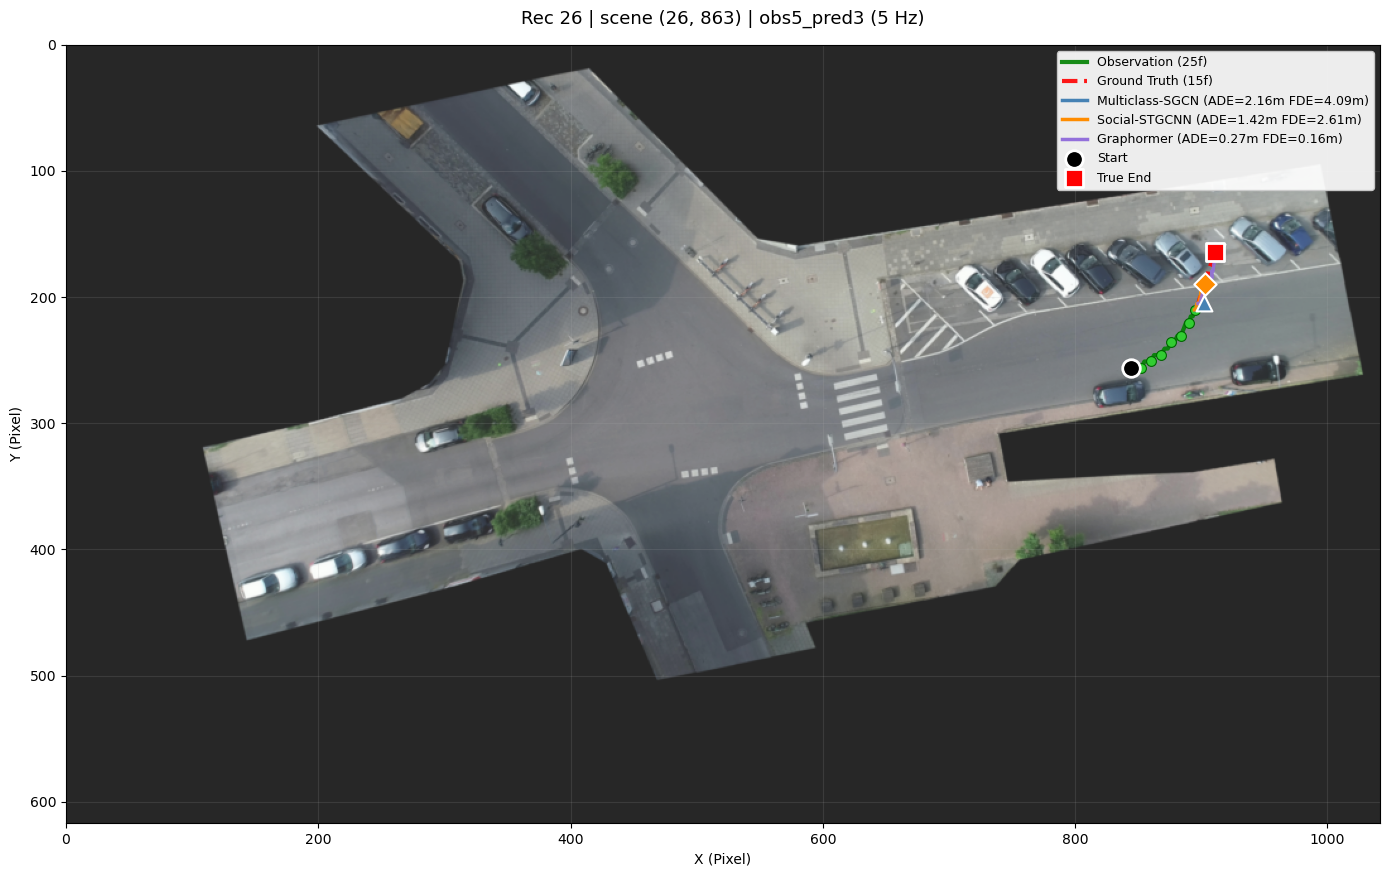

  Multiclass-SGCN: ADE=2.161m  FDE=4.088m
  Social-STGCNN: ADE=1.425m  FDE=2.610m
  Graphormer: ADE=0.267m  FDE=0.156m

--- Vis 2/5  scene=(28, 77)  Rec 28 ---
  focal UTM: (295671.5, 5628070.5)
  SGCN  obs start: (295642.6, 5628064.5)
  STGCNN obs start: (295642.6, 5628064.5)
  Saved: checkpoints_test29/visualizations/vis_2_rec28.png


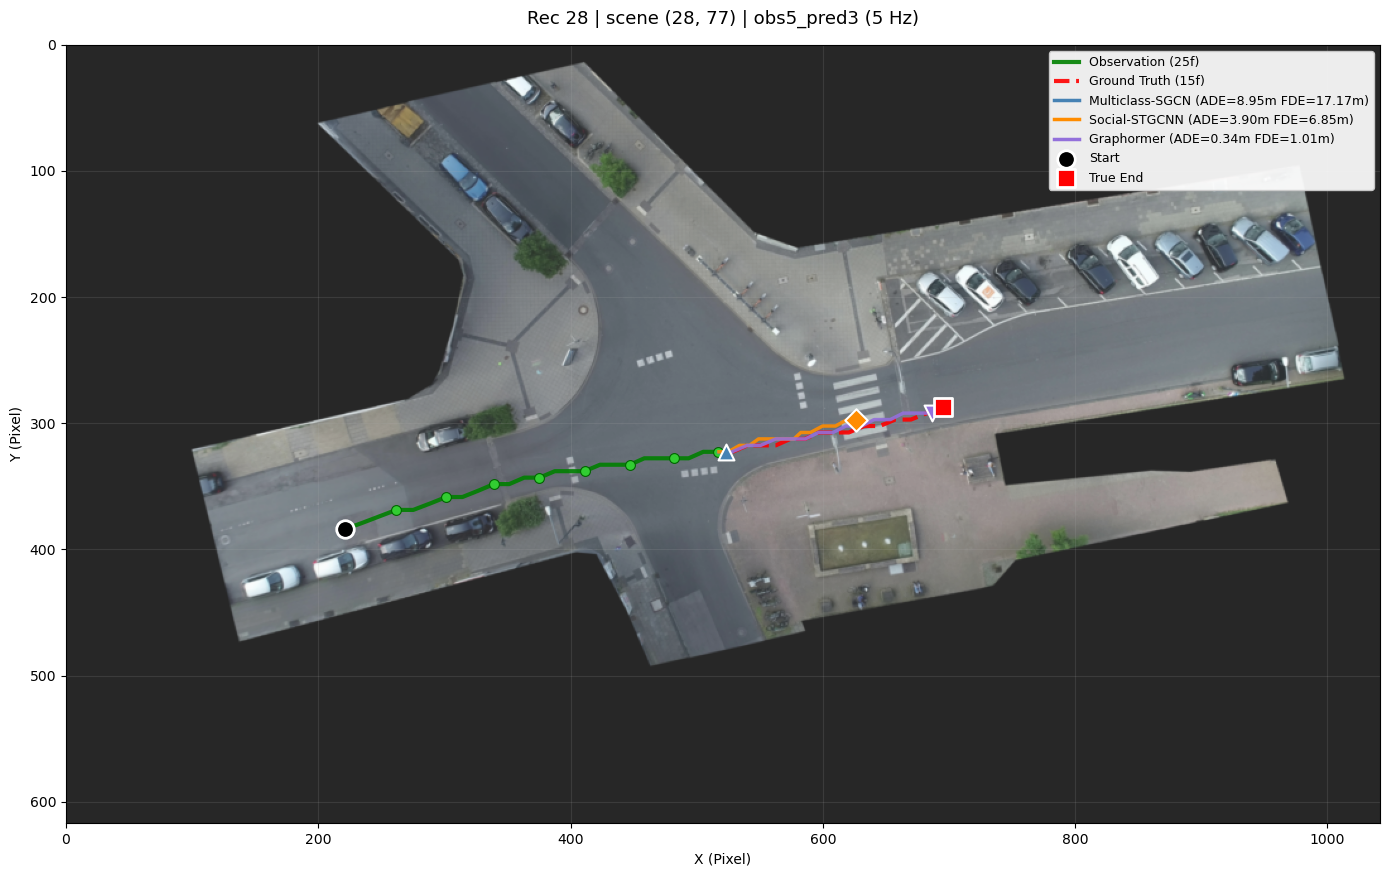

  Multiclass-SGCN: ADE=8.946m  FDE=17.173m
  Social-STGCNN: ADE=3.901m  FDE=6.855m
  Graphormer: ADE=0.339m  FDE=1.008m

--- Vis 3/5  scene=(31, 479)  Rec 31 ---
  focal UTM: (300178.3, 5629077.0)
  SGCN  obs start: (300184.6, 5629079.0)
  STGCNN obs start: (300184.6, 5629079.0)
  Saved: checkpoints_test29/visualizations/vis_3_rec31.png


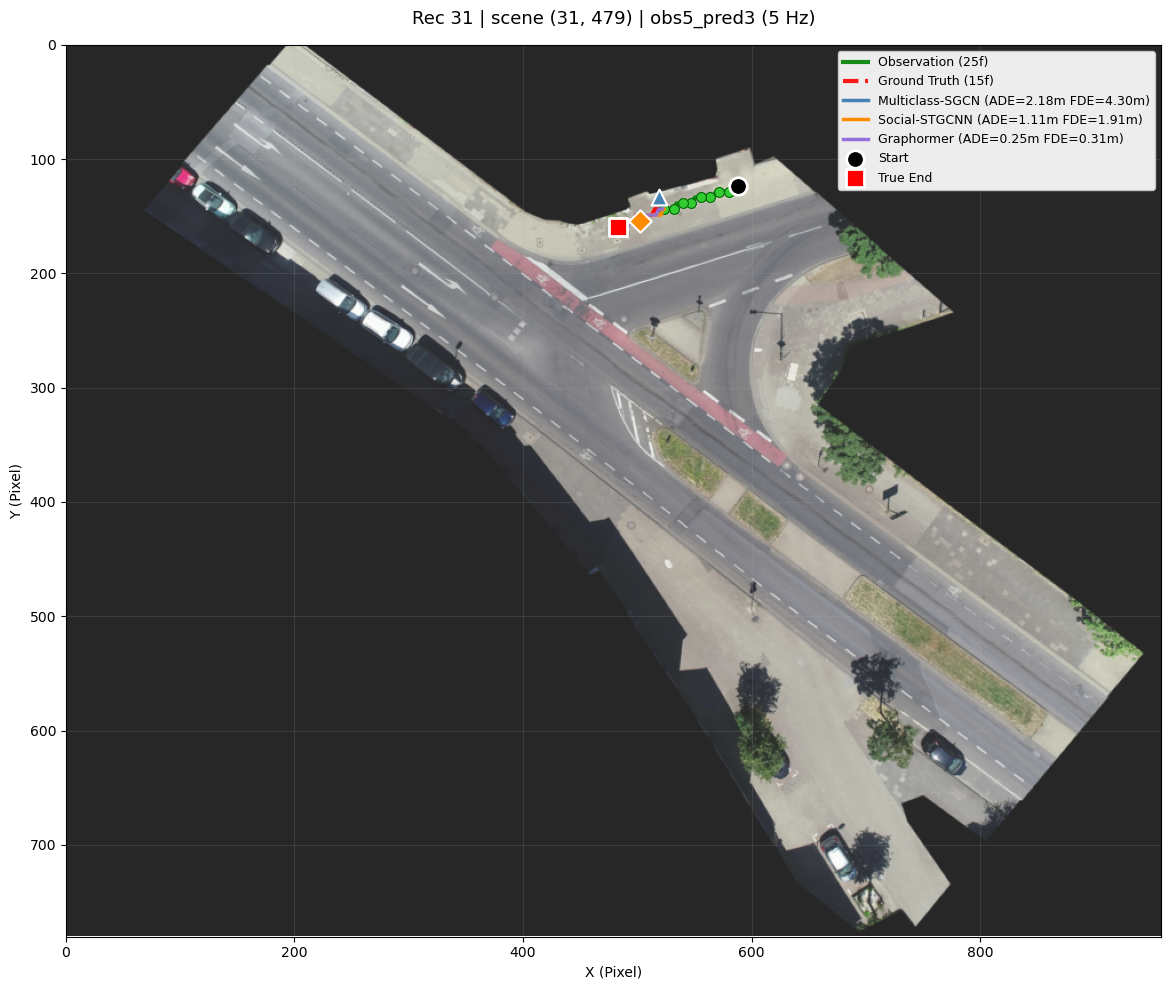

  Multiclass-SGCN: ADE=2.176m  FDE=4.301m
  Social-STGCNN: ADE=1.110m  FDE=1.910m
  Graphormer: ADE=0.248m  FDE=0.312m

--- Vis 4/5  scene=(23, 886)  Rec 23 ---
  focal UTM: (295653.2, 5628070.5)
  SGCN  obs start: (295663.1, 5628081.0)
  STGCNN obs start: (295663.1, 5628081.0)
  Saved: checkpoints_test29/visualizations/vis_4_rec23.png


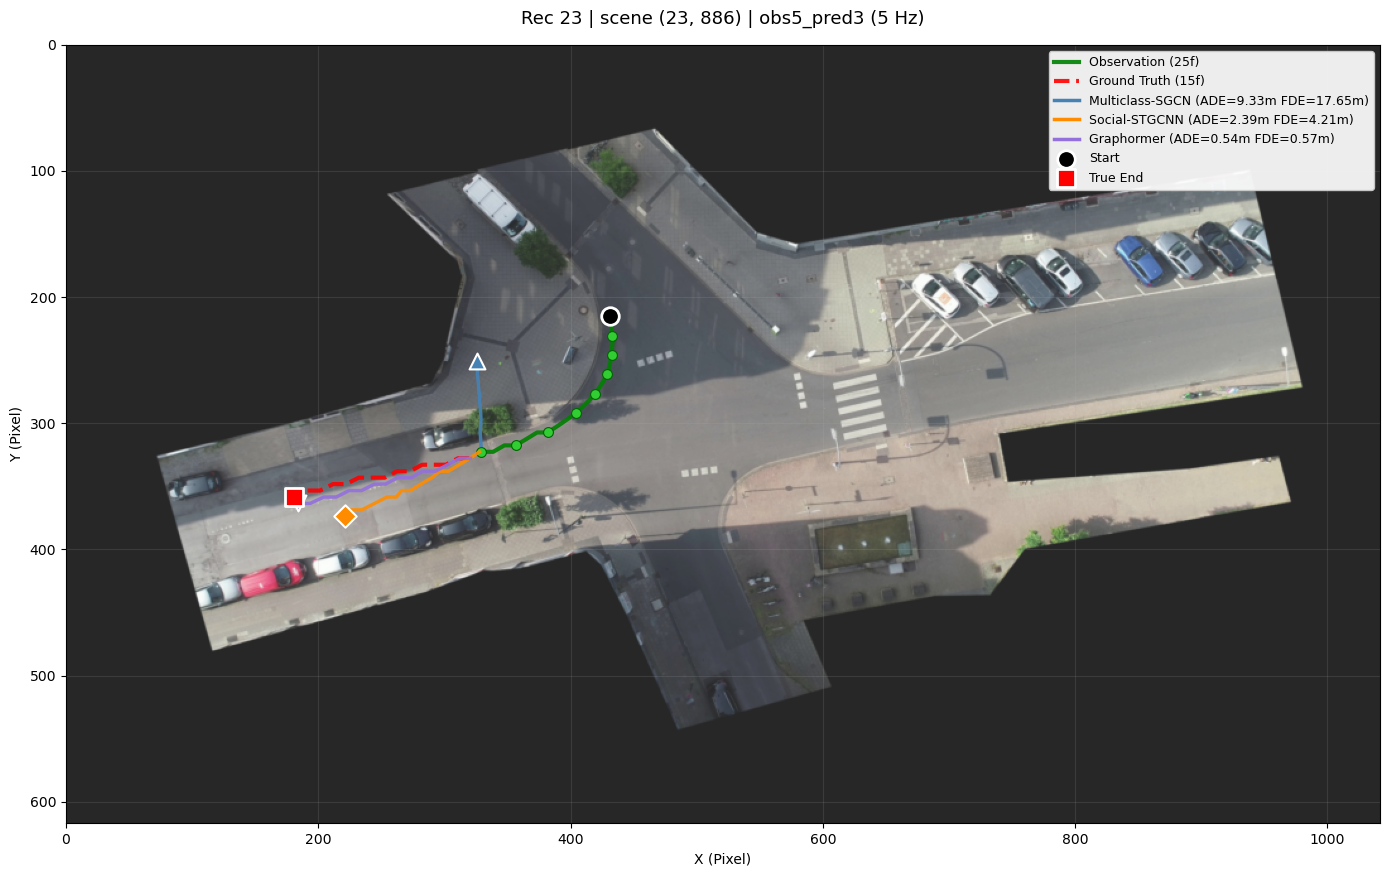

  Multiclass-SGCN: ADE=9.333m  FDE=17.650m
  Social-STGCNN: ADE=2.386m  FDE=4.214m
  Graphormer: ADE=0.544m  FDE=0.574m

--- Vis 5/5  scene=(2, 853)  Rec 02 ---
  focal UTM: (297731.0, 5629844.5)
  SGCN  obs start: (297759.8, 5629865.0)
  STGCNN obs start: (297759.8, 5629865.0)
  Saved: checkpoints_test29/visualizations/vis_5_rec2.png


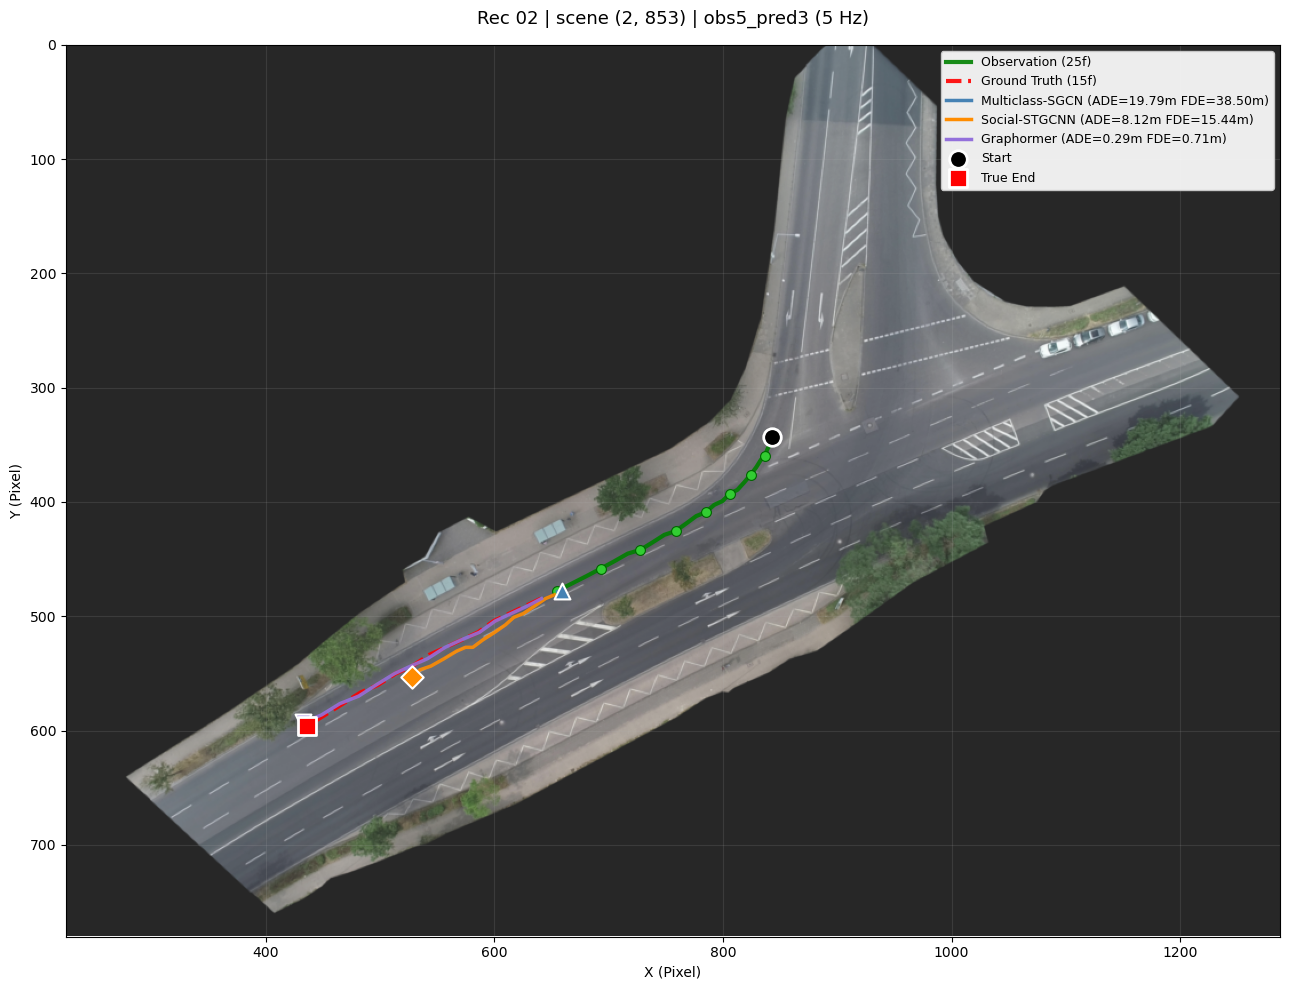

  Multiclass-SGCN: ADE=19.795m  FDE=38.498m
  Social-STGCNN: ADE=8.122m  FDE=15.435m
  Graphormer: ADE=0.288m  FDE=0.707m

VISUALIZATION SUMMARY
  Multiclass-SGCN     : Avg ADE=8.482m  Avg FDE=16.342m  (5 samples)
  Social-STGCNN       : Avg ADE=3.389m  Avg FDE=6.205m  (5 samples)
  Graphormer          : Avg ADE=0.337m  Avg FDE=0.551m  (5 samples)


In [30]:
import random
import pandas as pd
import numpy as np
from torch_geometric.loader import DataLoader as PyGDataLoader
from PIL import Image as _PIL_Image

print("=" * 70)
print(f"VISUALIZATION — reference config: {config_tag(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC)}")
print("=" * 70)

REF_OBS_F  = DEFAULT_OBS_SEC  * FPS
REF_PRED_F = DEFAULT_PRED_SEC * FPS
REF_CFG    = config_tag(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC)
NUM_VIS    = 5
MIN_FOCAL_DISPLACEMENT_M = 2.0

# ── Reload models ─────────────────────────────────────────────────────────────
def _load_ckpt(model, path, device):
    sd = torch.load(path, map_location=device, weights_only=True)
    sd = {k.replace('_orig_mod.', ''): v for k, v in sd.items()}
    model.load_state_dict(sd)

sgcn_model_vis = TrajectoryModel_attn(
    number_asymmetric_conv_layer=7, embedding_dims=64,
    number_gcn_layers=1, dropout=0,
    obs_len=REF_OBS_F, pred_len=REF_PRED_F,
    n_tcn=5, out_dims=5, num_heads=4
).to(device)
if os.path.exists(f'checkpoints_test29/sgcn_{REF_CFG}.pth'):
    _load_ckpt(sgcn_model_vis, f'checkpoints_test29/sgcn_{REF_CFG}.pth', device)
    print(f"  ✓ SGCN loaded")
sgcn_model_vis.eval()

stgcnn_model_vis = social_stgcnn(
    n_stgcnn=1, n_txpcnn=5, input_feat=2, output_feat=5,
    seq_len=REF_OBS_F, pred_seq_len=REF_PRED_F, kernel_size=3
).to(device)
if os.path.exists(f'checkpoints_test29/stgcnn_{REF_CFG}.pth'):
    _load_ckpt(stgcnn_model_vis, f'checkpoints_test29/stgcnn_{REF_CFG}.pth', device)
    print(f"  ✓ STGCNN loaded")
stgcnn_model_vis.eval()

graphormer_model_vis = Graphormer(
    num_layers=6, input_node_dim=GRAPHORMER_NODE_DIM, node_dim=128,
    input_edge_dim=1, edge_dim=32, output_dim=REF_PRED_F * 2,
    n_heads=8, ff_dim=512, max_in_degree=32, max_out_degree=32, max_path_distance=10
).to(device)
if os.path.exists(f'checkpoints_test29/graphormer_{REF_CFG}.pth'):
    _load_ckpt(graphormer_model_vis, f'checkpoints_test29/graphormer_{REF_CFG}.pth', device)
    print(f"  ✓ Graphormer loaded")
graphormer_model_vis.eval()

# ─────────────────────────────────────────────────────────────────────────────
# FEATHER SCENE KEY TABLE
# Feather x,y are raw UTM (FIX 6 reverted in baking V26).
# utm_to_pixel() works directly — no conversion needed.
# ─────────────────────────────────────────────────────────────────────────────
FEATHER_PATH = os.path.join(sgcn_dir(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC, 'test'), 'test.feather')
df_test = pd.read_feather(FEATHER_PATH)
df_test['_sid'] = df_test['frame'] // 1000

feather_scene_keys = []
for sid in sorted(df_test['_sid'].unique()):
    sdf = df_test[df_test['_sid'] == sid]
    feather_scene_keys.append(
        (int(sdf['rec_id'].iloc[0]), int(sdf['sample_idx'].iloc[0]))
    )

print(f"\n  Feather scene keys: {len(feather_scene_keys)} samples")
print(f"  First 3: {feather_scene_keys[:3]}")

# ─────────────────────────────────────────────────────────────────────────────
# GRAPHORMER DATASET (numeric sort)
# ─────────────────────────────────────────────────────────────────────────────
class GraphormerDatasetNumericSort(torch.utils.data.Dataset):
    def __init__(self, data_dir):
        self.data_dir = data_dir
        all_files = [f for f in os.listdir(data_dir)
                     if f.startswith('graph_') and f.endswith('.pt')]
        self.files = sorted(all_files,
                            key=lambda f: int(f.split('_')[1].split('.')[0]))
        print(f"  Found {len(self.files)} graphs (numeric sort)")
    def __len__(self):       return len(self.files)
    def __getitem__(self, i): return torch.load(os.path.join(self.data_dir, self.files[i]))

# ── Test datasets ─────────────────────────────────────────────────────────────
sgcn_test_vis_ds    = FastAgentTrajectoryDataset(
    sgcn_dir(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC, 'test'), REF_OBS_F, REF_PRED_F)
sgcn_test_vis_ldr   = DataLoader(sgcn_test_vis_ds, batch_size=1,
                                  shuffle=False, num_workers=0)

stgcnn_test_vis_ds  = FastTrajectoryDataset(
    stgcnn_dir(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC, 'test'), REF_OBS_F, REF_PRED_F)
stgcnn_test_vis_ldr = DataLoader(stgcnn_test_vis_ds, batch_size=1,
                                  shuffle=False, num_workers=0)

gr_test_vis_ds  = GraphormerDatasetNumericSort(
    graphormer_dir(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC, 'test'))
gr_test_vis_ldr = PyGDataLoader(gr_test_vis_ds, batch_size=1, shuffle=False)

os.makedirs('checkpoints_test29/visualizations', exist_ok=True)
_id_cache_vis = {}

# ─────────────────────────────────────────────────────────────────────────────
# [1/3] SGCN predictions — raw UTM throughout
# obs_traj [obs_len, n, 2], pred_traj [pred_len, n, 2] — both raw UTM
# Focal agent is always slot 0 (V23 baking guarantee)
# ─────────────────────────────────────────────────────────────────────────────
print("\n[1/3] Collecting SGCN predictions...")
sgcn_by_scene = {}
with torch.no_grad():
    for bi, batch in enumerate(sgcn_test_vis_ldr):
        obs_traj, pred_traj, _, _, _, _, v_obs, v_pred = batch
        if v_obs.numel() <= 1: continue
        while v_obs.dim() > 4: v_obs = v_obs.squeeze(0)
        if v_obs.shape[2] <= 1 or v_obs.dim() != 4 or v_obs.shape[-1] != 9: continue

        v_d = v_obs.to(device)
        obs_len = v_d.shape[1]; n = v_d.shape[2]
        key = (obs_len, n)
        if key not in _id_cache_vis:
            _id_cache_vis[key] = (
                torch.ones(obs_len, n, n,       device=device) * torch.eye(n,       device=device),
                torch.ones(n, obs_len, obs_len, device=device) * torch.eye(obs_len, device=device),
            )
        id_s, id_t = _id_cache_vis[key]
        try:
            V_p = sgcn_model_vis(v_d, [id_s, id_t])
        except Exception: continue

        V_p = V_p.squeeze().cpu()
        if V_p.dim() == 2: V_p = V_p.unsqueeze(1)

        scene_key = feather_scene_keys[bi] if bi < len(feather_scene_keys) else (-1, bi)
        sgcn_by_scene[scene_key] = {
            'obs_utm':  obs_traj.squeeze(0).numpy(),    # [obs_len, n, 2] raw UTM
            'gt_utm':   pred_traj.squeeze(0).numpy(),   # [pred_len, n, 2] raw UTM
            'vel':      V_p[:, :, 0:2].numpy(),         # [pred_len, n, 2]
        }

print(f"  Collected {len(sgcn_by_scene)} SGCN samples")

# ─────────────────────────────────────────────────────────────────────────────
# [2/3] STGCNN predictions — raw UTM throughout
# obs_traj [n, obs_len, 2], pred_traj [n, pred_len, 2] — both raw UTM
# ─────────────────────────────────────────────────────────────────────────────
print("[2/3] Collecting STGCNN predictions...")
stg_by_scene = {}
with torch.no_grad():
    for bi, batch in enumerate(stgcnn_test_vis_ldr):
        obs_traj, pred_traj, _, _, _, _, v_obs, A_obs, v_pred, A_pred = batch
        if v_obs.numel() <= 1: continue
        while v_obs.dim() > 4: v_obs = v_obs.squeeze(0)
        if v_obs.dim() == 3: v_obs = v_obs.unsqueeze(0)
        V_obs_t = v_obs.permute(0, 1, 3, 2).to(device)
        A_obs_t = A_obs.squeeze(0)
        if A_obs_t.dim() == 3: A_obs_t = A_obs_t.permute(2, 0, 1)
        try:
            V_p_out, _ = stgcnn_model_vis(V_obs_t, A_obs_t.to(device))
        except Exception: continue

        V_p_out = V_p_out.permute(0, 2, 3, 1).squeeze(0).cpu()
        if V_p_out.dim() == 2: V_p_out = V_p_out.unsqueeze(1)

        scene_key = feather_scene_keys[bi] if bi < len(feather_scene_keys) else (-1, bi)
        stg_by_scene[scene_key] = {
            'obs_utm':  obs_traj.squeeze(0).numpy(),    # [n, obs_len, 2] raw UTM
            'gt_utm':   pred_traj.squeeze(0).numpy(),   # [n, pred_len, 2] raw UTM
            'vel':      V_p_out[:, :, 0:2].numpy(),     # [pred_len, n, 2]
        }

print(f"  Collected {len(stg_by_scene)} STGCNN samples")

# ─────────────────────────────────────────────────────────────────────────────
# [3/3] Graphormer predictions
# batch.x[:,0:2] are raw UTM. Runtime center-shift applied here.
# pred_abs = cumsum(focal_pred) + focal_last = raw UTM prediction.
# batch.y = raw UTM future positions.
# ─────────────────────────────────────────────────────────────────────────────
print("[3/3] Collecting Graphormer predictions...")
gr_by_scene = {}
with torch.no_grad():
    for bi, batch in enumerate(gr_test_vis_ldr):
        if not hasattr(batch, 'x') or batch.edge_attr.shape[0] == 0: continue
        batch  = batch.to(device)

        fi_t = batch.focal_idx
        while fi_t.dim() > 0: fi_t = fi_t.squeeze(0)
        fi = int(fi_t.item())
        if fi >= batch.x.shape[0]: continue

        # focal_last is raw UTM before center-shift
        focal_last = batch.x[fi, :2].clone().cpu().numpy()   # [2] raw UTM

        # Runtime center-shift (mirrors train/eval)
        batch.x        = batch.x.clone()
        batch.x[:, 0] -= float(focal_last[0])
        batch.x[:, 1] -= float(focal_last[1])

        try:
            pred_all = graphormer_model_vis(batch)
        except Exception: continue

        focal_pred = pred_all[fi].view(REF_PRED_F, 2).cpu().numpy()
        # Reconstruct raw UTM: cumsum of local displacements + raw UTM origin
        pred_utm   = np.cumsum(focal_pred, axis=0) + focal_last   # [pred_len, 2] raw UTM
        gt_utm     = batch.y.cpu().numpy()                         # [pred_len, 2] raw UTM

        rec_id    = int(batch.recording_id.item()) if hasattr(batch, 'recording_id') else -1
        scene_key = feather_scene_keys[bi] if bi < len(feather_scene_keys) else (rec_id, bi)

        gr_by_scene[scene_key] = {
            'rec_id':    rec_id,
            'focal_utm': focal_last,   # raw UTM — for sanity check
            'gt_utm':    gt_utm,       # raw UTM
            'pred_utm':  pred_utm,     # raw UTM
        }

print(f"  Collected {len(gr_by_scene)} Graphormer samples")

# ── Sanity check ──────────────────────────────────────────────────────────────
common_keys = sorted(set(gr_by_scene) & set(sgcn_by_scene) & set(stg_by_scene))
print(f"\n  Common scene keys: {len(common_keys)}")
if common_keys:
    k0        = common_keys[0]
    focal_utm = gr_by_scene[k0]['focal_utm']
    sg_last   = sgcn_by_scene[k0]['obs_utm'][-1, 0, :]   # slot 0 = focal
    dist      = np.linalg.norm(sg_last - focal_utm)
    print(f"  Sanity check scene={k0}")
    print(f"    Graphormer focal_utm: ({focal_utm[0]:.1f}, {focal_utm[1]:.1f})")
    print(f"    SGCN slot-0 last obs: ({sg_last[0]:.1f}, {sg_last[1]:.1f})")
    print(f"    Distance: {dist:.2f}m  " + ("✓ aligned" if dist < 1.0 else "⚠️  misaligned"))

# ── Scene selection ───────────────────────────────────────────────────────────
def focal_displacement(sk):
    g = gr_by_scene[sk]['gt_utm']   # [pred_len, 2] raw UTM
    return float(np.linalg.norm(g[-1] - g[0]))

moving_keys = [sk for sk in common_keys
               if focal_displacement(sk) >= MIN_FOCAL_DISPLACEMENT_M]
pool     = moving_keys if len(moving_keys) >= NUM_VIS else common_keys
vis_keys = random.sample(pool, min(NUM_VIS, len(pool)))
print(f"\n  Moving agents: {len(moving_keys)}  |  Selected scenes: {vis_keys}")

# ─────────────────────────────────────────────────────────────────────────────
# Plotting — all arrays are raw UTM, utm_to_pixel() works directly
# ─────────────────────────────────────────────────────────────────────────────
def plot_vis(rec_id, obs_utm, gt_utm, predictions, title_extra="", save_path=None):
    """All coord arrays are raw UTM. utm_to_pixel() converts to pixel coords."""
    bg_path = (recording_meta.get(rec_id, {}).get('background_image_path')
               or f"{BACKGROUND_IMAGE_ROOT}/{rec_id:02d}_background.png")
    has_bg  = os.path.exists(bg_path) and (rec_id in recording_meta)
    fig, ax = plt.subplots(figsize=(14, 10))

    if has_bg:
        bg_np = np.array(_PIL_Image.open(bg_path))
        ax.imshow(bg_np, alpha=0.85)
        loc_id = str(REC_TO_LOCATION.get(rec_id, ''))
        if loc_id in _VIS_RA:
            ra = _VIS_RA[loc_id]
            ax.set_xlim(ra["x_lim"][0] / _VIS_S, ra["x_lim"][1] / _VIS_S)
            ax.set_ylim(ra["y_lim"][0] / _VIS_S, ra["y_lim"][1] / _VIS_S)
        to_px = lambda arr: np.array([utm_to_pixel(x, y, rec_id)
                                      for x, y in np.atleast_2d(arr)])
        coord_label = "Pixel"
    else:
        print(f"  ⚠️  No background for rec {rec_id} — plotting raw UTM")
        to_px = lambda arr: np.atleast_2d(arr).astype(float)
        coord_label = "UTM (m)"

    obs_px = to_px(obs_utm)
    gt_px  = to_px(gt_utm)

    ax.plot(obs_px[:, 0], obs_px[:, 1], 'g-', lw=3, alpha=0.9,
            label=f'Observation ({len(obs_px)}f)', zorder=6)
    step = max(1, len(obs_px) // 8)
    ax.scatter(obs_px[::step, 0], obs_px[::step, 1],
               c='limegreen', s=50, zorder=7, edgecolors='darkgreen', lw=0.8)
    ax.plot(gt_px[:, 0], gt_px[:, 1], 'r--', lw=3, alpha=0.9,
            label=f'Ground Truth ({len(gt_px)}f)', zorder=6)

    _colors = {'Multiclass-SGCN': ('steelblue',    '^'),
               'Social-STGCNN':   ('darkorange',   'D'),
               'Graphormer':      ('mediumpurple', 'v')}
    errors = {}
    for mname, mdata in predictions.items():
        clr, mrk = _colors.get(mname, ('cyan', 'o'))
        p_utm = np.array(mdata['pred_utm'])
        g_utm = np.array(mdata['gt_utm'])
        p_px  = to_px(p_utm)
        n_    = min(len(g_utm), len(p_utm))
        ade   = float(np.mean(np.linalg.norm(g_utm[:n_] - p_utm[:n_], axis=1)))
        fde   = float(np.linalg.norm(g_utm[-1] - p_utm[-1]))
        errors[mname] = (ade, fde)
        ax.plot(p_px[:, 0], p_px[:, 1], '-', color=clr, lw=2.5, alpha=0.9, zorder=8)
        ax.plot([], [], '-', color=clr, lw=2.5,
                label=f'{mname} (ADE={ade:.2f}m FDE={fde:.2f}m)')
        ax.scatter(p_px[-1, 0], p_px[-1, 1], c=clr, s=130, marker=mrk,
                   zorder=10, edgecolors='white', lw=1.5)

    ax.scatter(obs_px[0, 0],  obs_px[0, 1],  c='black', s=160, marker='o',
               label='Start',    zorder=11, edgecolors='white', lw=2)
    ax.scatter(gt_px[-1, 0],  gt_px[-1, 1],  c='red',   s=160, marker='s',
               label='True End', zorder=11, edgecolors='white', lw=2)

    ax.set_title(f"Rec {rec_id:02d}" + (f" | {title_extra}" if title_extra else ""),
                 fontsize=13, pad=15)
    ax.set_xlabel(f"X ({coord_label})")
    ax.set_ylabel(f"Y ({coord_label})")
    ax.legend(loc="upper right", fontsize=9, framealpha=0.92)
    ax.grid(True, alpha=0.15)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"  Saved: {save_path}")
    plt.show()
    return errors

# ── Visualization loop ────────────────────────────────────────────────────────
all_vis_errors = {m: [] for m in ['Multiclass-SGCN', 'Social-STGCNN', 'Graphormer']}

print("\n[4/4] Creating visualizations...")
for vi, sk in enumerate(vis_keys):
    gr_data = gr_by_scene[sk]
    sg_data = sgcn_by_scene[sk]
    st_data = stg_by_scene[sk]
    rec_id  = gr_data['rec_id']

    # Focal agent = slot 0 (V23 baking guarantee)
    # SGCN obs [obs_len, n, 2], STGCNN obs [n, obs_len, 2] — both raw UTM
    sgcn_obs_utm  = sg_data['obs_utm'][:, 0, :]     # [obs_len, 2] raw UTM
    sgcn_gt_utm   = sg_data['gt_utm'][:, 0, :]      # [pred_len, 2] raw UTM
    sgcn_last_utm = sgcn_obs_utm[-1]                 # [2] raw UTM
    sgcn_pred_utm = np.cumsum(sg_data['vel'][:, 0, :], axis=0) + sgcn_last_utm

    stg_obs_utm   = st_data['obs_utm'][0, :, :]     # [obs_len, 2] raw UTM
    stg_gt_utm    = st_data['gt_utm'][0, :, :]      # [pred_len, 2] raw UTM
    stg_last_utm  = stg_obs_utm[-1]
    stg_pred_utm  = np.cumsum(st_data['vel'][:, 0, :], axis=0) + stg_last_utm

    print(f"\n--- Vis {vi+1}/{NUM_VIS}  scene={sk}  Rec {rec_id:02d} ---")
    print(f"  focal UTM: ({gr_data['focal_utm'][0]:.1f}, {gr_data['focal_utm'][1]:.1f})")
    print(f"  SGCN  obs start: ({sgcn_obs_utm[0,0]:.1f}, {sgcn_obs_utm[0,1]:.1f})")
    print(f"  STGCNN obs start: ({stg_obs_utm[0,0]:.1f}, {stg_obs_utm[0,1]:.1f})")

    predictions = {
        'Multiclass-SGCN': {'pred_utm': sgcn_pred_utm, 'gt_utm': sgcn_gt_utm},
        'Social-STGCNN':   {'pred_utm': stg_pred_utm,  'gt_utm': stg_gt_utm},
        'Graphormer':      {'pred_utm': gr_data['pred_utm'], 'gt_utm': gr_data['gt_utm']},
    }

    errors = plot_vis(
        rec_id, sgcn_obs_utm, sgcn_gt_utm, predictions,
        title_extra=f"scene {sk} | {REF_CFG} (5 Hz)",
        save_path=f"checkpoints_test29/visualizations/vis_{vi+1}_rec{rec_id}.png")

    for mn, (ade, fde) in errors.items():
        all_vis_errors[mn].append((ade, fde))
        print(f"  {mn}: ADE={ade:.3f}m  FDE={fde:.3f}m")

print("\n" + "=" * 70)
print("VISUALIZATION SUMMARY")
print("=" * 70)
for mn, el in all_vis_errors.items():
    if el:
        print(f"  {mn:20s}: Avg ADE={np.mean([e[0] for e in el]):.3f}m  "
              f"Avg FDE={np.mean([e[1] for e in el]):.3f}m  ({len(el)} samples)")
print("=" * 70)


VISUALIZATION — reference config: obs5_pred3
  ✓ SGCN loaded
  ✓ STGCNN loaded
  ✓ Graphormer loaded

  Feather scene keys: 1000 samples
  First 3: [(20, 0), (28, 1), (3, 2)]
[test] Loading script/Multiclass-SGCN/datasets/inD_test2/obs5_pred3/test/test.feather...
[test] ✓ 673,480 rows


[test]: 100%|██████████| 1000/1000 [00:24<00:00, 40.43it/s]


[test] ✓ 1000 sequences  (obs=25f pred=15f window=40f max_agents=6)
[test] Loading script/Social-STGCNN/datasets/inD/inD_benchmark_test2/obs5_pred3/test/test.feather...
[test] ✓ 673,480 rows


[test]: 100%|██████████| 1000/1000 [00:19<00:00, 50.49it/s]


[test] ✓ 1000 sequences  (obs=25f pred=15f window=40f max_agents=6)
  Found 1000 graphs (numeric sort)

[1/3] Collecting SGCN predictions...
  Collected 1000 SGCN samples
[2/3] Collecting STGCNN predictions...
  Collected 1000 STGCNN samples
[3/3] Collecting Graphormer predictions...
  Collected 995 Graphormer samples

  Common scene keys: 995
  Sanity check scene=(0, 7)
    Graphormer focal_utm: (297741.6, 5629846.5)
    SGCN slot-0 last obs: (297741.6, 5629846.5)
    Distance: 0.00m  ✓ aligned

  Moving agents: 925  |  Selected scenes: [(25, 212), (21, 98), (1, 253), (1, 210), (3, 351)]

[4/4] Creating visualizations...

--- Vis 1/5  scene=(25, 212)  Rec 25 ---
  focal UTM: (295673.9, 5628079.0)
  SGCN  obs start: (295683.5, 5628070.5)
  STGCNN obs start: (295683.5, 5628070.5)
  Saved: checkpoints_test29/visualizations/vis_1_rec25.png


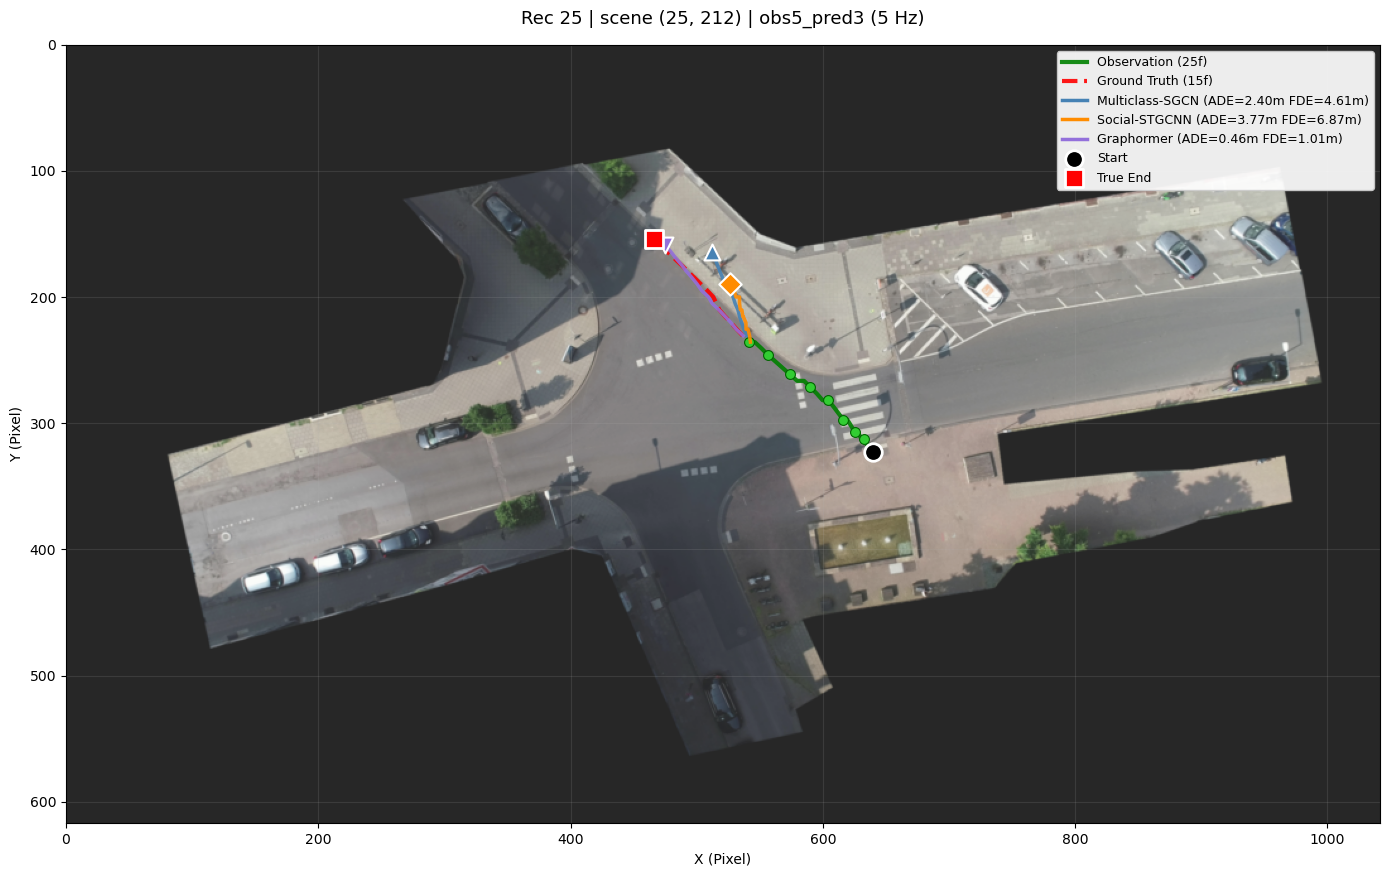

  Multiclass-SGCN: ADE=2.403m  FDE=4.610m
  Social-STGCNN: ADE=3.766m  FDE=6.865m
  Graphormer: ADE=0.462m  FDE=1.008m

--- Vis 2/5  scene=(21, 98)  Rec 21 ---
  focal UTM: (295680.6, 5628067.0)
  SGCN  obs start: (295676.5, 5628065.5)
  STGCNN obs start: (295676.5, 5628065.5)
  Saved: checkpoints_test29/visualizations/vis_2_rec21.png


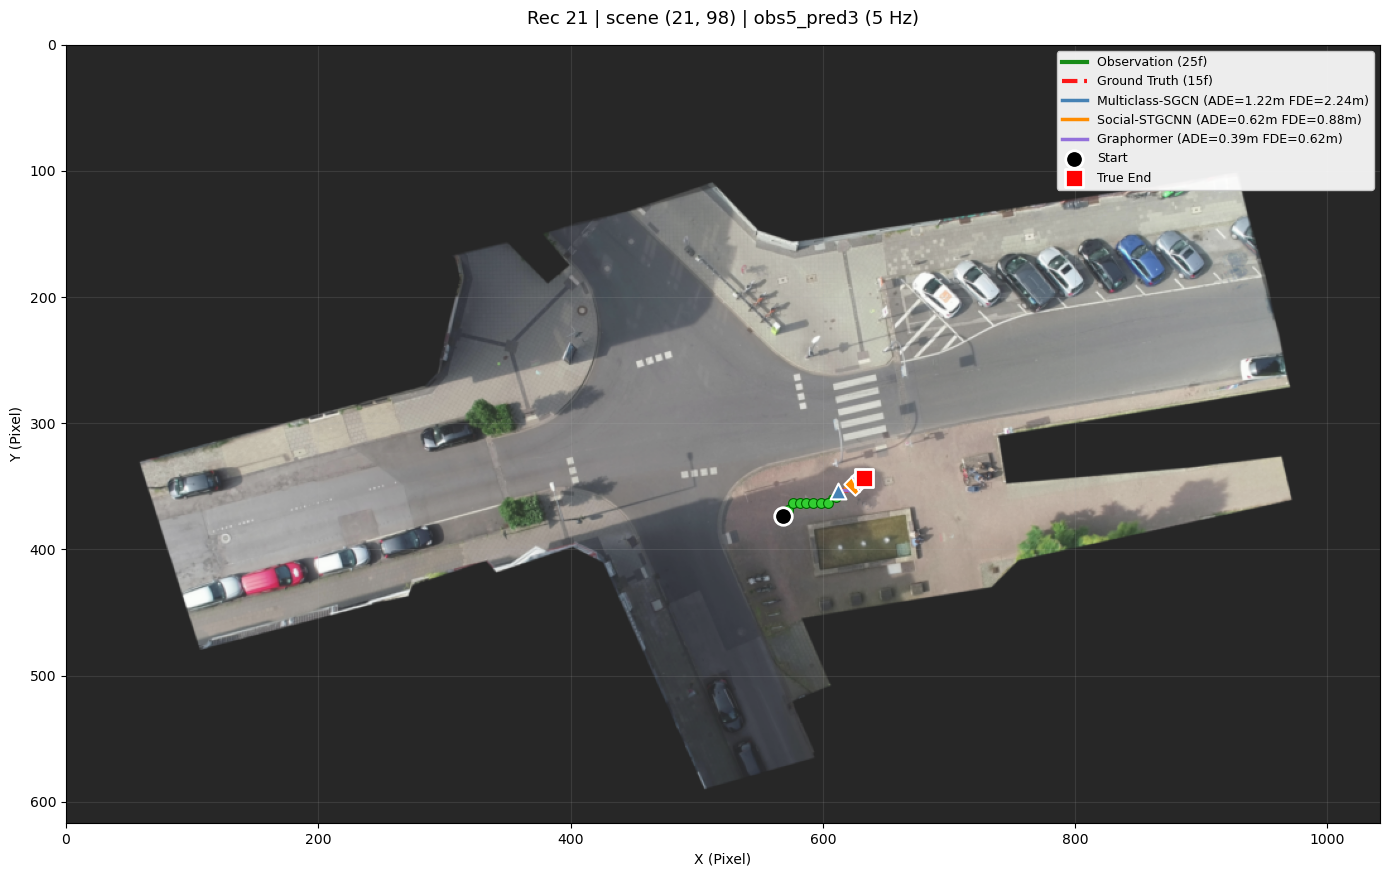

  Multiclass-SGCN: ADE=1.217m  FDE=2.236m
  Social-STGCNN: ADE=0.624m  FDE=0.876m
  Graphormer: ADE=0.395m  FDE=0.625m

--- Vis 3/5  scene=(1, 253)  Rec 01 ---
  focal UTM: (297758.6, 5629842.5)
  SGCN  obs start: (297698.5, 5629811.0)
  STGCNN obs start: (297698.5, 5629811.0)
  Saved: checkpoints_test29/visualizations/vis_3_rec1.png


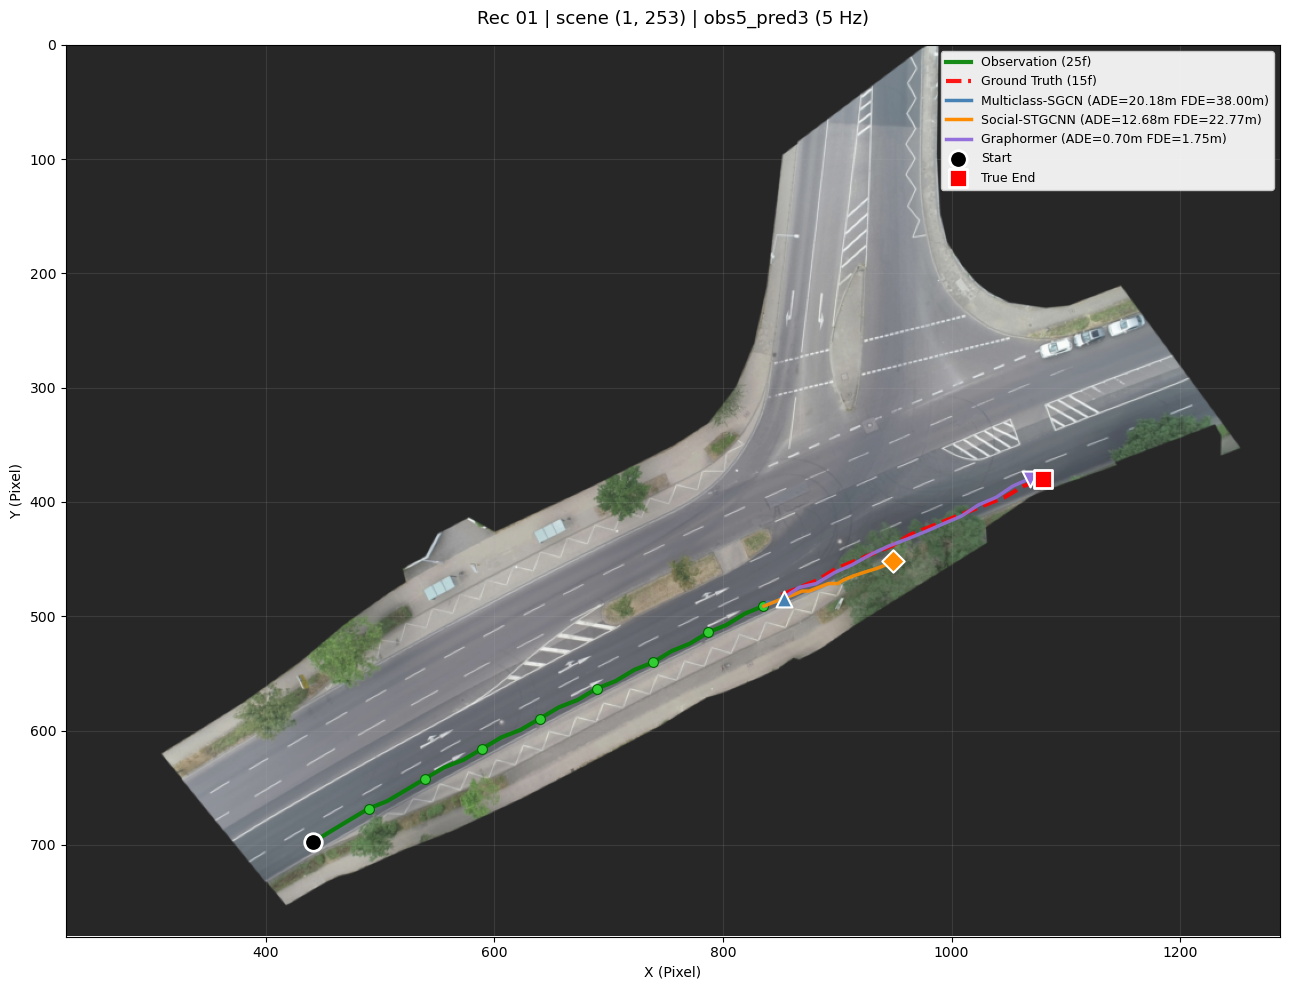

  Multiclass-SGCN: ADE=20.183m  FDE=38.001m
  Social-STGCNN: ADE=12.676m  FDE=22.771m
  Graphormer: ADE=0.703m  FDE=1.750m

--- Vis 4/5  scene=(1, 210)  Rec 01 ---
  focal UTM: (297730.8, 5629830.5)
  SGCN  obs start: (297733.4, 5629825.0)
  STGCNN obs start: (297733.4, 5629825.0)
  Saved: checkpoints_test29/visualizations/vis_4_rec1.png


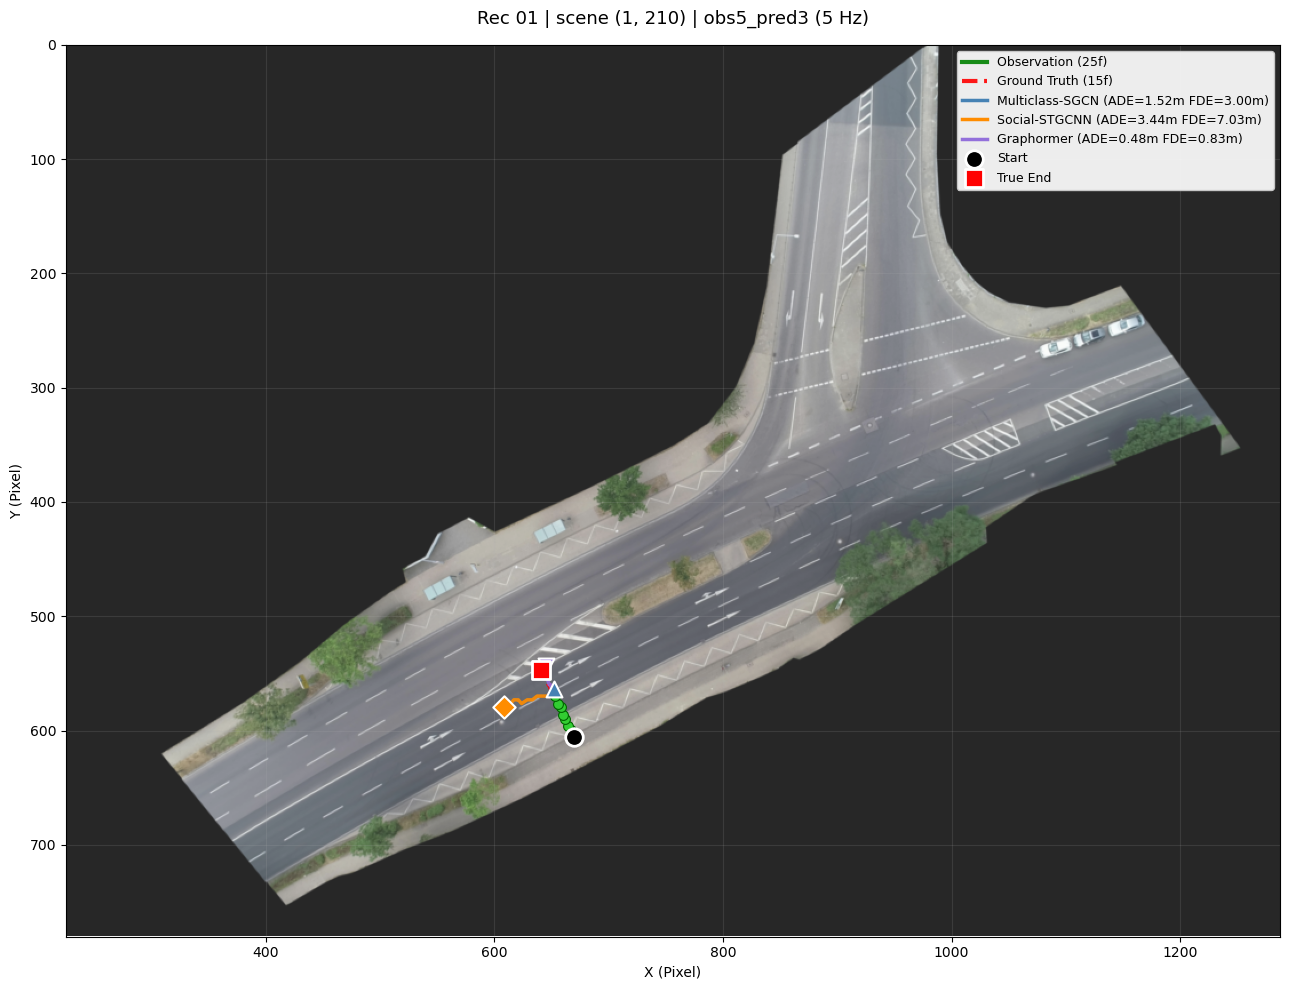

  Multiclass-SGCN: ADE=1.520m  FDE=2.999m
  Social-STGCNN: ADE=3.439m  FDE=7.027m
  Graphormer: ADE=0.483m  FDE=0.825m

--- Vis 5/5  scene=(3, 351)  Rec 03 ---
  focal UTM: (297765.4, 5629852.5)
  SGCN  obs start: (297732.0, 5629833.5)
  STGCNN obs start: (297732.0, 5629833.5)
  Saved: checkpoints_test29/visualizations/vis_5_rec3.png


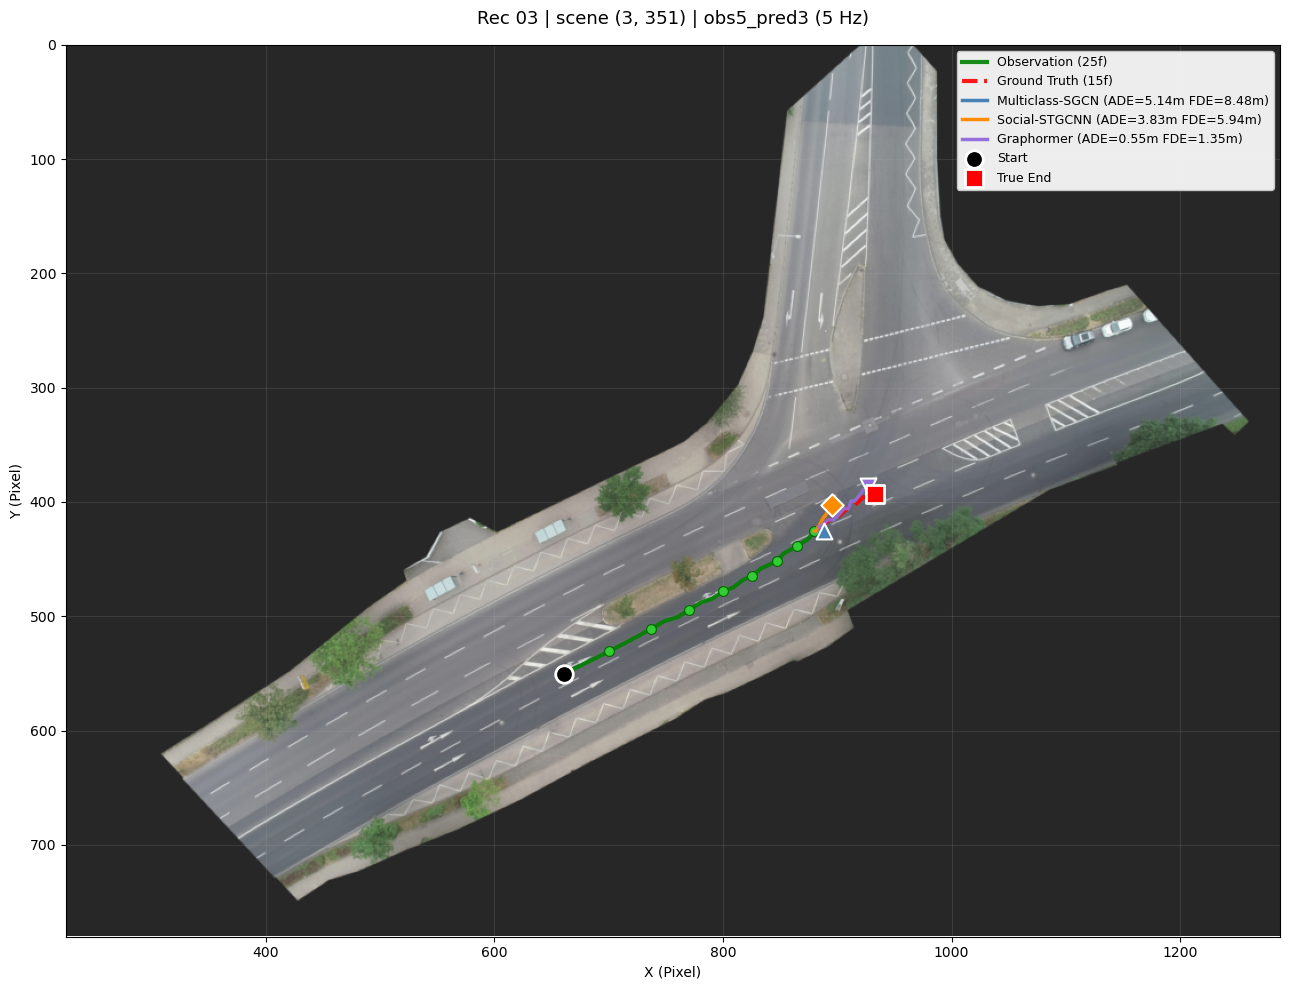

  Multiclass-SGCN: ADE=5.139m  FDE=8.476m
  Social-STGCNN: ADE=3.828m  FDE=5.942m
  Graphormer: ADE=0.552m  FDE=1.350m

VISUALIZATION SUMMARY
  Multiclass-SGCN     : Avg ADE=6.092m  Avg FDE=11.264m  (5 samples)
  Social-STGCNN       : Avg ADE=4.867m  Avg FDE=8.696m  (5 samples)
  Graphormer          : Avg ADE=0.519m  Avg FDE=1.111m  (5 samples)


In [31]:
import random
import pandas as pd
import numpy as np
from torch_geometric.loader import DataLoader as PyGDataLoader
from PIL import Image as _PIL_Image

print("=" * 70)
print(f"VISUALIZATION — reference config: {config_tag(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC)}")
print("=" * 70)

REF_OBS_F  = DEFAULT_OBS_SEC  * FPS
REF_PRED_F = DEFAULT_PRED_SEC * FPS
REF_CFG    = config_tag(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC)
NUM_VIS    = 5
MIN_FOCAL_DISPLACEMENT_M = 2.0

# ── Reload models ─────────────────────────────────────────────────────────────
def _load_ckpt(model, path, device):
    sd = torch.load(path, map_location=device, weights_only=True)
    sd = {k.replace('_orig_mod.', ''): v for k, v in sd.items()}
    model.load_state_dict(sd)

sgcn_model_vis = TrajectoryModel_attn(
    number_asymmetric_conv_layer=7, embedding_dims=64,
    number_gcn_layers=1, dropout=0,
    obs_len=REF_OBS_F, pred_len=REF_PRED_F,
    n_tcn=5, out_dims=5, num_heads=4
).to(device)
if os.path.exists(f'checkpoints_test29/sgcn_{REF_CFG}.pth'):
    _load_ckpt(sgcn_model_vis, f'checkpoints_test29/sgcn_{REF_CFG}.pth', device)
    print(f"  ✓ SGCN loaded")
sgcn_model_vis.eval()

stgcnn_model_vis = social_stgcnn(
    n_stgcnn=1, n_txpcnn=5, input_feat=2, output_feat=5,
    seq_len=REF_OBS_F, pred_seq_len=REF_PRED_F, kernel_size=3
).to(device)
if os.path.exists(f'checkpoints_test29/stgcnn_{REF_CFG}.pth'):
    _load_ckpt(stgcnn_model_vis, f'checkpoints_test29/stgcnn_{REF_CFG}.pth', device)
    print(f"  ✓ STGCNN loaded")
stgcnn_model_vis.eval()

graphormer_model_vis = Graphormer(
    num_layers=6, input_node_dim=GRAPHORMER_NODE_DIM, node_dim=128,
    input_edge_dim=1, edge_dim=32, output_dim=REF_PRED_F * 2,
    n_heads=8, ff_dim=512, max_in_degree=32, max_out_degree=32, max_path_distance=10
).to(device)
if os.path.exists(f'checkpoints_test29/graphormer_{REF_CFG}.pth'):
    _load_ckpt(graphormer_model_vis, f'checkpoints_test29/graphormer_{REF_CFG}.pth', device)
    print(f"  ✓ Graphormer loaded")
graphormer_model_vis.eval()

# ─────────────────────────────────────────────────────────────────────────────
# FEATHER SCENE KEY TABLE
# Feather x,y are raw UTM (FIX 6 reverted in baking V26).
# utm_to_pixel() works directly — no conversion needed.
# ─────────────────────────────────────────────────────────────────────────────
FEATHER_PATH = os.path.join(sgcn_dir(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC, 'test'), 'test.feather')
df_test = pd.read_feather(FEATHER_PATH)
df_test['_sid'] = df_test['frame'] // 1000

feather_scene_keys = []
for sid in sorted(df_test['_sid'].unique()):
    sdf = df_test[df_test['_sid'] == sid]
    feather_scene_keys.append(
        (int(sdf['rec_id'].iloc[0]), int(sdf['sample_idx'].iloc[0]))
    )

print(f"\n  Feather scene keys: {len(feather_scene_keys)} samples")
print(f"  First 3: {feather_scene_keys[:3]}")

# ─────────────────────────────────────────────────────────────────────────────
# GRAPHORMER DATASET (numeric sort)
# ─────────────────────────────────────────────────────────────────────────────
class GraphormerDatasetNumericSort(torch.utils.data.Dataset):
    def __init__(self, data_dir):
        self.data_dir = data_dir
        all_files = [f for f in os.listdir(data_dir)
                     if f.startswith('graph_') and f.endswith('.pt')]
        self.files = sorted(all_files,
                            key=lambda f: int(f.split('_')[1].split('.')[0]))
        print(f"  Found {len(self.files)} graphs (numeric sort)")
    def __len__(self):       return len(self.files)
    def __getitem__(self, i): return torch.load(os.path.join(self.data_dir, self.files[i]))

# ── Test datasets ─────────────────────────────────────────────────────────────
sgcn_test_vis_ds    = FastAgentTrajectoryDataset(
    sgcn_dir(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC, 'test'), REF_OBS_F, REF_PRED_F)
sgcn_test_vis_ldr   = DataLoader(sgcn_test_vis_ds, batch_size=1,
                                  shuffle=False, num_workers=0)

stgcnn_test_vis_ds  = FastTrajectoryDataset(
    stgcnn_dir(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC, 'test'), REF_OBS_F, REF_PRED_F)
stgcnn_test_vis_ldr = DataLoader(stgcnn_test_vis_ds, batch_size=1,
                                  shuffle=False, num_workers=0)

gr_test_vis_ds  = GraphormerDatasetNumericSort(
    graphormer_dir(DEFAULT_OBS_SEC, DEFAULT_PRED_SEC, 'test'))
gr_test_vis_ldr = PyGDataLoader(gr_test_vis_ds, batch_size=1, shuffle=False)

os.makedirs('checkpoints_test29/visualizations', exist_ok=True)
_id_cache_vis = {}

# ─────────────────────────────────────────────────────────────────────────────
# [1/3] SGCN predictions — raw UTM throughout
# obs_traj [obs_len, n, 2], pred_traj [pred_len, n, 2] — both raw UTM
# Focal agent is always slot 0 (V23 baking guarantee)
# ─────────────────────────────────────────────────────────────────────────────
print("\n[1/3] Collecting SGCN predictions...")
sgcn_by_scene = {}
with torch.no_grad():
    for bi, batch in enumerate(sgcn_test_vis_ldr):
        obs_traj, pred_traj, _, _, _, _, v_obs, v_pred = batch
        if v_obs.numel() <= 1: continue
        while v_obs.dim() > 4: v_obs = v_obs.squeeze(0)
        if v_obs.shape[2] <= 1 or v_obs.dim() != 4 or v_obs.shape[-1] != 9: continue

        v_d = v_obs.to(device)
        obs_len = v_d.shape[1]; n = v_d.shape[2]
        key = (obs_len, n)
        if key not in _id_cache_vis:
            _id_cache_vis[key] = (
                torch.ones(obs_len, n, n,       device=device) * torch.eye(n,       device=device),
                torch.ones(n, obs_len, obs_len, device=device) * torch.eye(obs_len, device=device),
            )
        id_s, id_t = _id_cache_vis[key]
        try:
            V_p = sgcn_model_vis(v_d, [id_s, id_t])
        except Exception: continue

        V_p = V_p.squeeze().cpu()
        if V_p.dim() == 2: V_p = V_p.unsqueeze(1)

        scene_key = feather_scene_keys[bi] if bi < len(feather_scene_keys) else (-1, bi)
        sgcn_by_scene[scene_key] = {
            'obs_utm':  obs_traj.squeeze(0).numpy(),    # [obs_len, n, 2] raw UTM
            'gt_utm':   pred_traj.squeeze(0).numpy(),   # [pred_len, n, 2] raw UTM
            'vel':      V_p[:, :, 0:2].numpy(),         # [pred_len, n, 2]
        }

print(f"  Collected {len(sgcn_by_scene)} SGCN samples")

# ─────────────────────────────────────────────────────────────────────────────
# [2/3] STGCNN predictions — raw UTM throughout
# obs_traj [n, obs_len, 2], pred_traj [n, pred_len, 2] — both raw UTM
# ─────────────────────────────────────────────────────────────────────────────
print("[2/3] Collecting STGCNN predictions...")
stg_by_scene = {}
with torch.no_grad():
    for bi, batch in enumerate(stgcnn_test_vis_ldr):
        obs_traj, pred_traj, _, _, _, _, v_obs, A_obs, v_pred, A_pred = batch
        if v_obs.numel() <= 1: continue
        while v_obs.dim() > 4: v_obs = v_obs.squeeze(0)
        if v_obs.dim() == 3: v_obs = v_obs.unsqueeze(0)
        V_obs_t = v_obs.permute(0, 1, 3, 2).to(device)
        A_obs_t = A_obs.squeeze(0)
        if A_obs_t.dim() == 3: A_obs_t = A_obs_t.permute(2, 0, 1)
        try:
            V_p_out, _ = stgcnn_model_vis(V_obs_t, A_obs_t.to(device))
        except Exception: continue

        V_p_out = V_p_out.permute(0, 2, 3, 1).squeeze(0).cpu()
        if V_p_out.dim() == 2: V_p_out = V_p_out.unsqueeze(1)

        scene_key = feather_scene_keys[bi] if bi < len(feather_scene_keys) else (-1, bi)
        stg_by_scene[scene_key] = {
            'obs_utm':  obs_traj.squeeze(0).numpy(),    # [n, obs_len, 2] raw UTM
            'gt_utm':   pred_traj.squeeze(0).numpy(),   # [n, pred_len, 2] raw UTM
            'vel':      V_p_out[:, :, 0:2].numpy(),     # [pred_len, n, 2]
        }

print(f"  Collected {len(stg_by_scene)} STGCNN samples")

# ─────────────────────────────────────────────────────────────────────────────
# [3/3] Graphormer predictions
# batch.x[:,0:2] are raw UTM. Runtime center-shift applied here.
# pred_abs = cumsum(focal_pred) + focal_last = raw UTM prediction.
# batch.y = raw UTM future positions.
# ─────────────────────────────────────────────────────────────────────────────
print("[3/3] Collecting Graphormer predictions...")
gr_by_scene = {}
with torch.no_grad():
    for bi, batch in enumerate(gr_test_vis_ldr):
        if not hasattr(batch, 'x') or batch.edge_attr.shape[0] == 0: continue
        batch  = batch.to(device)

        fi_t = batch.focal_idx
        while fi_t.dim() > 0: fi_t = fi_t.squeeze(0)
        fi = int(fi_t.item())
        if fi >= batch.x.shape[0]: continue

        # focal_last is raw UTM before center-shift
        focal_last = batch.x[fi, :2].clone().cpu().numpy()   # [2] raw UTM

        # Runtime center-shift (mirrors train/eval)
        batch.x        = batch.x.clone()
        batch.x[:, 0] -= float(focal_last[0])
        batch.x[:, 1] -= float(focal_last[1])

        try:
            pred_all = graphormer_model_vis(batch)
        except Exception: continue

        focal_pred = pred_all[fi].view(REF_PRED_F, 2).cpu().numpy()
        # Reconstruct raw UTM: cumsum of local displacements + raw UTM origin
        pred_utm   = np.cumsum(focal_pred, axis=0) + focal_last   # [pred_len, 2] raw UTM
        gt_utm     = batch.y.cpu().numpy()                         # [pred_len, 2] raw UTM

        rec_id    = int(batch.recording_id.item()) if hasattr(batch, 'recording_id') else -1
        scene_key = feather_scene_keys[bi] if bi < len(feather_scene_keys) else (rec_id, bi)

        gr_by_scene[scene_key] = {
            'rec_id':    rec_id,
            'focal_utm': focal_last,   # raw UTM — for sanity check
            'gt_utm':    gt_utm,       # raw UTM
            'pred_utm':  pred_utm,     # raw UTM
        }

print(f"  Collected {len(gr_by_scene)} Graphormer samples")

# ── Sanity check ──────────────────────────────────────────────────────────────
common_keys = sorted(set(gr_by_scene) & set(sgcn_by_scene) & set(stg_by_scene))
print(f"\n  Common scene keys: {len(common_keys)}")
if common_keys:
    k0        = common_keys[0]
    focal_utm = gr_by_scene[k0]['focal_utm']
    sg_last   = sgcn_by_scene[k0]['obs_utm'][-1, 0, :]   # slot 0 = focal
    dist      = np.linalg.norm(sg_last - focal_utm)
    print(f"  Sanity check scene={k0}")
    print(f"    Graphormer focal_utm: ({focal_utm[0]:.1f}, {focal_utm[1]:.1f})")
    print(f"    SGCN slot-0 last obs: ({sg_last[0]:.1f}, {sg_last[1]:.1f})")
    print(f"    Distance: {dist:.2f}m  " + ("✓ aligned" if dist < 1.0 else "⚠️  misaligned"))

# ── Scene selection ───────────────────────────────────────────────────────────
def focal_displacement(sk):
    g = gr_by_scene[sk]['gt_utm']   # [pred_len, 2] raw UTM
    return float(np.linalg.norm(g[-1] - g[0]))

moving_keys = [sk for sk in common_keys
               if focal_displacement(sk) >= MIN_FOCAL_DISPLACEMENT_M]
pool     = moving_keys if len(moving_keys) >= NUM_VIS else common_keys
vis_keys = random.sample(pool, min(NUM_VIS, len(pool)))
print(f"\n  Moving agents: {len(moving_keys)}  |  Selected scenes: {vis_keys}")

# ─────────────────────────────────────────────────────────────────────────────
# Plotting — all arrays are raw UTM, utm_to_pixel() works directly
# ─────────────────────────────────────────────────────────────────────────────
def plot_vis(rec_id, obs_utm, gt_utm, predictions, title_extra="", save_path=None):
    """All coord arrays are raw UTM. utm_to_pixel() converts to pixel coords."""
    bg_path = (recording_meta.get(rec_id, {}).get('background_image_path')
               or f"{BACKGROUND_IMAGE_ROOT}/{rec_id:02d}_background.png")
    has_bg  = os.path.exists(bg_path) and (rec_id in recording_meta)
    fig, ax = plt.subplots(figsize=(14, 10))

    if has_bg:
        bg_np = np.array(_PIL_Image.open(bg_path))
        ax.imshow(bg_np, alpha=0.85)
        loc_id = str(REC_TO_LOCATION.get(rec_id, ''))
        if loc_id in _VIS_RA:
            ra = _VIS_RA[loc_id]
            ax.set_xlim(ra["x_lim"][0] / _VIS_S, ra["x_lim"][1] / _VIS_S)
            ax.set_ylim(ra["y_lim"][0] / _VIS_S, ra["y_lim"][1] / _VIS_S)
        to_px = lambda arr: np.array([utm_to_pixel(x, y, rec_id)
                                      for x, y in np.atleast_2d(arr)])
        coord_label = "Pixel"
    else:
        print(f"  ⚠️  No background for rec {rec_id} — plotting raw UTM")
        to_px = lambda arr: np.atleast_2d(arr).astype(float)
        coord_label = "UTM (m)"

    obs_px = to_px(obs_utm)
    gt_px  = to_px(gt_utm)

    ax.plot(obs_px[:, 0], obs_px[:, 1], 'g-', lw=3, alpha=0.9,
            label=f'Observation ({len(obs_px)}f)', zorder=6)
    step = max(1, len(obs_px) // 8)
    ax.scatter(obs_px[::step, 0], obs_px[::step, 1],
               c='limegreen', s=50, zorder=7, edgecolors='darkgreen', lw=0.8)
    ax.plot(gt_px[:, 0], gt_px[:, 1], 'r--', lw=3, alpha=0.9,
            label=f'Ground Truth ({len(gt_px)}f)', zorder=6)

    _colors = {'Multiclass-SGCN': ('steelblue',    '^'),
               'Social-STGCNN':   ('darkorange',   'D'),
               'Graphormer':      ('mediumpurple', 'v')}
    errors = {}
    for mname, mdata in predictions.items():
        clr, mrk = _colors.get(mname, ('cyan', 'o'))
        p_utm = np.array(mdata['pred_utm'])
        g_utm = np.array(mdata['gt_utm'])
        p_px  = to_px(p_utm)
        n_    = min(len(g_utm), len(p_utm))
        ade   = float(np.mean(np.linalg.norm(g_utm[:n_] - p_utm[:n_], axis=1)))
        fde   = float(np.linalg.norm(g_utm[-1] - p_utm[-1]))
        errors[mname] = (ade, fde)
        ax.plot(p_px[:, 0], p_px[:, 1], '-', color=clr, lw=2.5, alpha=0.9, zorder=8)
        ax.plot([], [], '-', color=clr, lw=2.5,
                label=f'{mname} (ADE={ade:.2f}m FDE={fde:.2f}m)')
        ax.scatter(p_px[-1, 0], p_px[-1, 1], c=clr, s=130, marker=mrk,
                   zorder=10, edgecolors='white', lw=1.5)

    ax.scatter(obs_px[0, 0],  obs_px[0, 1],  c='black', s=160, marker='o',
               label='Start',    zorder=11, edgecolors='white', lw=2)
    ax.scatter(gt_px[-1, 0],  gt_px[-1, 1],  c='red',   s=160, marker='s',
               label='True End', zorder=11, edgecolors='white', lw=2)

    ax.set_title(f"Rec {rec_id:02d}" + (f" | {title_extra}" if title_extra else ""),
                 fontsize=13, pad=15)
    ax.set_xlabel(f"X ({coord_label})")
    ax.set_ylabel(f"Y ({coord_label})")
    ax.legend(loc="upper right", fontsize=9, framealpha=0.92)
    ax.grid(True, alpha=0.15)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"  Saved: {save_path}")
    plt.show()
    return errors

# ── Visualization loop ────────────────────────────────────────────────────────
all_vis_errors = {m: [] for m in ['Multiclass-SGCN', 'Social-STGCNN', 'Graphormer']}

print("\n[4/4] Creating visualizations...")
for vi, sk in enumerate(vis_keys):
    gr_data = gr_by_scene[sk]
    sg_data = sgcn_by_scene[sk]
    st_data = stg_by_scene[sk]
    rec_id  = gr_data['rec_id']

    # Focal agent = slot 0 (V23 baking guarantee)
    # SGCN obs [obs_len, n, 2], STGCNN obs [n, obs_len, 2] — both raw UTM
    sgcn_obs_utm  = sg_data['obs_utm'][:, 0, :]     # [obs_len, 2] raw UTM
    sgcn_gt_utm   = sg_data['gt_utm'][:, 0, :]      # [pred_len, 2] raw UTM
    sgcn_last_utm = sgcn_obs_utm[-1]                 # [2] raw UTM
    sgcn_pred_utm = np.cumsum(sg_data['vel'][:, 0, :], axis=0) + sgcn_last_utm

    stg_obs_utm   = st_data['obs_utm'][0, :, :]     # [obs_len, 2] raw UTM
    stg_gt_utm    = st_data['gt_utm'][0, :, :]      # [pred_len, 2] raw UTM
    stg_last_utm  = stg_obs_utm[-1]
    stg_pred_utm  = np.cumsum(st_data['vel'][:, 0, :], axis=0) + stg_last_utm

    print(f"\n--- Vis {vi+1}/{NUM_VIS}  scene={sk}  Rec {rec_id:02d} ---")
    print(f"  focal UTM: ({gr_data['focal_utm'][0]:.1f}, {gr_data['focal_utm'][1]:.1f})")
    print(f"  SGCN  obs start: ({sgcn_obs_utm[0,0]:.1f}, {sgcn_obs_utm[0,1]:.1f})")
    print(f"  STGCNN obs start: ({stg_obs_utm[0,0]:.1f}, {stg_obs_utm[0,1]:.1f})")

    predictions = {
        'Multiclass-SGCN': {'pred_utm': sgcn_pred_utm, 'gt_utm': sgcn_gt_utm},
        'Social-STGCNN':   {'pred_utm': stg_pred_utm,  'gt_utm': stg_gt_utm},
        'Graphormer':      {'pred_utm': gr_data['pred_utm'], 'gt_utm': gr_data['gt_utm']},
    }

    errors = plot_vis(
        rec_id, sgcn_obs_utm, sgcn_gt_utm, predictions,
        title_extra=f"scene {sk} | {REF_CFG} (5 Hz)",
        save_path=f"checkpoints_test29/visualizations/vis_{vi+1}_rec{rec_id}.png")

    for mn, (ade, fde) in errors.items():
        all_vis_errors[mn].append((ade, fde))
        print(f"  {mn}: ADE={ade:.3f}m  FDE={fde:.3f}m")

print("\n" + "=" * 70)
print("VISUALIZATION SUMMARY")
print("=" * 70)
for mn, el in all_vis_errors.items():
    if el:
        print(f"  {mn:20s}: Avg ADE={np.mean([e[0] for e in el]):.3f}m  "
              f"Avg FDE={np.mean([e[1] for e in el]):.3f}m  ({len(el)} samples)")
print("=" * 70)


In [33]:
# ============================================================================
# GRAPHORMER ANOMALY DETECTION
# Method: Reconstruction-error anomaly scoring (ADE per sample)
# Threshold: mean + 2*std across all test samples (per config)
# Per-class breakdown: derived from graph.x[focal_idx, 16] * 3.0
# Class map: 0=Car  1=Truck_Bus  2=Bicycle  3=Pedestrian
# ============================================================================

import os
import json
import numpy as np
import torch
from torch_geometric.loader import DataLoader as PyGDataLoader

CLASS_INT_MAP = {0: 'Car', 1: 'Truck_Bus', 2: 'Bicycle', 3: 'Pedestrian'}
ANOMALY_SIGMA = 2.0

anomaly_results = {}

for obs_sec, pred_sec in EXPERIMENT_CONFIGS:
    cfg    = config_tag(obs_sec, pred_sec)
    obs_f  = obs_sec  * FPS
    pred_f = pred_sec * FPS

    print(f"\n{'='*60}")
    print(f"ANOMALY DETECTION — {cfg}  ({obs_sec}s obs / {pred_sec}s pred)")
    print(f"{'='*60}")

    # ── Load Graphormer checkpoint ──────────────────────────────────────────
    gr_m = Graphormer(
        num_layers=6, input_node_dim=GRAPHORMER_NODE_DIM, node_dim=128,
        input_edge_dim=1, edge_dim=32, output_dim=pred_f * 2,
        n_heads=8, ff_dim=512, max_in_degree=32, max_out_degree=32,
        max_path_distance=10).to(device)

    ckpt = f'checkpoints_test29/graphormer_{cfg}.pth'
    if not os.path.exists(ckpt):
        print(f"  ⚠️  Missing checkpoint {ckpt}, skipping")
        continue
    _load_ckpt(gr_m, ckpt, device)
    gr_m.eval()

    # ── Load test graphs via PyGDataLoader (matches your notebook pattern) ──
    gr_test_dir = graphormer_dir(obs_sec, pred_sec, 'test')

    class _GrDS(torch.utils.data.Dataset):
        def __init__(self, d):
            fs = [f for f in os.listdir(d)
                  if f.startswith('graph_') and f.endswith('.pt')]
            fs = sorted(fs, key=lambda x: int(x.split('_')[1].split('.')[0]))
            self.files = [os.path.join(d, f) for f in fs]
        def __len__(self):        return len(self.files)
        def __getitem__(self, i): return torch.load(self.files[i])

    gr_ds  = _GrDS(gr_test_dir)
    gr_ldr = PyGDataLoader(gr_ds, batch_size=1, shuffle=False)

    sample_ades    = []
    sample_classes = []
    TSN_E = 29

    with torch.no_grad():
        for batch in gr_ldr:
            if not hasattr(batch, 'x') or batch.edge_attr.shape[0] == 0:
                continue

            batch = batch.to(device)

            # ── focal_idx: PyGDataLoader wraps it as a tensor ───────────────
            fi_t = batch.focal_idx
            while fi_t.dim() > 0:
                fi_t = fi_t.squeeze(0)
            fi = int(fi_t.item())

            if fi >= batch.x.shape[0]:
                continue
            if batch.x.shape[1] < TSN_E:
                continue

            # ── Agent class from node feature dim 16 ───────────────────────
            class_int = round(float(batch.x[fi, 16].cpu()) * 3.0)
            class_int = max(0, min(3, class_int))
            agent_class = CLASS_INT_MAP[class_int]

            # ── Centre-shift (matches training in your notebook) ────────────
            focal_utm = batch.x[fi, :2].clone().cpu().numpy()
            batch.x = batch.x.clone()
            batch.x[:, 0] -= float(focal_utm[0])
            batch.x[:, 1] -= float(focal_utm[1])

            # ── Forward pass ────────────────────────────────────────────────
            try:
                pred_out = gr_m(batch)
            except Exception:
                continue

            # ── Reconstruct absolute predicted trajectory ───────────────────
            pred_xy = (torch.cumsum(
                           pred_out[fi].view(pred_f, 2).cpu(), dim=0
                       ).numpy() + focal_utm)
            gt_xy = batch.y.cpu().numpy()   # [pred_f, 2]

            n_steps = min(len(pred_xy), len(gt_xy))
            ade = float(np.mean(
                np.linalg.norm(pred_xy[:n_steps] - gt_xy[:n_steps], axis=1)))

            sample_ades.append(ade)
            sample_classes.append(agent_class)

    sample_ades    = np.array(sample_ades)
    sample_classes = np.array(sample_classes)

    # ── Fit Gaussian and compute threshold ─────────────────────────────────
    mu        = float(np.mean(sample_ades))
    sigma     = float(np.std(sample_ades))
    threshold = mu + ANOMALY_SIGMA * sigma
    anomaly_mask = sample_ades > threshold

    n_total     = len(sample_ades)
    n_anomaly   = int(np.sum(anomaly_mask))
    anomaly_pct = 100.0 * n_anomaly / max(1, n_total)

    print(f"\n  ADE distribution : mean={mu:.4f}m   std={sigma:.4f}m")
    print(f"  Threshold (μ+2σ) : {threshold:.4f}m")
    print(f"  Total samples    : {n_total}")
    print(f"  Anomalies        : {n_anomaly}  ({anomaly_pct:.1f}%)")

    # ── Per-class breakdown ─────────────────────────────────────────────────
    print(f"\n  {'Agent Class':<15} {'Total':>7} {'Anomalies':>10} "
          f"{'Rate':>9} {'Mean ADE':>10} {'Anom ADE':>10}")
    print(f"  {'-'*65}")

    class_stats = {}
    for cls in ['Car', 'Pedestrian', 'Bicycle', 'Truck_Bus']:
        mask_cls = sample_classes == cls
        n_cls    = int(np.sum(mask_cls))
        if n_cls == 0:
            continue
        anom_cls  = int(np.sum(anomaly_mask & mask_cls))
        pct_cls   = 100.0 * anom_cls / n_cls
        mean_ade  = float(np.mean(sample_ades[mask_cls]))
        anom_ade  = (float(np.mean(sample_ades[anomaly_mask & mask_cls]))
                     if anom_cls > 0 else float('nan'))
        class_stats[cls] = {
            'n': n_cls, 'n_anomaly': anom_cls,
            'anomaly_pct': pct_cls,
            'mean_ade': mean_ade, 'anomaly_mean_ade': anom_ade,
        }
        print(f"  {cls:<15} {n_cls:>7} {anom_cls:>10} "
              f"{pct_cls:>8.1f}% {mean_ade:>10.4f} {anom_ade:>10.4f}")

    anomaly_results[cfg] = {
        'mu': mu, 'sigma': sigma, 'threshold': threshold,
        'n_total': n_total, 'n_anomaly': n_anomaly,
        'anomaly_pct': anomaly_pct,
        'per_class': class_stats,
        'sample_ades': sample_ades.tolist(),
        'sample_classes': sample_classes.tolist(),
    }

# ── Save ────────────────────────────────────────────────────────────────────
os.makedirs('results', exist_ok=True)
with open('results/anomaly_results.json', 'w') as f:
    json.dump(
        {k: {kk: vv for kk, vv in v.items()
             if kk not in ('sample_ades', 'sample_classes')}
         for k, v in anomaly_results.items()},
        f, indent=2)

print(f"\n{'='*60}")
print("✓ Saved results/anomaly_results.json")
print(f"{'='*60}")


ANOMALY DETECTION — obs3_pred1  (3s obs / 1s pred)

  ADE distribution : mean=0.1768m   std=0.1203m
  Threshold (μ+2σ) : 0.4173m
  Total samples    : 990
  Anomalies        : 19  (1.9%)

  Agent Class       Total  Anomalies      Rate   Mean ADE   Anom ADE
  -----------------------------------------------------------------
  Car                 556         11      2.0%     0.1819     0.4786
  Pedestrian          269          7      2.6%     0.1686     0.5016
  Bicycle             165          1      0.6%     0.1731     0.5004

ANOMALY DETECTION — obs4_pred2  (4s obs / 2s pred)

  ADE distribution : mean=0.2979m   std=0.1633m
  Threshold (μ+2σ) : 0.6245m
  Total samples    : 984
  Anomalies        : 42  (4.3%)

  Agent Class       Total  Anomalies      Rate   Mean ADE   Anom ADE
  -----------------------------------------------------------------
  Car                 469         35      7.5%     0.3519     0.7592
  Pedestrian          338          1      0.3%     0.2311     0.8475
  Bic

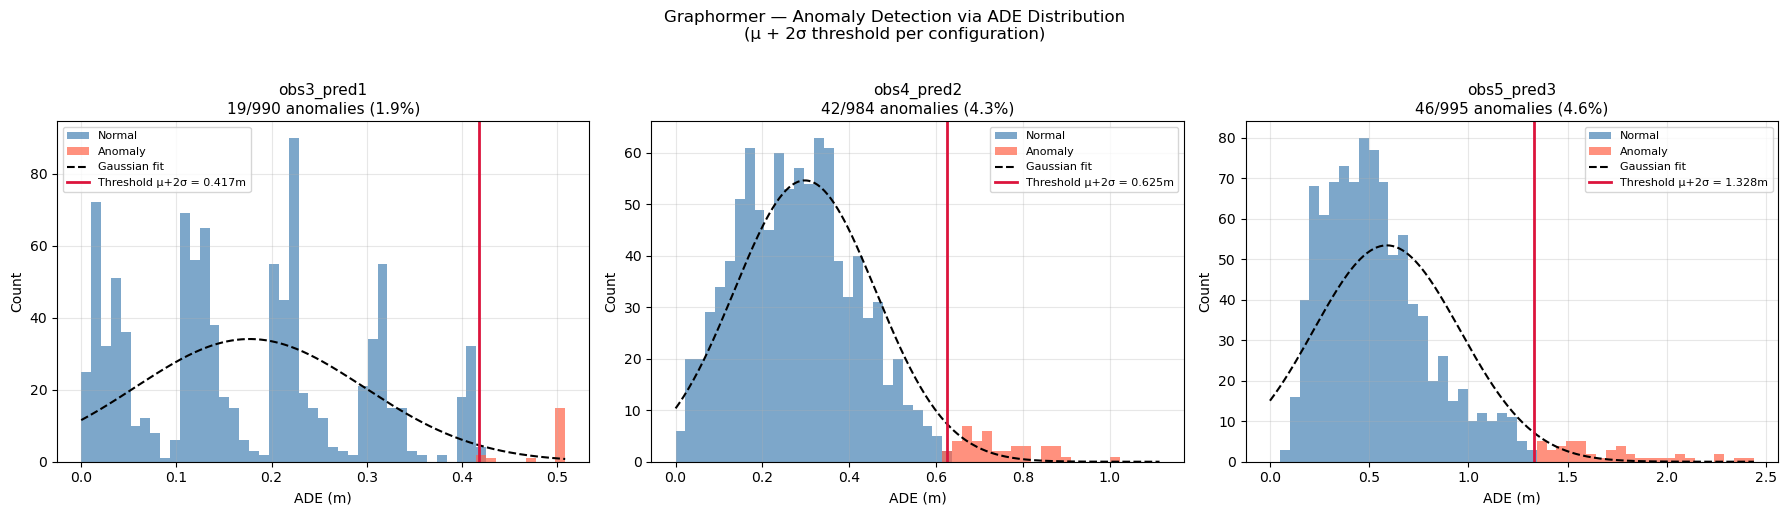

✓ Saved results/anomaly_detection.png

PER-CLASS ANOMALY RATE SUMMARY (all configs)
Config         Class          Total  Anomalies     Rate   Mean ADE
-----------------------------------------------------------------
obs3_pred1     Car              556         11     2.0%     0.1819
obs3_pred1     Pedestrian       269          7     2.6%     0.1686
obs3_pred1     Bicycle          165          1     0.6%     0.1731

obs4_pred2     Car              469         35     7.5%     0.3519
obs4_pred2     Pedestrian       338          1     0.3%     0.2311
obs4_pred2     Bicycle          177          6     3.4%     0.2821

obs5_pred3     Car              371         39    10.5%     0.7830
obs5_pred3     Pedestrian       458          0     0.0%     0.4282
obs5_pred3     Bicycle          166          7     4.2%     0.5967



In [34]:
# ============================================================================
# ANOMALY DETECTION — VISUALISATION
# One subplot per config: ADE histogram + Gaussian fit + threshold line
# ============================================================================

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.stats import norm as scipy_norm

fig, axes = plt.subplots(1, len(EXPERIMENT_CONFIGS),
                         figsize=(6 * len(EXPERIMENT_CONFIGS), 5))
if len(EXPERIMENT_CONFIGS) == 1:
    axes = [axes]

for ax, (obs_sec, pred_sec) in zip(axes, EXPERIMENT_CONFIGS):
    cfg = config_tag(obs_sec, pred_sec)
    if cfg not in anomaly_results:
        ax.set_title(f"{cfg} — no data")
        continue

    res    = anomaly_results[cfg]
    ades   = np.array(res['sample_ades'])
    mu     = res['mu']
    sigma  = res['sigma']
    thresh = res['threshold']
    classes = np.array(res['sample_classes'])

    # ── Histogram coloured by normal / anomalous ───────────────────────────
    bins = np.linspace(0, min(ades.max(), mu + 5 * sigma), 50)

    normal_ades  = ades[ades <= thresh]
    anomaly_ades = ades[ades >  thresh]

    ax.hist(normal_ades,  bins=bins, color='steelblue', alpha=0.7,
            label='Normal')
    ax.hist(anomaly_ades, bins=bins, color='tomato',    alpha=0.7,
            label='Anomaly')

    # ── Gaussian fit overlay ───────────────────────────────────────────────
    x_fit = np.linspace(0, bins[-1], 300)
    y_fit = scipy_norm.pdf(x_fit, mu, sigma) * len(ades) * (bins[1] - bins[0])
    ax.plot(x_fit, y_fit, 'k--', linewidth=1.5, label='Gaussian fit')

    # ── Threshold line ─────────────────────────────────────────────────────
    ax.axvline(thresh, color='crimson', linewidth=2,
               label=f'Threshold μ+2σ = {thresh:.3f}m')

    ax.set_title(f"{cfg}\n{res['n_anomaly']}/{res['n_total']} anomalies "
                 f"({res['anomaly_pct']:.1f}%)", fontsize=11)
    ax.set_xlabel('ADE (m)', fontsize=10)
    ax.set_ylabel('Count',   fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Graphormer — Anomaly Detection via ADE Distribution\n'
             '(μ + 2σ threshold per configuration)',
             fontsize=12, y=1.02)
plt.tight_layout()
os.makedirs('results', exist_ok=True)
plt.savefig('results/anomaly_detection.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Saved results/anomaly_detection.png")

# ── Per-class anomaly rate summary across all configs ─────────────────────
print(f"\n{'='*70}")
print("PER-CLASS ANOMALY RATE SUMMARY (all configs)")
print(f"{'='*70}")
print(f"{'Config':<14} {'Class':<12} {'Total':>7} {'Anomalies':>10} "
      f"{'Rate':>8} {'Mean ADE':>10}")
print(f"{'-'*65}")

for cfg, res in anomaly_results.items():
    for cls, cs in res['per_class'].items():
        print(f"{cfg:<14} {cls:<12} {cs['n']:>7} {cs['n_anomaly']:>10} "
              f"{cs['anomaly_pct']:>7.1f}% {cs['mean_ade']:>10.4f}")
    print()